# [기초-실습] 통계 101×데이터 분석: (1-3장): 통계분석의 기초

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Fetched 10.3 MB in 0s (23.0 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories curr

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 기초통계량 계산

**📘 문제**

- 온라인 쇼핑몰 고객 1,000명을 대상으로 1점부터 10점 사이의 만족도 조사를 실시했습니다.
  이 데이터를 바탕으로 고객 만족도의 **중심 경향성**과 **분포 특성**을 파악해 봅시다.

In [3]:
# 데이터 생성
import numpy as np
import pandas as pd

np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})

**📌 아래를 수행해 보세요:**

- 평균, 중앙값, 최빈값, 표준편차를 계산해 봅시다.
- 히스토그램을 그리고 평균과 중앙값 선으로 표시해 봅시다.
- 데이터의 분포 형태를 해석한 후, 마케팅 전략 수립에 어떻게 활용할 수 있을지 생각해 봅시다.

평균: 7.43
중앙값: 7.42
최빈값(정수 반올림 기준): 7.0
표준편차: 1.39
분산: 1.94
최소·최대: 2.72 ~ 10.0
사분위수 Q1·Q3: 6.47 ~ 8.44
IQR: 1.97
왜도: -0.17
첨도: -0.27
10점 응답 수: 44


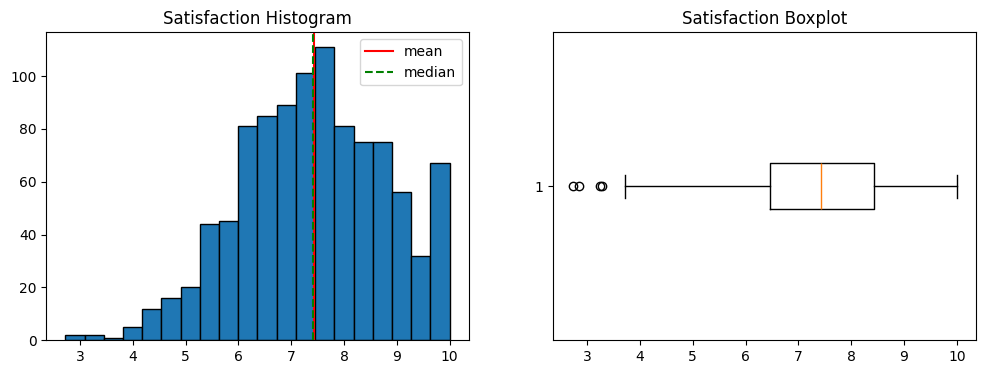

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})
x = df1['score']

# 중심 경향성
print("평균:", round(x.mean(), 2))
print("중앙값:", round(x.median(), 2))
print("최빈값(정수 반올림 기준):", x.round().mode()[0])

# 산포도
print("표준편차:", round(x.std(), 2))
print("분산:", round(x.var(), 2))
print("최소·최대:", round(x.min(), 2), "~", round(x.max(), 2))
print("사분위수 Q1·Q3:", round(x.quantile(0.25), 2), "~", round(x.quantile(0.75), 2))
print("IQR:", round(x.quantile(0.75) - x.quantile(0.25), 2))

# 분포 모양
print("왜도:", round(x.skew(), 2))
print("첨도:", round(x.kurt(), 2))
print("10점 응답 수:", (x == 10).sum())

# 시각화
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(x, bins=20, edgecolor='black')
ax[0].axvline(x.mean(), color='red', label='mean')
ax[0].axvline(x.median(), color='green', linestyle='--', label='median')
ax[0].set_title('Satisfaction Histogram')
ax[0].legend()
ax[1].boxplot(x, vert=False)
ax[1].set_title('Satisfaction Boxplot')
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 평균과 중앙값 사이의 차이는 어느 정도인가요?
   - 두 값이 비슷하다면, 이 데이터는 어떤 분포 형태일 가능성이 있을까요? (예: 대칭형, 정규분포 등)
   - 두 값의 차이가 크다면, 그 이유는 무엇일까요?
   - 어떤 값들이 평균을 끌어내리거나 끌어올렸을까요?

2. 최빈값이 평균보다 낮은 경우, 낮은 점수를 준 고객이 많다는 뜻일 수 있습니다. 이 경우 데이터 분포는 어느 쪽으로 치우쳐 있을까요?
   - 반대로 최빈값이 평균보다 높은 경우에는 어떤 해석이 가능할까요? 이럴 때 분포가 어떻게 달라질 수 있을까요?

3. 이 데이터를 바탕으로 고객 만족도를 높이기 위한 마케팅 전략에는 어떤 것들이 있을까요?

In [5]:
# 데이터를 어떻게 읽을까요?
# [문제 1] 여기에 의견을 작성해주세요.

: [0;36m  File [0;32m"/tmp/ipykernel_1084/2201649391.py"[0;36m, line [0;32m1[0m
[0;31m    실행 결과(평균 7.43, 중앙값 7.42, 최빈값 7점, 표준편차 1.39, 왜도 -0.17)를 바탕으로 질문 순서대로 답하겠습니다.[0m
[0m       ^[0m
[0;31mSyntaxError[0m[0;31m:[0m invalid syntax


실행 결과(평균 7.43, 중앙값 7.42, 최빈값 7점, 표준편차 1.39, 왜도 -0.17)를 바탕으로 질문 순서대로 답하겠습니다.

1. 평균과 중앙값의 차이

차이는 0.01점(7.43 vs 7.42)으로 거의 없습니다.

두 값이 비슷할 때: 좌우가 대칭인 분포일 가능성이 높습니다. 이 데이터도 정규분포에 가까운 대칭형입니다. 실제로 정규분포(평균 7.5, 표준편차 1.5)로 만든 데이터라 예상과 맞는 결과입니다.
두 값의 차이가 클 때: 한쪽에 극단값이 몰려 있다는 뜻입니다. 평균은 모든 값의 영향을 받지만, 중앙값은 순서상 가운데 값이라 극단값의 영향을 거의 받지 않기 때문입니다.
평균을 움직이는 값: 이 데이터에서는 2~3점대의 소수 저점수(최소 2.72)가 평균을 아주 약간 끌어내렸습니다. 반대로 10점으로 잘린 44명은 평균이 더 올라가지 못하게 막았습니다. 두 효과가 작아서 평균과 중앙값이 거의 같게 나왔습니다.
2. 최빈값과 평균의 관계로 본 치우침
최빈값 < 평균: 대부분의 고객이 낮은 점수에 몰려 있고, 소수의 높은 점수가 평균을 끌어올린 경우입니다. 꼬리가 오른쪽(높은 점수 쪽)으로 길게 늘어진 **오른쪽 꼬리 분포(양의 왜도)**입니다.
최빈값 > 평균: 대부분의 고객이 높은 점수를 줬고, 소수의 낮은 점수가 평균을 끌어내린 경우입니다. 꼬리가 왼쪽으로 긴 **왼쪽 꼬리 분포(음의 왜도)**입니다. 전반적으로는 만족하지만 일부 불만 고객이 있는 상황으로 해석할 수 있습니다.
이 데이터의 경우: 최빈값 7점이 평균 7.43보다 낮게 나왔지만, 이는 연속값을 정수로 반올림하면서 생긴 차이라 큰 의미는 없습니다. 분포의 치우침은 왜도로 판단하는 게 정확합니다. 왜도가 -0.17로 0에 가까워 사실상 대칭이고, 낮은 점수 쪽 꼬리가 아주 약간 깁니다.
3. 만족도를 높이기 위한 마케팅 전략
고객 구간	데이터 근거	전략
불만 위험 고객 (하위 25%)	6.47점 이하, 약 250명	이탈 위험이 큰 층입니다. 불만 원인 설문, 사과 쿠폰, 고객센터 우선 응대로 이탈을 막습니다.
보통 만족 고객 (중간 50%)	6.5~8.4점, 약 500명	가장 큰 집단입니다. "만족하지만 열광하지는 않는" 층이라, 멤버십 혜택이나 개인화 추천으로 9~10점 충성 고객으로 끌어올리는 것이 핵심입니다.
충성 고객 (상위)	10점 응답 44명 포함	리뷰 작성 보상, 친구 추천 프로그램, VIP 혜택으로 입소문을 만듭니다.

결론: 평균 7.4점으로 전반적 만족도는 높은 편이지만, 응답이 7~8점대에 몰려 있습니다. 따라서 "불만 고객 관리"보다 "보통 만족 고객을 충성 고객으로 전환"하는 데 집중하는 전략이 효과가 클 것입니다.

# 문제 2. 평균 vs 중앙값 비교

**📘 문제**

- A지역과 B지역의 연봉 데이터를 비교해 봅시다.
- B 지역에는 일부 고소득자가 포함되어 있습니다.

In [6]:
# 데이터 생성
np.random.seed(2025)

# A 지역: 평균 300, 표준편차 50
region_a = np.random.normal(300, 50, 100)

# B 지역: 일반 소득자 + 극단적인 고소득자 포함
region_b = np.concatenate([
    np.random.normal(280, 40, 95),    # 일반 소득자 95명
    np.random.normal(1500, 200, 5)    # 고소득자 5명
])

df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

**📌 아래를 수행해 보세요:**

- 각 지역의 평균 연봉과 중앙값을 구해 봅시다.
- 지역별 박스플롯(Boxplot)을 그려서 분포의 차이를 시각적으로 확인해 봅시다.

         mean  median    std    min     max
region                                     
A       292.5   294.3   46.5  189.4   407.3
B       347.6   287.3  290.4  189.6  1709.9


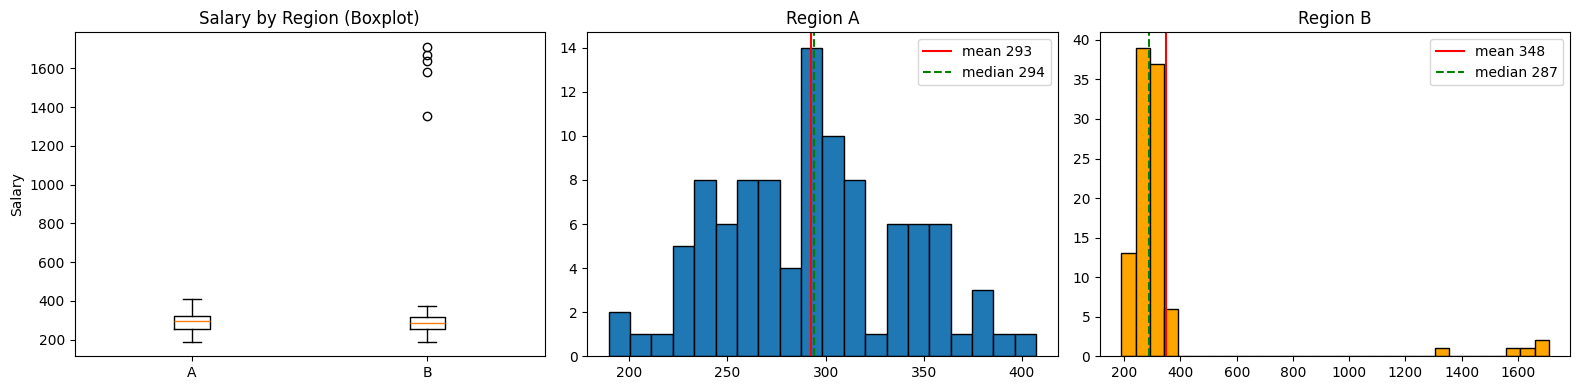

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 데이터 생성
np.random.seed(2025)
region_a = np.random.normal(300, 50, 100)
region_b = np.concatenate([
    np.random.normal(280, 40, 95),
    np.random.normal(1500, 200, 5)
])
df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

a = df2[df2['region'] == 'A']['salary']
b = df2[df2['region'] == 'B']['salary']

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# 1) 지역별 박스플롯
ax[0].boxplot([a, b], labels=['A', 'B'])
ax[0].set_title('Salary by Region (Boxplot)')
ax[0].set_ylabel('Salary')

# 2) A 지역 히스토그램 + 평균·중앙값
ax[1].hist(a, bins=20, edgecolor='black')
ax[1].axvline(a.mean(), color='red', label=f'mean {a.mean():.0f}')
ax[1].axvline(a.median(), color='green', linestyle='--', label=f'median {a.median():.0f}')
ax[1].set_title('Region A')
ax[1].legend()

# 3) B 지역 히스토그램 + 평균·중앙값
ax[2].hist(b, bins=30, edgecolor='black', color='orange')
ax[2].axvline(b.mean(), color='red', label=f'mean {b.mean():.0f}')
ax[2].axvline(b.median(), color='green', linestyle='--', label=f'median {b.median():.0f}')
ax[2].set_title('Region B')
ax[2].legend()

plt.tight_layout()
plt.show()

# 숫자로도 비교
print(df2.groupby('region')['salary'].agg(['mean', 'median', 'std', 'min', 'max']).round(1))

**🧠 데이터를 어떻게 읽을까요?**

1. A 지역과 B 지역의 평균 연봉은 어떻게 다른가요?
   - 두 지역의 평균 차이가 의미하는 바는 무엇인가요?
   - 고소득자가 있는 지역의 평균은 어떤 영향을 받을까요?

2. 중앙값은 어떠한가요?
   - 평균과 비교했을 때, 중앙값이 더 낮거나 높다면 어떤 해석이 가능할까요?

3. 극단값(고소득자)의 영향은 어디에서 더 크게 나타날까요?
   - 평균과 중앙값 중 어떤 지표가 극단값에 더 민감한가요?

4. 박스플롯을 통해 어떤 점을 관찰할 수 있나요?
   - 이상치(Outlier)는 어떻게 표시되나요?
   - 두 지역의 분포 폭(사분위 범위)은 어떻게 다른가요?

5. 평균만 보고 판단했을 때 생길 수 있는 오해는 무엇인가요?
   - 어떤 경우에는 중앙값이 더 유용한 지표일 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 2] 여기에 의견을 작성해주세요.

핵심은 "평균만 보면 B 지역이 더 잘사는 것처럼 보이지만, 실제로는 그렇지 않다"는 점입니다. 실제 실행 결과는 다음과 같습니다.

지역	평균	중앙값	표준편차	최소	최대	왜도
A	292.5	294.3	46.5	189.4	407.3	0.2
B	347.6	287.3	290.4	189.6	1709.9	4.1
1. 평균과 중앙값 비교
A 지역: 평균 292.5와 중앙값 294.3이 거의 같습니다. 극단값이 없는 대칭 분포입니다.
B 지역: 평균 347.6이 중앙값 287.3보다 약 60 높습니다. 고소득자 5명(1,354~1,710)이 평균을 크게 끌어올렸기 때문입니다.
고소득자 5명을 빼면 B 지역 평균은 282.2로, 오히려 A 지역보다 낮아집니다.
2. 그래프로 읽기
박스플롯: 두 지역의 박스(가운데 50% 구간) 높이는 비슷합니다. 하지만 B 지역 위쪽에 점 5개가 따로 떨어져 있습니다. 이 점들이 이상치, 즉 고소득자입니다. 실제로 사분위 범위(IQR) 기준으로 계산해도 이상치는 B 지역에서만 5개가 나옵니다.
B 지역 히스토그램: 대부분 200~400 사이에 몰려 있고, 오른쪽 멀리 1,300~1,700에 막대가 몇 개 떨어져 있습니다. 평균선(빨간색)이 중앙값선(초록색)보다 오른쪽으로 끌려가 있는 것이 보입니다.
3. 분포 특성
표준편차: B 지역이 290.4로 A 지역(46.5)의 6배가 넘습니다. 일반 소득자끼리는 비슷하지만 극단값 몇 개가 퍼짐을 크게 키웠습니다.
왜도: B 지역이 4.1로, 꼬리가 오른쪽으로 아주 길게 늘어진 분포입니다. A 지역은 0.2로 거의 대칭입니다.
4. 결론
평균만 보면 “B 지역 소득이 더 높다”는 잘못된 결론이 나옵니다.
대표값으로 중앙값을 쓰면 두 지역의 일반 주민 소득은 비슷합니다(294 vs 287). 오히려 A 지역이 약간 높습니다.
소득처럼 극단값이 있는 데이터는 평균보다 중앙값이 집단을 더 잘 대표합니다. 실제 국가 소득 통계에서 '중위소득'을 쓰는 이유도 이 때문입니다.

# 문제 3. 이상값과 분산 비교

**📘 문제**

- 1반과 2반의 시험 점수 분포를 비교해 봅시다.
- 2반에는 극단적인 이상값(예: 부정행위로 0점)이 포함되어 있습니다.

In [33]:
# 데이터 생성
np.random.seed(2025)  # 재현 가능성을 위해 시드 고정

# 1반: 평균 75, 표준편차 8
class1 = np.random.normal(75, 8, 30)

# 2반: 일반 학생 + 이상값(0점, 130점)
class2 = np.concatenate([
    np.random.normal(75, 15, 28),  # 일반 학생
    [0, 130]                       # 극단적인 이상값
])

df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**📌 아래를 수행해 보세요:**

1. 각 반의 평균, 표준편차, 최소/최대값을 계산해 봅시다.
2. 박스플롯을 사용하여 두 반의 분포 차이를 시각적으로 비교해 봅시다.
3. 이상값이 통계 지표에 어떤 영향을 주는지 생각해 봅시다.

[반별 통계]
        mean  median    std    min     max
class                                     
1반    75.72   74.75   7.06  60.69   92.18
2반    73.73   73.00  22.34   0.00  130.00

1반 이상값 기준: 62.2 미만 또는 92.0 초과 → [92.2, 60.7]

2반 이상값 기준: 19.3 미만 또는 129.8 초과 → [0.0, 130.0]

[이상값 영향 비교]
        2반 (이상값 포함)  2반 (이상값 제외)  변화량
mean                73.73              74.35   -0.62
median              73.00              73.00    0.00
std                 22.34              14.73    7.61
min                  0.00              54.10  -54.10
max                130.00             103.52   26.48


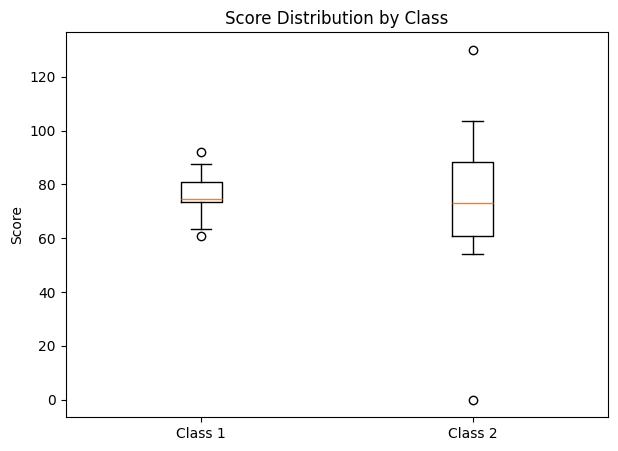

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 데이터 생성
np.random.seed(2025)
class1 = np.random.normal(75, 8, 30)
class2 = np.concatenate([np.random.normal(75, 15, 28), [0, 130]])
df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

# 0. 반별 평균·표준편차·최소·최대
stats = df3.groupby('class')['score'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
print("[반별 통계]")
print(stats)

# 1. 박스플롯 비교
c1 = df3[df3['class'] == '1반']['score']
c2 = df3[df3['class'] == '2반']['score']
plt.figure(figsize=(7, 5))
plt.boxplot([c1, c2])
plt.xticks([1, 2], ['Class 1', 'Class 2'])
plt.title('Score Distribution by Class')
plt.ylabel('Score')
plt.show()

# 2. 이상값의 영향
# 2-1) IQR 기준으로 이상값 찾기
def find_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < low) | (s > high)], low, high

for name, s in [('1반', c1), ('2반', c2)]:
    out, low, high = find_outliers(s)
    print(f"\n{name} 이상값 기준: {low:.1f} 미만 또는 {high:.1f} 초과 → {out.round(1).tolist()}")

# 2-2) 2반에서 이상값(0, 130)을 뺐을 때와 비교
c2_clean = c2[~c2.isin([0, 130])]
compare = pd.DataFrame({
    '2반 (이상값 포함)': c2.agg(['mean', 'median', 'std', 'min', 'max']),
    '2반 (이상값 제외)': c2_clean.agg(['mean', 'median', 'std', 'min', 'max']),
}).round(2)
compare['변화량'] = (compare['2반 (이상값 포함)'] - compare['2반 (이상값 제외)']).round(2)
print("\n[이상값 영향 비교]")
print(compare)

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
   - 점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
   - 이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?

2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?
   - 극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
   - 평균과 중앙값의 차이가 의미하는 바는 무엇인가요?

3. 박스플롯을 통해 이상값은 어떻게 드러나나요?
   - 이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
   - 두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?

4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?
   - 예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
   - 중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?


══════════════════════════════════════════════════════════════════════
1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
══════════════════════════════════════════════════════════════════════
          Class 1  Class 2  Class 2 (no 0 & 130)
분산        49.88   499.11                217.07
표준편차     7.06    22.34                 14.73
범위        31.49   130.00                 49.42
IQR          7.46    27.61                 26.79

[답] 2반의 분산이 훨씬 큽니다. 2반 분산은 499.1로 1반(49.9)의 약 10배입니다.
     이유는 두 가지입니다.
     · 원래 실력 편차가 큼: 2반은 일반 학생도 더 넓게 퍼져 있어, 이상값을 빼도 분산이 217.1로 1반의 약 4배입니다.
     · 이상값 2개: 0점과 130점이 더해지면서 분산이 217.1에서 499.1로 2배 넘게 커졌습니다.

▸점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
     · 분산과 표준편차: 점수가 평균에서 평균적으로 얼마나 떨어져 있는지 (표준편차는 점수와 같은 단위라 해석이 쉬움)
     · 범위: 최고점 − 최저점
     · IQR: 가운데 50% 학생이 퍼진 폭 (Q3 − Q1)
     · 그래프: 히스토그램과 박스플롯으로 퍼짐을 눈으로 확인

▸이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?
     · 범위: 49.4 → 130.0로 2.6배. 이상값이 그대로 최소·최대가 되므로 가장 크게 왜곡됩니다.
     · 표준편차: 14.73 → 22.34로 약 52% 증가. 평균과의 거리를 제곱해서 계산해 멀리 떨어진 값의 영향이 큽니다.
     

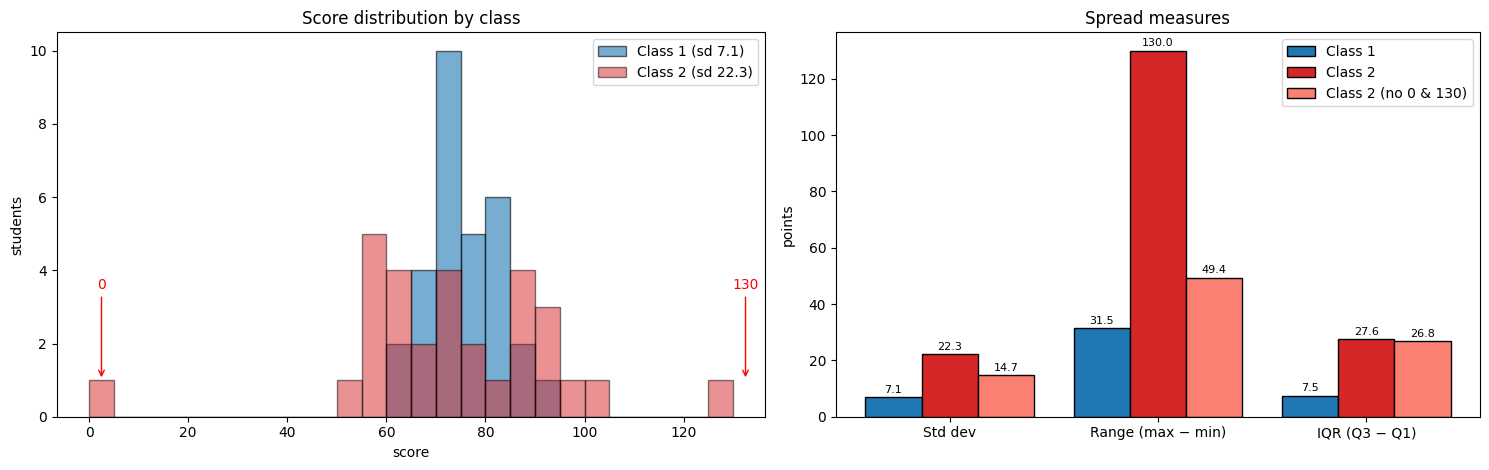

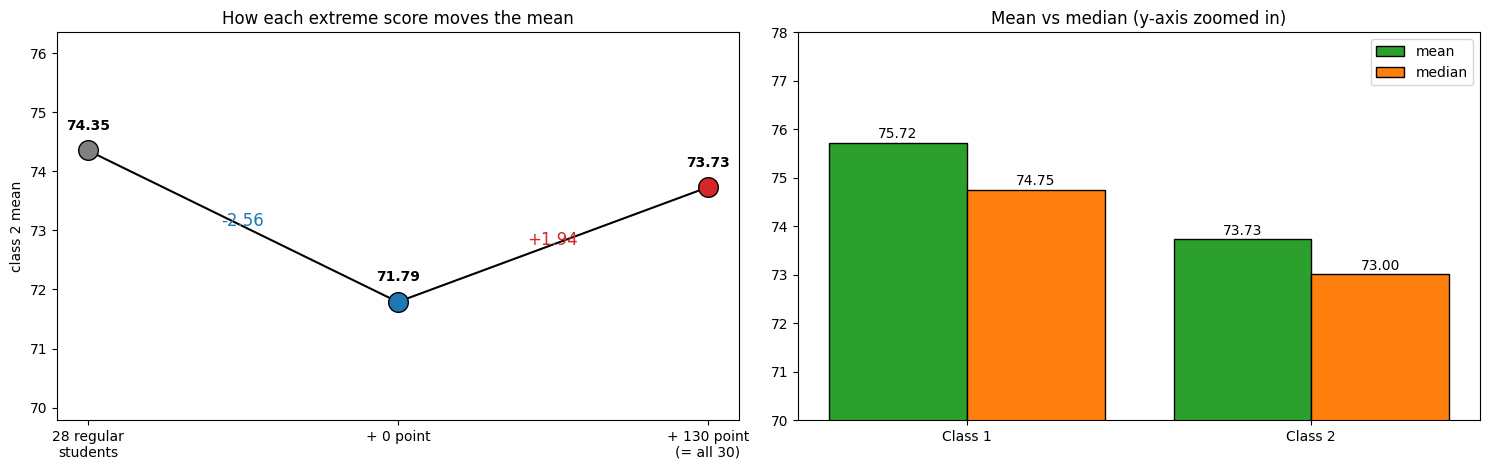

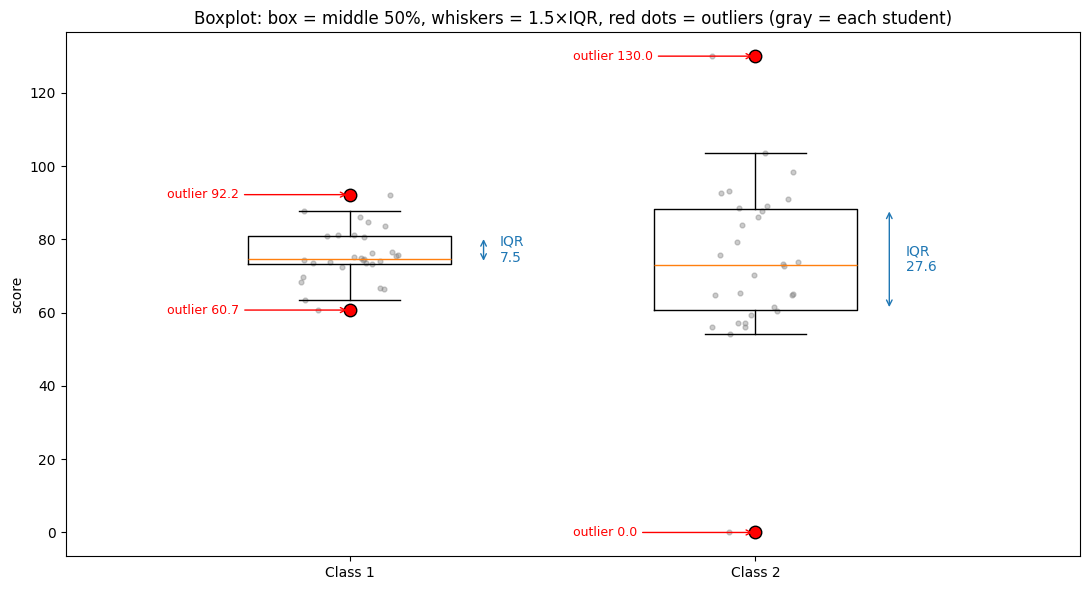

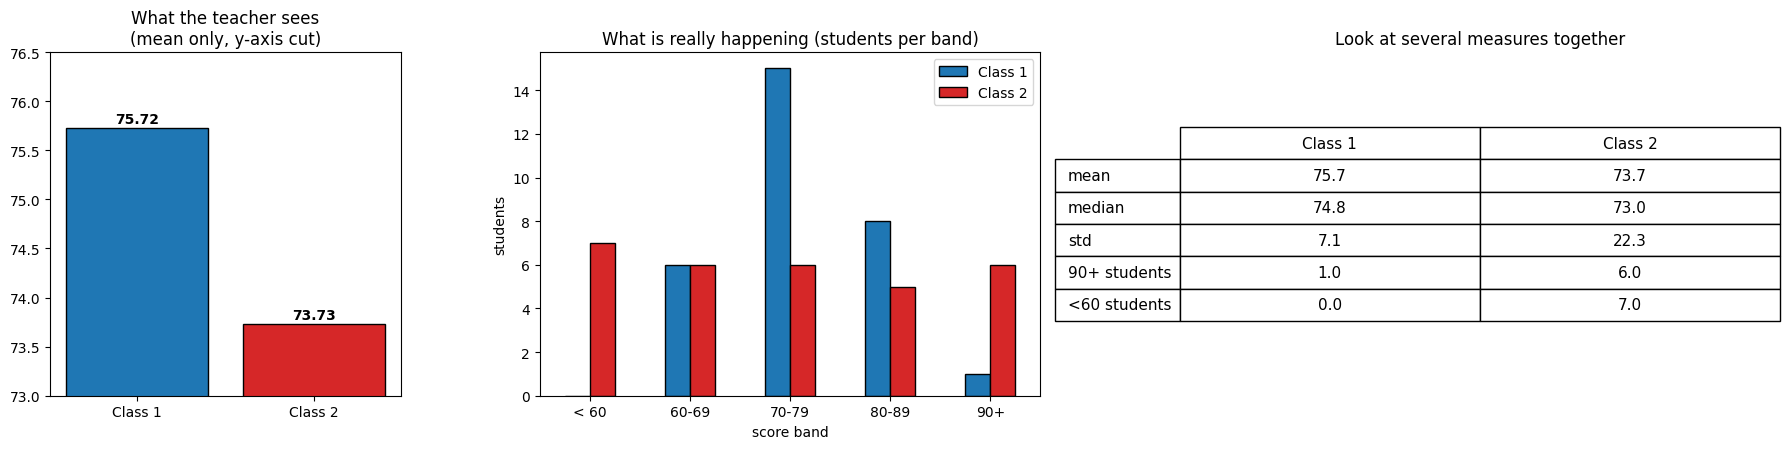

In [32]:
# ═══════════════ [셀 1] 준비 + 데이터 생성 ═══════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)

np.random.seed(2025)
class1 = np.random.normal(75, 8, 30)
class2 = np.concatenate([np.random.normal(75, 15, 28), [0, 130]])
df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

c1 = df3.loc[df3['class'] == '1반', 'score'].reset_index(drop=True)
c2 = df3.loc[df3['class'] == '2반', 'score'].reset_index(drop=True)
c2_clean = c2[~c2.isin([0, 130])]
G = {'Class 1': c1, 'Class 2': c2, 'Class 2 (no 0 & 130)': c2_clean}
COL = {'Class 1': 'tab:blue', 'Class 2': 'tab:red', 'Class 2 (no 0 & 130)': 'salmon'}

def spread(s):
    return {'분산': s.var(), '표준편차': s.std(), '범위': s.max() - s.min(),
            'IQR': s.quantile(0.75) - s.quantile(0.25)}

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═══════════════ [셀 2] 1. 어떤 반의 분산이 더 큰가 ═══════════════
header("1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?")

sp = pd.DataFrame({k: spread(v) for k, v in G.items()}).round(2)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
bins = np.arange(0, 135, 5)
ax[0].hist(c1, bins=bins, alpha=0.6, color='tab:blue', edgecolor='black', label=f'Class 1 (sd {c1.std():.1f})')
ax[0].hist(c2, bins=bins, alpha=0.5, color='tab:red', edgecolor='black', label=f'Class 2 (sd {c2.std():.1f})')
for v in [0, 130]:
    ax[0].annotate(f'{v}', (v + 2.5, 1), xytext=(v + 2.5, 3.5), ha='center', color='red',
                   arrowprops=dict(arrowstyle='->', color='red'))
ax[0].set_xlabel('score')
ax[0].set_ylabel('students')
ax[0].set_title('Score distribution by class')
ax[0].legend()
metrics = ['표준편차', '범위', 'IQR']
xpos = np.arange(len(metrics))
for j, k in enumerate(G):
    vals = [sp.loc[m, k] for m in metrics]
    bars = ax[1].bar(xpos + (j - 1) * 0.27, vals, width=0.27, color=COL[k], edgecolor='black', label=k)
    for b, v in zip(bars, vals):
        ax[1].text(b.get_x() + b.get_width() / 2, v + 1.5, f'{v:.1f}', ha='center', fontsize=8)
ax[1].set_xticks(xpos)
ax[1].set_xticklabels(['Std dev', 'Range (max − min)', 'IQR (Q3 − Q1)'])
ax[1].set_ylabel('points')
ax[1].set_title('Spread measures')
ax[1].legend()
plt.tight_layout()
plt.show()

print(sp)
print(f"""
[답] 2반의 분산이 훨씬 큽니다. 2반 분산은 {sp.loc['분산', 'Class 2']:.1f}로 1반({sp.loc['분산', 'Class 1']:.1f})의 약 {sp.loc['분산', 'Class 2'] / sp.loc['분산', 'Class 1']:.0f}배입니다.
     이유는 두 가지입니다.
     · 원래 실력 편차가 큼: 2반은 일반 학생도 더 넓게 퍼져 있어, 이상값을 빼도 분산이 {sp.loc['분산', 'Class 2 (no 0 & 130)']:.1f}로 1반의 약 {sp.loc['분산', 'Class 2 (no 0 & 130)'] / sp.loc['분산', 'Class 1']:.0f}배입니다.
     · 이상값 2개: 0점과 130점이 더해지면서 분산이 {sp.loc['분산', 'Class 2 (no 0 & 130)']:.1f}에서 {sp.loc['분산', 'Class 2']:.1f}로 2배 넘게 커졌습니다.

▸점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
     · 분산과 표준편차: 점수가 평균에서 평균적으로 얼마나 떨어져 있는지 (표준편차는 점수와 같은 단위라 해석이 쉬움)
     · 범위: 최고점 − 최저점
     · IQR: 가운데 50% 학생이 퍼진 폭 (Q3 − Q1)
     · 그래프: 히스토그램과 박스플롯으로 퍼짐을 눈으로 확인

▸이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?
     · 범위: {sp.loc['범위', 'Class 2 (no 0 & 130)']:.1f} → {sp.loc['범위', 'Class 2']:.1f}로 {sp.loc['범위', 'Class 2'] / sp.loc['범위', 'Class 2 (no 0 & 130)']:.1f}배. 이상값이 그대로 최소·최대가 되므로 가장 크게 왜곡됩니다.
     · 표준편차: {sp.loc['표준편차', 'Class 2 (no 0 & 130)']:.2f} → {sp.loc['표준편차', 'Class 2']:.2f}로 약 {(sp.loc['표준편차', 'Class 2'] / sp.loc['표준편차', 'Class 2 (no 0 & 130)'] - 1) * 100:.0f}% 증가. 평균과의 거리를 제곱해서 계산해 멀리 떨어진 값의 영향이 큽니다.
     · IQR: {sp.loc['IQR', 'Class 2 (no 0 & 130)']:.1f} → {sp.loc['IQR', 'Class 2']:.1f}로 거의 그대로. 가운데 50%만 보므로 이상값에 강한 지표입니다.""")

# ═══════════════ [셀 3] 2. 이상값이 평균에 준 영향 ═══════════════
header("2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?")

m28 = c2_clean.mean()
m_plus0 = np.mean(np.r_[c2_clean, 0])
m_all = c2.mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
steps = [('28 regular\nstudents', m28), ('+ 0 point', m_plus0), ('+ 130 point\n(= all 30)', m_all)]
xs = np.arange(3)
ax[0].plot(xs, [s[1] for s in steps], marker='o', color='black', zorder=2)
for i, (lab, v) in enumerate(steps):
    ax[0].scatter(i, v, s=200, color=['gray', 'tab:blue', 'tab:red'][i], edgecolor='black', zorder=3)
    ax[0].text(i, v + 0.35, f'{v:.2f}', ha='center', fontweight='bold')
ax[0].annotate(f'{m_plus0 - m28:+.2f}', ((0 + 1) / 2, (m28 + m_plus0) / 2), color='tab:blue', ha='center', fontsize=12)
ax[0].annotate(f'{m_all - m_plus0:+.2f}', ((1 + 2) / 2, (m_plus0 + m_all) / 2), color='tab:red', ha='center', fontsize=12)
ax[0].set_xticks(xs)
ax[0].set_xticklabels([s[0] for s in steps])
ax[0].set_ylim(min(m28, m_plus0, m_all) - 2, max(m28, m_plus0, m_all) + 2)
ax[0].set_ylabel('class 2 mean')
ax[0].set_title('How each extreme score moves the mean')
xpos = np.arange(2)
ax[1].bar(xpos - 0.2, [c1.mean(), c2.mean()], width=0.4, color='tab:green', edgecolor='black', label='mean')
ax[1].bar(xpos + 0.2, [c1.median(), c2.median()], width=0.4, color='tab:orange', edgecolor='black', label='median')
for i, s in enumerate([c1, c2]):
    ax[1].text(i - 0.2, s.mean() + 0.1, f'{s.mean():.2f}', ha='center')
    ax[1].text(i + 0.2, s.median() + 0.1, f'{s.median():.2f}', ha='center')
ax[1].set_xticks(xpos)
ax[1].set_xticklabels(['Class 1', 'Class 2'])
ax[1].set_ylim(70, 78)
ax[1].set_title('Mean vs median (y-axis zoomed in)')
ax[1].legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({'평균': [c1.mean(), c2.mean(), m28], '중앙값': [c1.median(), c2.median(), c2_clean.median()]},
                   index=['1반', '2반 (전체)', '2반 (0·130 제외)']).round(2))
print(f"""
[답] 영향이 크지 않았습니다. 0점과 130점을 뺀 일반 학생 28명의 평균은 {m28:.2f}점이고, 두 값을 넣으면 {m_all:.2f}점으로 {m_all - m28:+.2f}점만 변합니다.

▸극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
     둘 다 했지만, 서로 반대 방향이라 대부분 상쇄되었습니다 (왼쪽 그래프).
     · 0점을 넣으면 평균이 {m28:.2f} → {m_plus0:.2f}점으로 {m_plus0 - m28:+.2f}점 끌려 내려가고,
     · 130점을 넣으면 다시 {m_plus0:.2f} → {m_all:.2f}점으로 {m_all - m_plus0:+.2f}점 끌려 올라갑니다.
     · 0점이 평균에서 더 멀리 떨어져 있어(약 {m28:.0f}점 아래 vs 약 {130 - m28:.0f}점 위) 내리는 힘이 조금 더 커서, 결과적으로 평균이 약간 내려갔습니다.
     이상값이 한쪽에만 있었다면 평균은 훨씬 크게 흔들렸을 것입니다.

▸평균과 중앙값의 차이가 의미하는 바는 무엇인가요?
     · 2반은 평균 {c2.mean():.2f}, 중앙값 {c2.median():.2f}으로 차이가 {c2.mean() - c2.median():.2f}점뿐입니다.
       두 값이 비슷하면 분포가 한쪽으로 크게 치우치지 않았다는 뜻입니다.
     · 평균이 중앙값보다 많이 낮으면 아래쪽에, 많이 높으면 위쪽에 극단값이나 긴 꼬리가 있다는 신호입니다.
     · 다만 2반처럼 양쪽 이상값이 상쇄되면 차이가 작게 나올 수 있어, 평균·중앙값 차이만으로 이상값이 없다고 판단하면 안 됩니다.""")

# ═══════════════ [셀 4] 3. 박스플롯으로 본 이상값 ═══════════════
header("3. 박스플롯을 통해 이상값은 어떻게 드러나나요?")

def box_stats(s):
    a, b = s.quantile(0.25), s.quantile(0.75)
    i = b - a
    lo, hi = a - 1.5 * i, b + 1.5 * i
    return a, b, i, lo, hi, s[(s < lo) | (s > hi)].round(1).tolist()

bs = {k: box_stats(G[k]) for k in ['Class 1', 'Class 2']}

fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot([c1, c2], widths=0.5, flierprops=dict(marker='o', markerfacecolor='red', markersize=9))
rng = np.random.default_rng(0)
for i, s in enumerate([c1, c2], start=1):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(s)), s, s=12, alpha=0.4, color='gray', zorder=1)
for i, k in enumerate(['Class 1', 'Class 2'], start=1):
    a, b, iq, lo, hi, outs = bs[k]
    ax.annotate('', xy=(i + 0.33, a), xytext=(i + 0.33, b), arrowprops=dict(arrowstyle='<->', color='tab:blue'))
    ax.text(i + 0.37, (a + b) / 2, f'IQR\n{iq:.1f}', color='tab:blue', va='center', fontsize=10)
    for v in outs:
        ax.annotate(f'outlier {v}', (i, v), xytext=(i - 0.45, v), fontsize=9, color='red', va='center',
                    arrowprops=dict(arrowstyle='->', color='red'))
ax.set_xticks([1, 2])
ax.set_xticklabels(['Class 1', 'Class 2'])
ax.set_xlim(0.3, 2.8)
ax.set_ylabel('score')
ax.set_title('Boxplot: box = middle 50%, whiskers = 1.5×IQR, red dots = outliers (gray = each student)')
plt.tight_layout()
plt.show()

print(pd.DataFrame({k: {'Q1': round(v[0], 1), 'Q3': round(v[1], 1), 'IQR(박스 길이)': round(v[2], 1),
                        '하한': round(v[3], 1), '상한': round(v[4], 1), '이상값': v[5]} for k, v in bs.items()}))
print(f"""
▸이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
[답] 수염(위아래 선) 바깥에 따로 떨어진 점으로 나타납니다.
     수염은 박스에서 IQR의 1.5배까지만 뻗고, 그보다 멀리 있는 값은 점으로 따로 찍힙니다.
     2반은 아래쪽 0점과 위쪽 130점이 빨간 점으로 뚜렷하게 떨어져 보입니다 (기준: {bs['Class 2'][3]:.1f}점 미만, {bs['Class 2'][4]:.1f}점 초과).
     참고로 1반도 {bs['Class 1'][5]}점이 기준선({bs['Class 1'][3]:.1f}, {bs['Class 1'][4]:.1f})을 살짝 넘어 점으로 찍히지만,
     이는 박스가 좁아서 생긴 것일 뿐 정상 범위의 학생으로 보는 것이 맞습니다.

▸두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?
[답] · 1반 박스: {bs['Class 1'][0]:.1f} ~ {bs['Class 1'][1]:.1f}점, 길이 {bs['Class 1'][2]:.1f}점으로 짧고 촘촘합니다. 학생 절반이 이 좁은 구간에 모여 있습니다.
     · 2반 박스: {bs['Class 2'][0]:.1f} ~ {bs['Class 2'][1]:.1f}점, 길이 {bs['Class 2'][2]:.1f}점으로 1반의 약 {bs['Class 2'][2] / bs['Class 1'][2]:.1f}배입니다.
     · 즉 2반은 이상값을 빼고 봐도 학생들 사이 실력 차이가 큰 반입니다. 회색 점(학생 한 명 한 명)도 2반이 훨씬 넓게 흩어져 있습니다.""")

# ═══════════════ [셀 5] 4. 평균만 볼 때의 오해 ═══════════════
header("4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?")

bands = [0, 60, 70, 80, 90, 200]
band_lab = ['< 60', '60-69', '70-79', '80-89', '90+']
cnt = pd.DataFrame({k: pd.cut(G[k], bands, labels=band_lab, right=False).value_counts().reindex(band_lab)
                    for k in ['Class 1', 'Class 2']})

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={'width_ratios': [0.7, 1, 1.2]})
ax[0].bar(['Class 1', 'Class 2'], [c1.mean(), c2.mean()], color=['tab:blue', 'tab:red'], edgecolor='black')
ax[0].set_ylim(73, 76.5)
for i, m in enumerate([c1.mean(), c2.mean()]):
    ax[0].text(i, m + 0.05, f'{m:.2f}', ha='center', fontweight='bold')
ax[0].set_title('What the teacher sees\n(mean only, y-axis cut)')
cnt.plot(kind='bar', ax=ax[1], color=['tab:blue', 'tab:red'], edgecolor='black')
ax[1].set_xlabel('score band')
ax[1].set_ylabel('students')
ax[1].tick_params(axis='x', rotation=0)
ax[1].set_title('What is really happening (students per band)')
summary_tbl = pd.DataFrame({'Class 1': [c1.mean(), c1.median(), c1.std(), (c1 >= 90).sum(), (c1 < 60).sum()],
                            'Class 2': [c2.mean(), c2.median(), c2.std(), (c2 >= 90).sum(), (c2 < 60).sum()]},
                           index=['mean', 'median', 'std', '90+ students', '<60 students']).round(1)
ax[2].axis('off')
t = ax[2].table(cellText=summary_tbl.values, rowLabels=summary_tbl.index, colLabels=summary_tbl.columns,
                loc='center', cellLoc='center')
t.scale(1, 2)
t.set_fontsize(11)
ax[2].set_title('Look at several measures together')
plt.tight_layout()
plt.show()

print(cnt.rename(columns={'Class 1': '1반', 'Class 2': '2반'}))
print(f"""
▸예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
[답] 잘못된 판단일 가능성이 높습니다.
     · 평균은 1반 {c1.mean():.2f}, 2반 {c2.mean():.2f}로 {c1.mean() - c2.mean():.1f}점 차이지만, 중앙값도 {c1.median():.2f} vs {c2.median():.2f}로 비슷해 '보통 학생'의 실력은 큰 차이가 없습니다.
     · 가운데 그래프를 보면 2반의 진짜 특징은 '부족함'이 아니라 '양극화'입니다.
       2반은 90점 이상이 {(c2 >= 90).sum()}명(1반 {(c1 >= 90).sum()}명)으로 상위권이 더 많고, 60점 미만도 {(c2 < 60).sum()}명(1반 {(c1 < 60).sum()}명)으로 하위권도 더 많습니다.
     · 평균만 보고 '2반 전체 보충 수업'을 하면, 이미 잘하는 상위권 학생에게는 불필요하고 정작 하위권 학생은 충분한 도움을 받지 못할 수 있습니다.
     · 또 평균에는 0점(결시일 수 있음)과 130점(만점 초과, 입력 오류 의심)이 섞여 있어, 데이터 오류를 먼저 확인해야 합니다.

▸중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?
[답] 지표마다 보여 주는 정보가 다르기 때문입니다.
     · 평균: 전체 수준 (이상값에 흔들림)
     · 중앙값: 이상값에 흔들리지 않는 '보통 학생'의 수준
     · 표준편차·IQR: 학생 간 실력 차이 (2반 표준편차 {c2.std():.1f}는 1반 {c1.std():.1f}의 약 {c2.std() / c1.std():.0f}배)
     · 분포 그래프: 상위권·하위권이 어디에 몇 명 있는지
     함께 보면 '1반은 고르게 중상위권, 2반은 실력 차이가 크니 수준별 지도가 필요하다'처럼 정확하고 실행 가능한 결론을 내릴 수 있습니다.""")

# 문제 4. IQR 이상값 제거

**📘 문제**

- 앞의 문제에서 2반에는 **극단적인 이상값(예: 매우 낮은 점수)**이 포함되어 있어
  통계 지표, 특히 평균에 큰 영향을 주는 것을 확인했습니다.
- 이번에는 **IQR(사분위 범위)**을 기준으로 이상값을 제거한 뒤, 이상값 제거 전후의 평균을 비교해 봅시다

<br>

**📌 아래를 수행해 보세요:**

- 2반의 점수 데이터를 대상으로 IQR 기준을 사용해 이상값을 판별하고 제거해 봅시다.
- 이상값 제거 전과 제거 후의 평균을 각각 계산해 봅시다.
- 이상값 제거가 평균에 어떤 영향을 주는지 설명해 봅시다.
- 필요하다면 중앙값과도 비교해 봅시다.

Q1 = 60.75, Q3 = 88.37, IQR = 27.61
이상값 기준: 19.33 미만 또는 129.79 초과
판별된 이상값: [0.0, 130.0]
학생 수: 제거 전 30명 → 제거 후 28명
        제거 전  제거 후  변화량
평균      73.73    74.35    0.62
중앙값    73.00    73.00    0.00


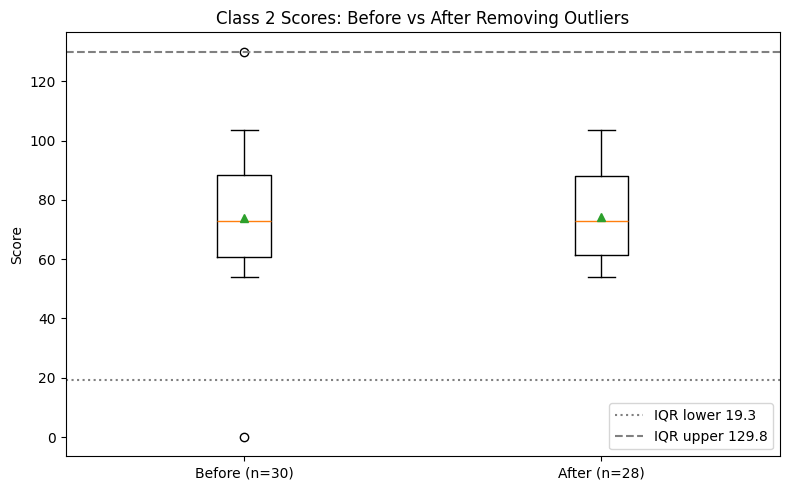

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 데이터 생성
np.random.seed(2025)
class1 = np.random.normal(75, 8, 30)
class2 = np.concatenate([np.random.normal(75, 15, 28), [0, 130]])
df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

# 2반 점수만 추출
c2 = df3[df3['class'] == '2반']['score']

# 1) IQR 기준 계산
q1 = c2.quantile(0.25)
q3 = c2.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"이상값 기준: {lower:.2f} 미만 또는 {upper:.2f} 초과")

# 2) 이상값 판별
outliers = c2[(c2 < lower) | (c2 > upper)]
print("판별된 이상값:", outliers.round(2).tolist())

# 3) 이상값 제거
c2_clean = c2[(c2 >= lower) & (c2 <= upper)]
print(f"학생 수: 제거 전 {len(c2)}명 → 제거 후 {len(c2_clean)}명")

# 4) 제거 전·후 평균과 중앙값 비교
result = pd.DataFrame({
    '제거 전': [c2.mean(), c2.median()],
    '제거 후': [c2_clean.mean(), c2_clean.median()]
}, index=['평균', '중앙값']).round(2)
result['변화량'] = (result['제거 후'] - result['제거 전']).round(2)
print(result)

# 5) 박스플롯: 제거 전 vs 제거 후
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([c2, c2_clean], showmeans=True)
ax.set_xticks([1, 2])
ax.set_xticklabels(['Before (n=30)', 'After (n=28)'])
ax.axhline(lower, color='gray', linestyle=':', label=f'IQR lower {lower:.1f}')
ax.axhline(upper, color='gray', linestyle='--', label=f'IQR upper {upper:.1f}')
ax.set_title('Class 2 Scores: Before vs After Removing Outliers')
ax.set_ylabel('Score')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
   - 평균이 중앙값에 가까워졌나요?
   - 이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?

2. 왜 IQR을 기준으로 이상값을 판단할까요?
   - IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
   - 평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?

3. 이상값은 언제 제거하고, 언제 유지해야 할까요?
   - 분석 목적에 따라 이상값은 중요한 정보가 될 수 있습니다.

4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?
   - 이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
   - 두 지표를 함께 보면 어떤 장점이 있을까요?


══════════════════════════════════════════════════════════════════════
1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
══════════════════════════════════════════════════════════════════════
판별된 이상값: [0.0, 130.0]  (기준: 19.3 미만 또는 129.8 초과)

               제거 전  제거 후  변화
학생 수          30.00    28.00 -2.00
평균             73.73    74.35  0.62
중앙값           73.00    73.00  0.00
평균 − 중앙값     0.73     1.35  0.62
표준편차         22.34    14.73 -7.61

[답] 평균은 73.73점에서 74.35점으로 +0.62점 변했고, 중앙값은 73.00점으로 그대로입니다.

▸평균이 중앙값에 가까워졌나요?
     아니요, 오히려 조금 멀어졌습니다. 평균과 중앙값의 차이가 0.73점에서 1.35점으로 커졌습니다.
     0점과 130점이 양쪽에서 서로 상쇄하며 평균을 중앙값 근처에 붙잡아 두고 있었기 때문입니다.
     둘을 빼자 일반 학생 28명의 원래 분포(높은 점수 쪽으로 약간 더 퍼짐, 최대 103.5점)가 드러나 평균이 중앙값보다 조금 위로 갔습니다.
     흔히 '이상값을 빼면 평균이 중앙값에 가까워진다'고 생각하지만, 이상값이 양쪽에 있으면 이번처럼 반대가 될 수도 있습니다.

▸이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?
     평균을 위쪽으로 0.62점 올렸습니다.
     0점은 평균보다 약 74점 아래, 130점은 약 56점 위에 있어 0점 쪽이 평균을 더 세게 끌어내리고 있었습니다.
     그래서 두 값을 함께 빼자, 끌어내리던 힘이 사라져 평균이 올라갔습니다.
     반면 표준편차는 22.34에서 14.73까지 크게 줄어, 이상값이 '

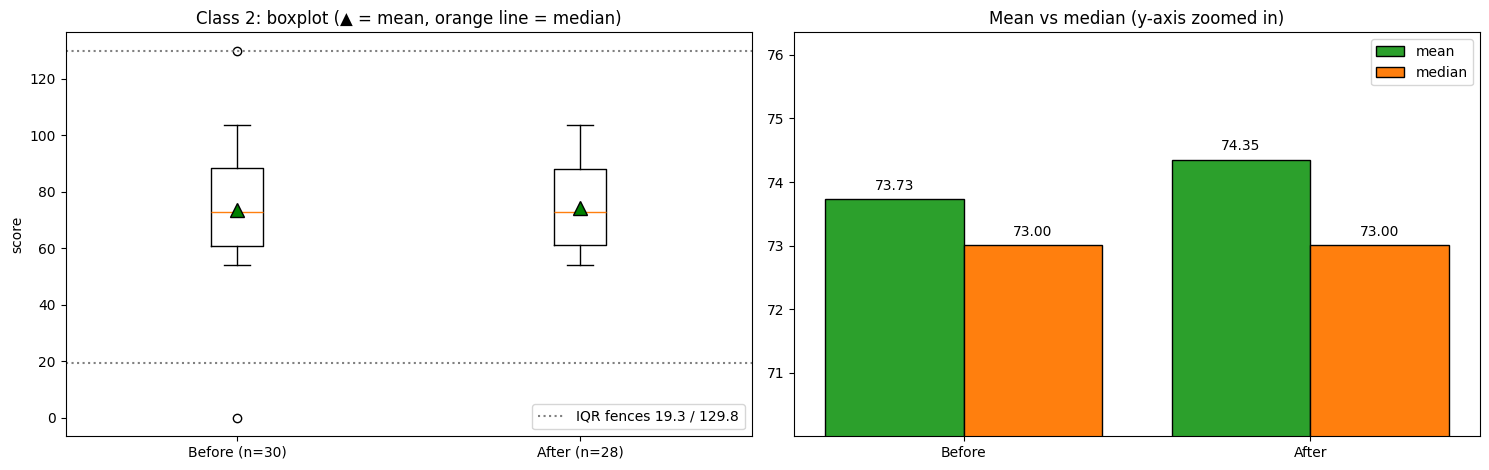

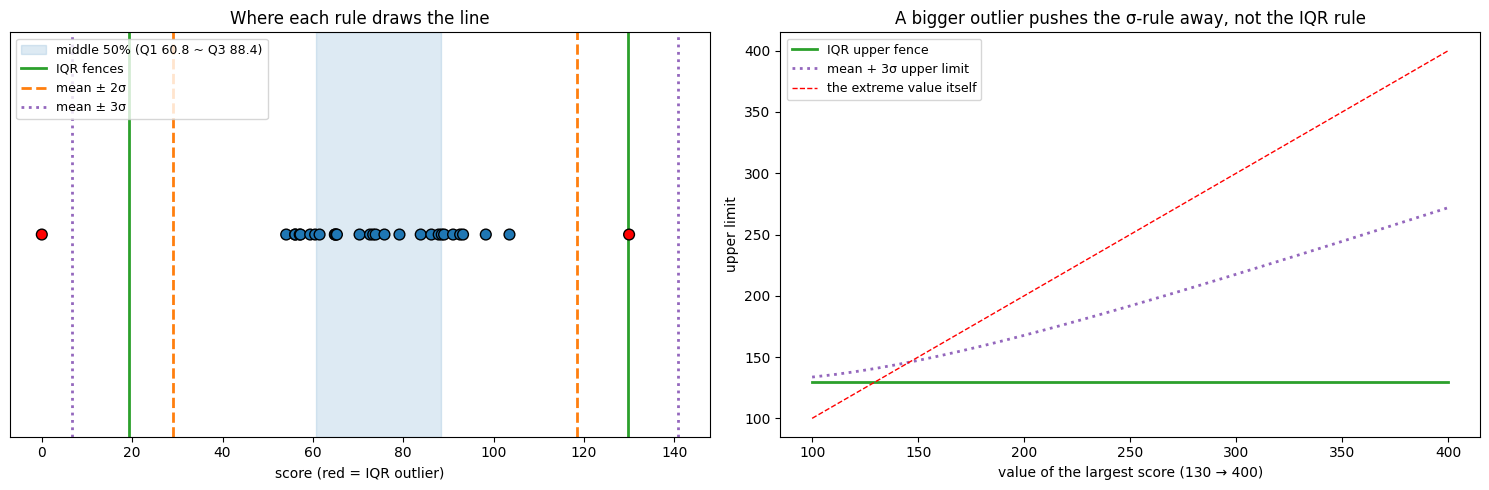

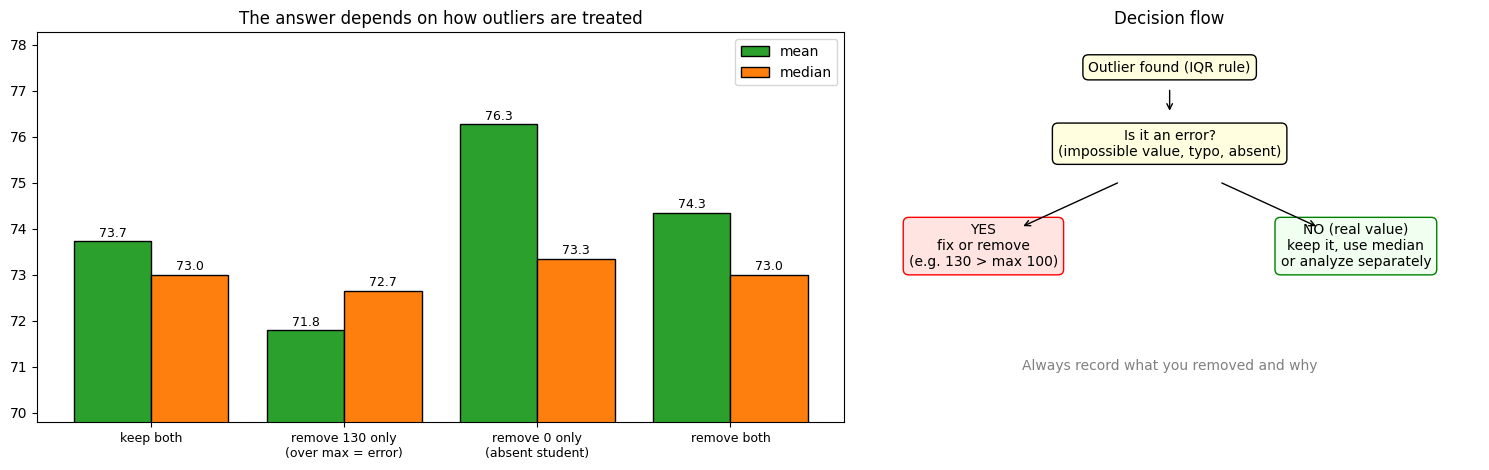

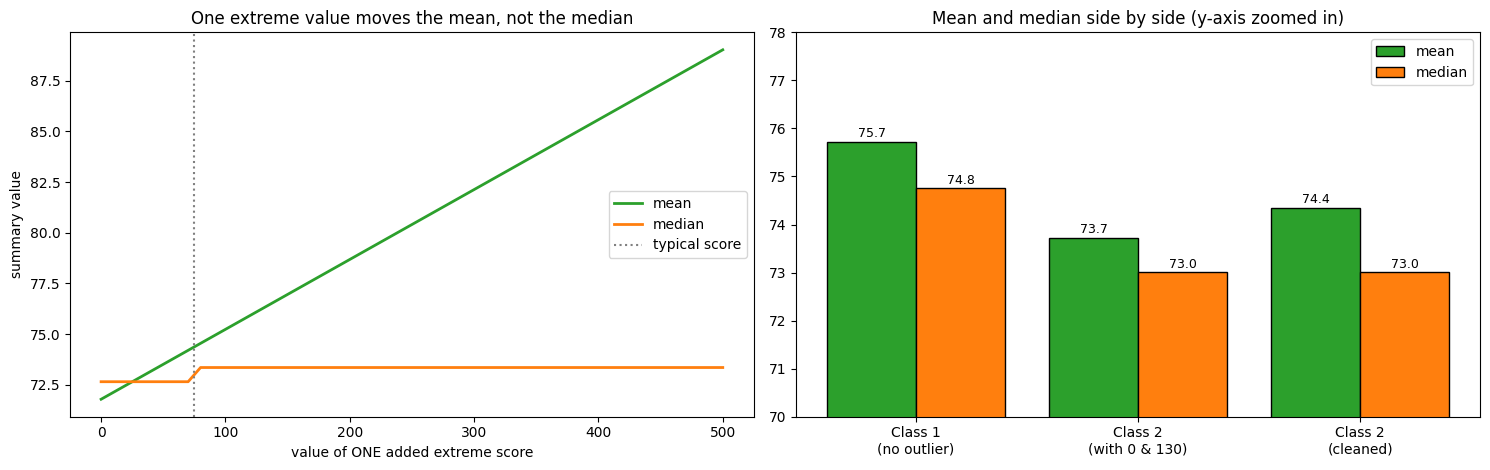

In [31]:
# ═══════════════ [셀 1] 준비 + 데이터 생성 ═══════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)

np.random.seed(2025)
class1 = np.random.normal(75, 8, 30)
class2 = np.concatenate([np.random.normal(75, 15, 28), [0, 130]])
df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

c2 = df3.loc[df3['class'] == '2반', 'score'].reset_index(drop=True)
q1, q3 = c2.quantile(0.25), c2.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (c2 < lower) | (c2 > upper)
c2_clean = c2[~is_out]

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═══════════════ [셀 2] 1. 이상값 제거 전후 평균 ═══════════════
header("1. 이상값 제거 전후 평균은 어떻게 달라졌나요?")

stats_tbl = pd.DataFrame({
    '제거 전': [len(c2), c2.mean(), c2.median(), c2.mean() - c2.median(), c2.std()],
    '제거 후': [len(c2_clean), c2_clean.mean(), c2_clean.median(), c2_clean.mean() - c2_clean.median(), c2_clean.std()],
}, index=['학생 수', '평균', '중앙값', '평균 − 중앙값', '표준편차']).round(2)
stats_tbl['변화'] = (stats_tbl['제거 후'] - stats_tbl['제거 전']).round(2)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].boxplot([c2, c2_clean], showmeans=True,
              meanprops=dict(marker='^', markerfacecolor='green', markeredgecolor='black', markersize=10))
ax[0].set_xticks([1, 2])
ax[0].set_xticklabels([f'Before (n={len(c2)})', f'After (n={len(c2_clean)})'])
ax[0].axhline(lower, color='gray', linestyle=':', label=f'IQR fences {lower:.1f} / {upper:.1f}')
ax[0].axhline(upper, color='gray', linestyle=':')
ax[0].set_ylabel('score')
ax[0].set_title('Class 2: boxplot (▲ = mean, orange line = median)')
ax[0].legend(loc='lower right')
xpos = np.arange(2)
ax[1].bar(xpos - 0.2, [c2.mean(), c2_clean.mean()], width=0.4, color='tab:green', edgecolor='black', label='mean')
ax[1].bar(xpos + 0.2, [c2.median(), c2_clean.median()], width=0.4, color='tab:orange', edgecolor='black', label='median')
for i, (m, md) in enumerate([(c2.mean(), c2.median()), (c2_clean.mean(), c2_clean.median())]):
    ax[1].text(i - 0.2, m + 0.15, f'{m:.2f}', ha='center')
    ax[1].text(i + 0.2, md + 0.15, f'{md:.2f}', ha='center')
ax[1].set_xticks(xpos)
ax[1].set_xticklabels(['Before', 'After'])
ax[1].set_ylim(min(c2.median(), c2.mean()) - 3, max(c2_clean.mean(), c2.mean()) + 2)
ax[1].set_title('Mean vs median (y-axis zoomed in)')
ax[1].legend()
plt.tight_layout()
plt.show()

print(f"판별된 이상값: {c2[is_out].round(1).tolist()}  (기준: {lower:.1f} 미만 또는 {upper:.1f} 초과)\n")
print(stats_tbl)
gap_before = abs(c2.mean() - c2.median())
gap_after = abs(c2_clean.mean() - c2_clean.median())
print(f"""
[답] 평균은 {c2.mean():.2f}점에서 {c2_clean.mean():.2f}점으로 {c2_clean.mean() - c2.mean():+.2f}점 변했고, 중앙값은 {c2.median():.2f}점으로 그대로입니다.

▸평균이 중앙값에 가까워졌나요?
     {'아니요, 오히려 조금 멀어졌습니다.' if gap_after > gap_before else '네, 가까워졌습니다.'} 평균과 중앙값의 차이가 {gap_before:.2f}점에서 {gap_after:.2f}점으로 {'커졌습니다' if gap_after > gap_before else '줄었습니다'}.
     0점과 130점이 양쪽에서 서로 상쇄하며 평균을 중앙값 근처에 붙잡아 두고 있었기 때문입니다.
     둘을 빼자 일반 학생 {len(c2_clean)}명의 원래 분포(높은 점수 쪽으로 약간 더 퍼짐, 최대 {c2_clean.max():.1f}점)가 드러나 평균이 중앙값보다 조금 위로 갔습니다.
     흔히 '이상값을 빼면 평균이 중앙값에 가까워진다'고 생각하지만, 이상값이 양쪽에 있으면 이번처럼 반대가 될 수도 있습니다.

▸이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?
     평균을 위쪽으로 {c2_clean.mean() - c2.mean():.2f}점 올렸습니다.
     0점은 평균보다 약 {c2.mean():.0f}점 아래, 130점은 약 {130 - c2.mean():.0f}점 위에 있어 0점 쪽이 평균을 더 세게 끌어내리고 있었습니다.
     그래서 두 값을 함께 빼자, 끌어내리던 힘이 사라져 평균이 올라갔습니다.
     반면 표준편차는 {c2.std():.2f}에서 {c2_clean.std():.2f}까지 크게 줄어, 이상값이 '평균'보다 '퍼짐'에 훨씬 큰 영향을 주었음을 알 수 있습니다.""")

# ═══════════════ [셀 3] 2. 왜 IQR 기준인가 ═══════════════
header("2. 왜 IQR을 기준으로 이상값을 판단할까요?")

m_all, s_all = c2.mean(), c2.std()
rules = pd.DataFrame({
    '기준': ['IQR (Q1−1.5·IQR, Q3+1.5·IQR)', '평균 ± 2σ', '평균 ± 3σ'],
    '하한': [lower, m_all - 2 * s_all, m_all - 3 * s_all],
    '상한': [upper, m_all + 2 * s_all, m_all + 3 * s_all],
})
rules['잡아낸 이상값'] = [c2[(c2 < lo) | (c2 > hi)].round(1).tolist() for lo, hi in zip(rules['하한'], rules['상한'])]
rules[['하한', '상한']] = rules[['하한', '상한']].round(1)

# 이상값이 기준선을 얼마나 움직이는지: 130점을 점점 크게 바꿔 보기
extreme = np.arange(100, 401, 10)
iqr_upper, sd_upper = [], []
for e in extreme:
    s = c2.copy()
    s.iloc[-1] = e
    a, b = s.quantile(0.25), s.quantile(0.75)
    iqr_upper.append(b + 1.5 * (b - a))
    sd_upper.append(s.mean() + 3 * s.std())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
xs = np.sort(c2.values)
ax[0].scatter(xs, np.zeros_like(xs), s=60, c=['red' if (v < lower or v > upper) else 'tab:blue' for v in xs], edgecolor='black', zorder=3)
ax[0].axvspan(q1, q3, color='tab:blue', alpha=0.15, label=f'middle 50% (Q1 {q1:.1f} ~ Q3 {q3:.1f})')
for (lo, hi), c, ls, lab in zip(zip(rules['하한'], rules['상한']), ['tab:green', 'tab:orange', 'tab:purple'],
                                 ['-', '--', ':'], ['IQR fences', 'mean ± 2σ', 'mean ± 3σ']):
    ax[0].axvline(lo, color=c, linestyle=ls, lw=2, label=lab)
    ax[0].axvline(hi, color=c, linestyle=ls, lw=2)
ax[0].set_yticks([])
ax[0].set_xlabel('score (red = IQR outlier)')
ax[0].set_title('Where each rule draws the line')
ax[0].legend(loc='upper left', fontsize=9)
ax[1].plot(extreme, iqr_upper, color='tab:green', lw=2, label='IQR upper fence')
ax[1].plot(extreme, sd_upper, color='tab:purple', lw=2, linestyle=':', label='mean + 3σ upper limit')
ax[1].plot(extreme, extreme, color='red', lw=1, linestyle='--', label='the extreme value itself')
ax[1].set_xlabel('value of the largest score (130 → 400)')
ax[1].set_ylabel('upper limit')
ax[1].set_title('A bigger outlier pushes the σ-rule away, not the IQR rule')
ax[1].legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print(rules.to_string(index=False))
print(f"""
▸IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
[답] 데이터를 크기순으로 줄 세워 4등분합니다. 25% 지점이 Q1({q1:.1f}점), 75% 지점이 Q3({q3:.1f}점)이고,
     IQR = Q3 − Q1 = {iqr:.1f}점은 가운데 50% 학생이 퍼진 폭입니다 (왼쪽 그래프의 파란 영역).
     여기서 IQR의 1.5배만큼 더 벗어난 값, 즉 {lower:.1f}점 미만 또는 {upper:.1f}점 초과를 이상값으로 정의합니다.
     이 데이터에서는 0점과 130점(빨간 점)이 해당합니다. 130점은 상한 {upper:.1f}점을 겨우 {130 - upper:.1f}점 넘었습니다.

▸평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?
[답] · 기준 자체가 이상값에 오염되지 않습니다. Q1·Q3는 순서상 위치로 정해져, 양 끝 값이 아무리 극단적이어도 거의 변하지 않습니다.
       오른쪽 그래프처럼 최고점을 130점에서 400점까지 키워도 IQR 상한(초록 선)은 그대로입니다.
     · 반면 표준편차 기준은 이상값이 표준편차를 부풀려 기준선이 함께 밀려납니다 (보라 점선).
       실제로 '평균 ± 3σ' 기준({rules.loc[2, '하한']} ~ {rules.loc[2, '상한']}점)으로는 0점만 잡히고 130점은 정상값으로 통과합니다.
       이렇게 이상값이 스스로를 숨기는 현상을 '가면 효과(masking)'라고 합니다.
     · 또 IQR은 정규분포를 가정하지 않아, 소득처럼 한쪽으로 치우친 데이터에도 쓸 수 있습니다.""")

# ═══════════════ [셀 4] 3. 이상값을 언제 제거·유지하나 ═══════════════
header("3. 이상값은 언제 제거하고, 언제 유지해야 할까요?")

scenarios = {
    'keep both': c2,
    'remove 130 only\n(over max = error)': c2[c2 != 130],
    'remove 0 only\n(absent student)': c2[c2 != 0],
    'remove both': c2_clean,
}
sc = pd.DataFrame({'평균': [s.mean() for s in scenarios.values()], '중앙값': [s.median() for s in scenarios.values()],
                   '표준편차': [s.std() for s in scenarios.values()], '학생 수': [len(s) for s in scenarios.values()]},
                  index=[k.replace('\n', ' ') for k in scenarios]).round(2)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
xpos = np.arange(len(scenarios))
ax[0].bar(xpos - 0.2, sc['평균'], width=0.4, color='tab:green', edgecolor='black', label='mean')
ax[0].bar(xpos + 0.2, sc['중앙값'], width=0.4, color='tab:orange', edgecolor='black', label='median')
for i, (m, md) in enumerate(zip(sc['평균'], sc['중앙값'])):
    ax[0].text(i - 0.2, m + 0.1, f'{m:.1f}', ha='center', fontsize=9)
    ax[0].text(i + 0.2, md + 0.1, f'{md:.1f}', ha='center', fontsize=9)
ax[0].set_xticks(xpos)
ax[0].set_xticklabels(list(scenarios.keys()), fontsize=9)
ax[0].set_ylim(sc[['평균', '중앙값']].min().min() - 2, sc[['평균', '중앙값']].max().max() + 2)
ax[0].set_title('The answer depends on how outliers are treated')
ax[0].legend()
# 판단 순서도
ax[1].axis('off')
ax[1].set_xlim(0, 10)
ax[1].set_ylim(0, 6)
box = dict(boxstyle='round,pad=0.4', fc='lightyellow', ec='black')
ax[1].text(5, 5.4, 'Outlier found (IQR rule)', ha='center', bbox=box)
ax[1].text(5, 4.1, 'Is it an error?\n(impossible value, typo, absent)', ha='center', bbox=box)
ax[1].text(2, 2.4, 'YES\nfix or remove\n(e.g. 130 > max 100)', ha='center', bbox=dict(boxstyle='round,pad=0.4', fc='mistyrose', ec='red'))
ax[1].text(8, 2.4, 'NO (real value)\nkeep it, use median\nor analyze separately', ha='center', bbox=dict(boxstyle='round,pad=0.4', fc='honeydew', ec='green'))
for xy, xytext in [((5, 4.75), (5, 5.15)), ((2.6, 3.0), (4.2, 3.7)), ((7.4, 3.0), (5.8, 3.7))]:
    ax[1].annotate('', xy=xy, xytext=xytext, arrowprops=dict(arrowstyle='->'))
ax[1].text(5, 0.8, 'Always record what you removed and why', ha='center', fontsize=10, color='gray')
ax[1].set_title('Decision flow')
plt.tight_layout()
plt.show()

print(sc)
print(f"""
[답] 이상값을 제거하기 전에 먼저 '이 값이 오류인가, 실제인가?'를 확인해야 합니다. IQR은 후보를 찾아 줄 뿐, 제거 여부는 맥락으로 정합니다.
  · 제거(또는 수정)해야 할 때 = 오류
    - 불가능한 값: 만점이 100점인 시험의 130점은 입력 실수이므로 원자료를 확인해 고치거나 제거합니다.
    - 측정 대상이 아닌 값: 0점이 결시·미응시라면 실력을 나타내지 않으므로 평균 계산에서 뺍니다.
  · 유지해야 할 때 = 실제 값
    - 시험을 보고 받은 진짜 0점이라면, 도움이 필요한 학생이 있다는 중요한 신호입니다. 지우면 그 학생을 놓칩니다.
    - 금융 사기 탐지, 불량품 검출, 장비 고장 감지처럼 '튀는 값을 찾는 것'이 목적이면 이상값이 가장 중요한 데이터입니다.
    - 고소득자처럼 실제로 존재하는 극단값은 지역 총소득을 구할 때 반드시 포함해야 합니다.
  · 왼쪽 그래프처럼 처리 방법에 따라 평균이 {sc['평균'].min():.1f} ~ {sc['평균'].max():.1f}점으로 달라지므로,
    무엇을 왜 제거했는지 반드시 기록하고, 필요하면 '제거 전'과 '제거 후' 결과를 함께 보고합니다.""")

# ═══════════════ [셀 5] 4. 중앙값과 평균 ═══════════════
header("4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?")

# 정상 데이터에 극단값 하나를 넣을 때 평균·중앙값이 얼마나 흔들리는지
base = c2_clean.values
added = np.arange(0, 501, 10)
means = [np.mean(np.r_[base, v]) for v in added]
medians = [np.median(np.r_[base, v]) for v in added]
c1 = df3.loc[df3['class'] == '1반', 'score']

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].plot(added, means, color='tab:green', lw=2, label='mean')
ax[0].plot(added, medians, color='tab:orange', lw=2, label='median')
ax[0].axvline(base.mean(), color='gray', linestyle=':', label='typical score')
ax[0].set_xlabel('value of ONE added extreme score')
ax[0].set_ylabel('summary value')
ax[0].set_title('One extreme value moves the mean, not the median')
ax[0].legend()
labels = ['Class 1\n(no outlier)', 'Class 2\n(with 0 & 130)', 'Class 2\n(cleaned)']
groups = [c1, c2, c2_clean]
xpos = np.arange(3)
ax[1].bar(xpos - 0.2, [g.mean() for g in groups], width=0.4, color='tab:green', edgecolor='black', label='mean')
ax[1].bar(xpos + 0.2, [g.median() for g in groups], width=0.4, color='tab:orange', edgecolor='black', label='median')
for i, g in enumerate(groups):
    ax[1].text(i - 0.2, g.mean() + 0.1, f'{g.mean():.1f}', ha='center', fontsize=9)
    ax[1].text(i + 0.2, g.median() + 0.1, f'{g.median():.1f}', ha='center', fontsize=9)
ax[1].set_xticks(xpos)
ax[1].set_xticklabels(labels)
ax[1].set_ylim(70, 78)
ax[1].set_title('Mean and median side by side (y-axis zoomed in)')
ax[1].legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({'평균': [g.mean() for g in groups], '중앙값': [g.median() for g in groups],
                    '표준편차': [g.std() for g in groups]},
                   index=['1반', '2반 (이상값 포함)', '2반 (이상값 제거)']).round(2))
print(f"""
[답] · 평균이 유용한 상황: 1반처럼 분포가 좌우대칭이고 이상값이 없을 때, 그리고 1인당 예산·총매출 추정처럼 '총합'이 중요한 계산을 할 때입니다.
     · 중앙값이 유용한 상황: 소득, 집값, 2반 점수처럼 이상값이 있거나 분포가 한쪽으로 치우쳤을 때 '보통 사람'을 대표합니다.

▸이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
[답] 중앙값입니다. 왼쪽 그래프처럼 정상 점수들에 극단값 하나만 더해도, 그 값이 0점이든 500점이든 평균(초록)은 직선으로 끌려가지만
     중앙값(주황)은 거의 움직이지 않습니다. 실제로 2반은 이상값 제거 전후 중앙값이 {c2.median():.2f}점으로 똑같았습니다.
     앞의 소득 예제에서는 고소득자 5명 때문에 평균이 중앙값보다 60 이상 높게 나와, 차이가 훨씬 극적이었습니다.

▸두 지표를 함께 보면 어떤 장점이 있을까요?
[답] · 분포 모양을 알 수 있습니다: 평균 > 중앙값이면 높은 쪽에, 평균 < 중앙값이면 낮은 쪽에 극단값이나 긴 꼬리가 있다는 신호입니다.
     · 이상값을 의심할 계기가 됩니다: 두 값의 차이가 크면 데이터에 문제가 있는지 확인하게 됩니다.
     · 단, 차이가 작다고 이상값이 없는 것은 아닙니다. 2반은 0점과 130점이 서로 상쇄해 평균({c2.mean():.2f})과 중앙값({c2.median():.2f})이 비슷하지만,
       표준편차는 1반({c1.std():.2f})의 약 {c2.std() / c1.std():.0f}배입니다. 그래서 평균·중앙값과 함께 표준편차, IQR, 박스플롯까지 봐야 정확합니다.""")

# 문제 5. 변수 유형 분류

**📘 문제**

- 아래 데이터에서 변수의 유형(연속형, 범주형, 이산형 등)을 구분해 봅시다.
- 변수의 의미를 고려하여 어떤 분석 방식이 적절한지도 함께 생각해 봅시다.

In [9]:
# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

**📌 아래를 수행해 보세요:**

1. 각 변수의 데이터 타입을 확인해 봅시다.

2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.
   - 연속형 (numeric-continuous)
   - 이산형 (numeric-discrete)
   - 범주형 (categorical)
   - 서열형 범주 (ordinal-categorical)

1. 각 변수의 데이터 타입을 확인해 봅시다.

             데이터 타입  고유값 개수                       값 예시
age                int64           47                  [48, 36, 30]
coffee_type       object            3  [카페모카, 라떼, 아메리카노]
size              object            3        [Small, Large, Medium]
price            float64          200      [4435.4, 4849.2, 4365.1]
satisfaction       int64            5                     [1, 4, 2]

→ age·satisfaction은 정수(int64), price는 실수(float64), coffee_type·size는 문자열(object)입니다.

2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.

        변수 데이터 타입                         변수 유형                                                    판단 근거
         age       int64         이산형 (numeric-discrete) 18~64세의 정수 값만 가짐 (단, 의미상 연속형으로 다루기도 함)
 coffee_type      object              범주형 (categorical)        아메리카노·라떼·카페모카 사이에 크고 작은 순서가 없음
        size      object 서열형 범주 (ordinal-categorical)                           Small < Medium < Large 순서가 있음
       price     float64       연속형 (numeric-continuous

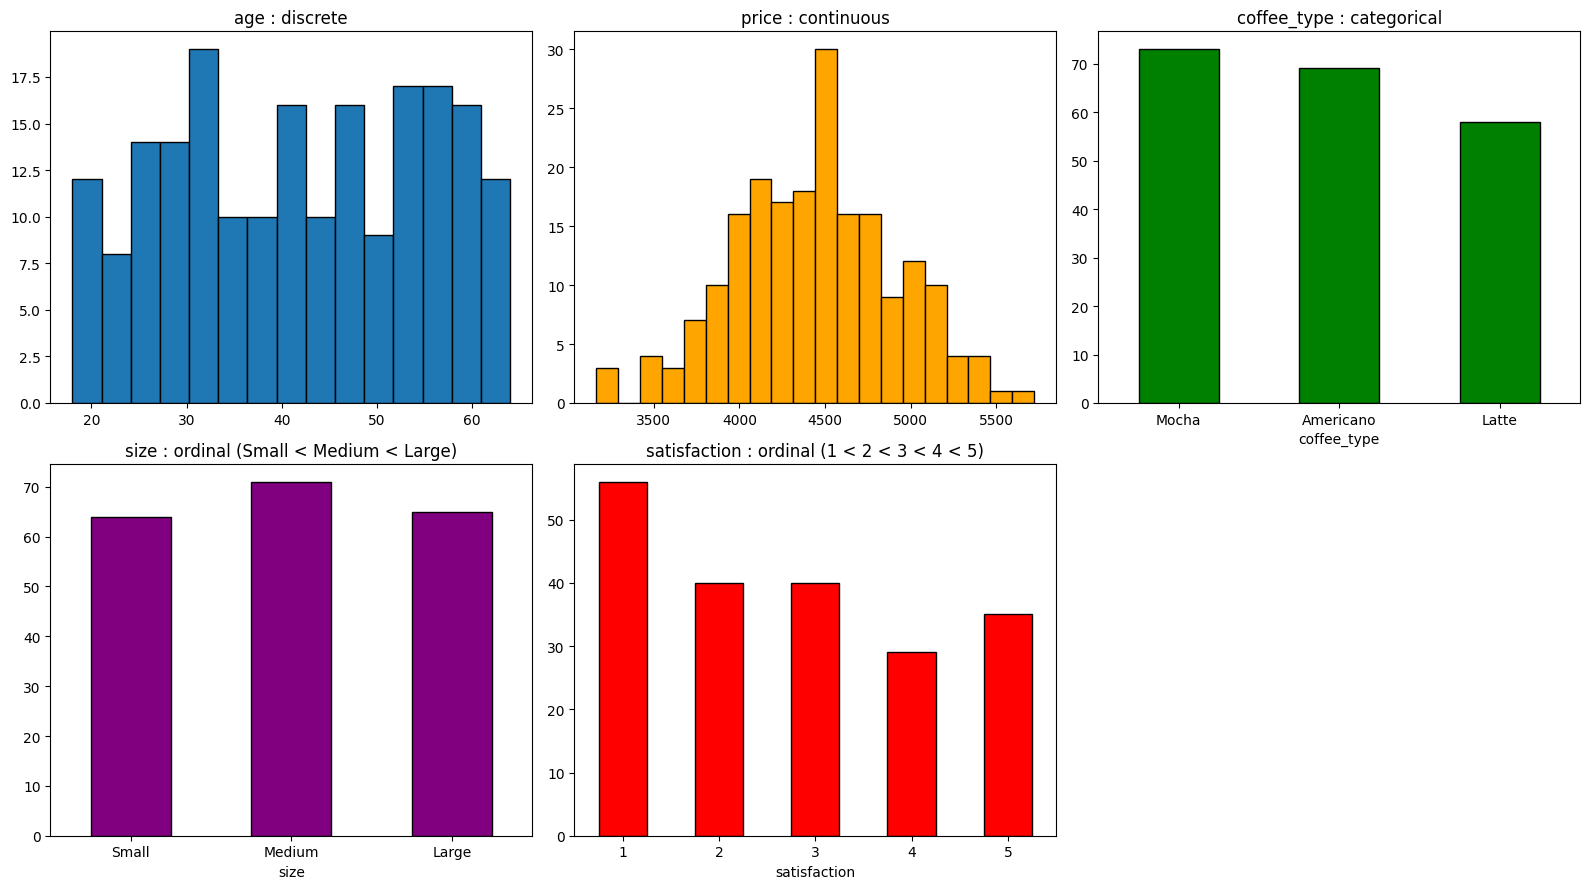

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

# ─────────────────────────────────────────────
# 1. 각 변수의 데이터 타입을 확인해 봅시다.
# ─────────────────────────────────────────────
print("1. 각 변수의 데이터 타입을 확인해 봅시다.\n")
type_df = pd.DataFrame({
    '데이터 타입': df5.dtypes.astype(str),
    '고유값 개수': df5.nunique(),
    '값 예시': [[round(v, 1) if isinstance(v, float) else v for v in df5[c].unique()[:3]] for c in df5.columns]
})
print(type_df)
print("\n→ age·satisfaction은 정수(int64), price는 실수(float64), coffee_type·size는 문자열(object)입니다.")

# ─────────────────────────────────────────────
# 2. 변수의 의미를 기준으로 유형 분류
# ─────────────────────────────────────────────
# 순서가 있는 변수는 의미상 순서를 직접 지정 (데이터 타입만으로는 알 수 없음)
ORDER = {'size': ['Small', 'Medium', 'Large'],
         'satisfaction': [1, 2, 3, 4, 5]}

def classify(col):
    s = df5[col]
    if col in ORDER:
        return '서열형 범주 (ordinal-categorical)'
    if s.dtype == object or str(s.dtype) in ('str', 'string', 'category'):
        return '범주형 (categorical)'
    if np.issubdtype(s.dtype, np.floating):
        return '연속형 (numeric-continuous)'
    return '이산형 (numeric-discrete)'

REASON = {
    'age': '18~64세의 정수 값만 가짐 (단, 의미상 연속형으로 다루기도 함)',
    'coffee_type': '아메리카노·라떼·카페모카 사이에 크고 작은 순서가 없음',
    'size': 'Small < Medium < Large 순서가 있음',
    'price': '소수점까지 어떤 값이든 가능하고 200개 값이 모두 다름',
    'satisfaction': '1~5점은 순서가 있지만 점수 간격이 같다고 보기 어려움',
}

result = pd.DataFrame({
    '변수': df5.columns,
    '데이터 타입': df5.dtypes.astype(str).values,
    '변수 유형': [classify(c) for c in df5.columns],
    '판단 근거': [REASON[c] for c in df5.columns],
})

print("\n2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.\n")
print(result.to_string(index=False))

for label in ['연속형 (numeric-continuous)', '이산형 (numeric-discrete)',
              '범주형 (categorical)', '서열형 범주 (ordinal-categorical)']:
    cols = result.loc[result['변수 유형'] == label, '변수'].tolist()
    print(f"\n▸{label}: {', '.join(cols)}")
    for c in cols:
        print(f"   - {c}: {REASON[c]}")

print("\n→ satisfaction은 숫자(int64)로 저장됐지만 의미는 서열형이고, size는 문자열로 저장됐지만 순서가 있는 서열형입니다.")
print("  변수 유형은 저장된 데이터 타입이 아니라 값의 의미로 판단해야 합니다.")

# 서열형 변수는 순서를 가진 범주형으로 변환
for c, order in ORDER.items():
    df5[c] = pd.Categorical(df5[c], categories=order, ordered=True)
print("\n[변환 후 데이터 타입]")
print(df5.dtypes)

# ─────────────────────────────────────────────
# 3. 변수 유형별 그래프
# ─────────────────────────────────────────────
coffee_en = df5['coffee_type'].map({'아메리카노': 'Americano', '라떼': 'Latte', '카페모카': 'Mocha'})

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
ax[0, 0].hist(df5['age'], bins=15, edgecolor='black')
ax[0, 0].set_title('age : discrete')
ax[0, 1].hist(df5['price'], bins=20, edgecolor='black', color='orange')
ax[0, 1].set_title('price : continuous')
coffee_en.value_counts().plot(kind='bar', ax=ax[0, 2], color='green', edgecolor='black')
ax[0, 2].set_title('coffee_type : categorical')
df5['size'].value_counts().sort_index().plot(kind='bar', ax=ax[1, 0], color='purple', edgecolor='black')
ax[1, 0].set_title('size : ordinal (Small < Medium < Large)')
df5['satisfaction'].value_counts().sort_index().plot(kind='bar', ax=ax[1, 1], color='red', edgecolor='black')
ax[1, 1].set_title('satisfaction : ordinal (1 < 2 < 3 < 4 < 5)')
for a in [ax[0, 2], ax[1, 0], ax[1, 1]]:
    a.tick_params(axis='x', rotation=0)
ax[1, 2].axis('off')
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?

2. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?


══════════════════════════════════════════════════════════════════════
숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?
══════════════════════════════════════════════════════════════════════

[답] satisfaction (만족도 1~5점)
              응답 수  비율(%)
satisfaction                  
1                  56     28.0
2                  40     20.0
3                  40     20.0
4                  29     14.5
5                  35     17.5

satisfaction은 정수(int64)로 저장되어 숫자처럼 보이지만, 1~5점은 '만족 정도의 순서'를 나타내는 서열형입니다.
  · 1점보다 5점이 더 만족한다는 순서는 있지만, 1→2점 차이와 4→5점 차이가 같다는 보장은 없습니다.
  · 그래서 평균 2.73점처럼 소수로 요약하면 '2.73점짜리 만족'이라는 실제로 없는 응답이 대표값이 됩니다.
  · 서열형에는 중앙값 3점, 최빈값 1점, 응답 비율로 요약하는 것이 적절합니다.
  · 이 데이터에서는 가장 많은 응답이 1점(28.0%)이고, 불만(1~2점)이 48.0%, 만족(4~5점)이 32.0%입니다.

참고로 age(나이)는 숫자형이지만 분석 목적에 따라 20대·30대·40대처럼 연령대로 묶으면 서열형 범주로 바꿔 쓸 수 있습니다.
또 실제 데이터에서는 회원번호, 우편번호, 성별 코드(1=남, 2=여)처럼 숫자로 적혀 있어도 계산 의미가 없는 변수가 대표적인 범주형입니다.

══════════════════════════════════════════════════════════════════════
1. 변수 유형에 따라 적절한 분석 

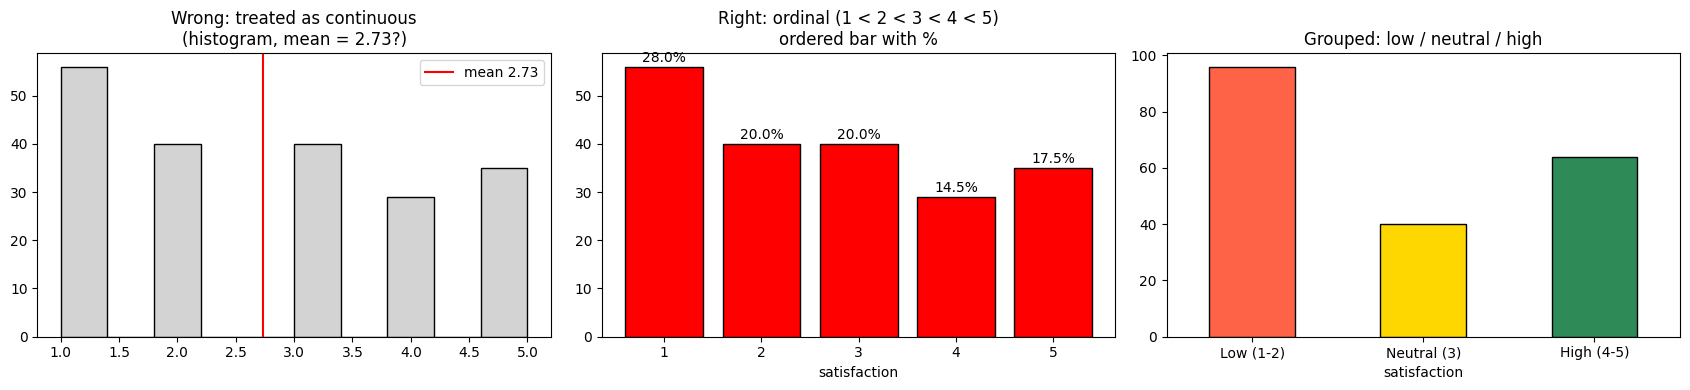

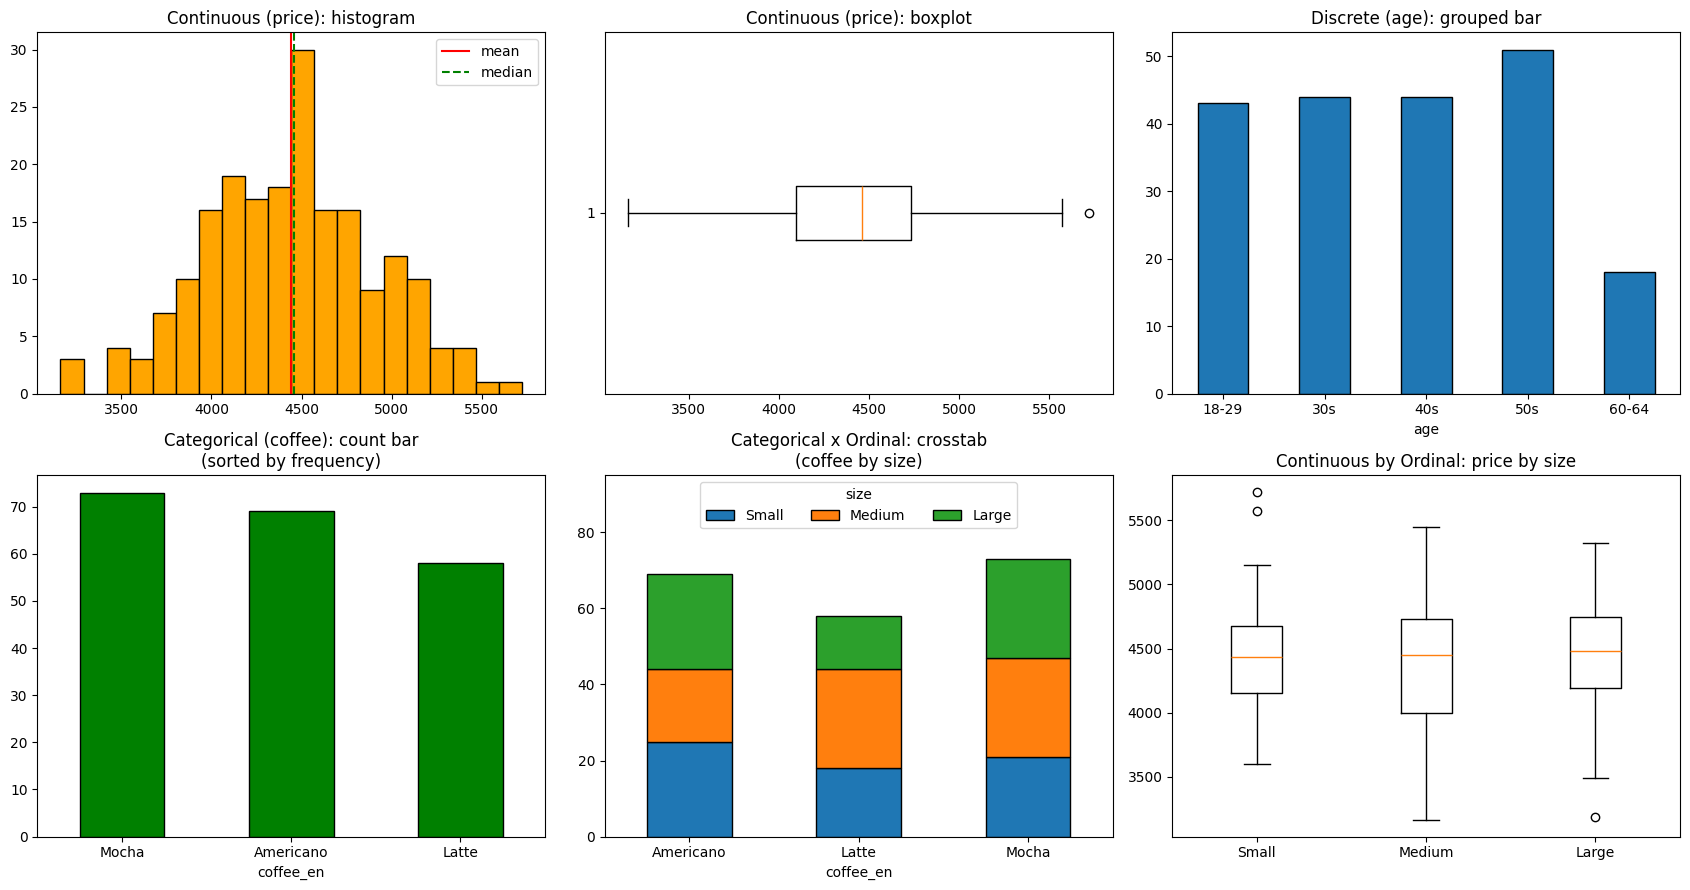

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

# 그래프용 영어 표기와 순서 지정
df5['coffee_en'] = df5['coffee_type'].map({'아메리카노': 'Americano', '라떼': 'Latte', '카페모카': 'Mocha'})
df5['size'] = pd.Categorical(df5['size'], categories=['Small', 'Medium', 'Large'], ordered=True)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 0. 숫자처럼 보이지만 범주형·서열형으로 해석할 변수
# ═════════════════════════════════════════════
header("숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?")

sat = df5['satisfaction']
sat_counts = sat.value_counts().sort_index()
sat_pct = (sat_counts / len(sat) * 100).round(1)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
# (1) 숫자로 착각한 경우: 히스토그램 (구간이 점수 사이에 걸쳐 어색함)
ax[0].hist(sat, bins=10, edgecolor='black', color='lightgray')
ax[0].axvline(sat.mean(), color='red', label=f'mean {sat.mean():.2f}')
ax[0].set_title(f'Wrong: treated as continuous\n(histogram, mean = {sat.mean():.2f}?)')
ax[0].legend()
# (2) 서열형으로 본 경우: 순서대로 정렬한 막대 + 비율
bars = ax[1].bar(sat_counts.index.astype(str), sat_counts.values, color='red', edgecolor='black')
for b, p in zip(bars, sat_pct.values):
    ax[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f'{p}%', ha='center')
ax[1].set_title('Right: ordinal (1 < 2 < 3 < 4 < 5)\nordered bar with %')
ax[1].set_xlabel('satisfaction')
# (3) 그룹으로 묶어 해석: 불만(1-2) / 보통(3) / 만족(4-5)
grp = pd.cut(sat, bins=[0, 2, 3, 5], labels=['Low (1-2)', 'Neutral (3)', 'High (4-5)'])
grp.value_counts().sort_index().plot(kind='bar', ax=ax[2], color=['tomato', 'gold', 'seagreen'], edgecolor='black')
ax[2].set_title('Grouped: low / neutral / high')
ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

print("\n[답] satisfaction (만족도 1~5점)")
print(pd.DataFrame({'응답 수': sat_counts, '비율(%)': sat_pct}))
print(f"""
satisfaction은 정수(int64)로 저장되어 숫자처럼 보이지만, 1~5점은 '만족 정도의 순서'를 나타내는 서열형입니다.
  · 1점보다 5점이 더 만족한다는 순서는 있지만, 1→2점 차이와 4→5점 차이가 같다는 보장은 없습니다.
  · 그래서 평균 {sat.mean():.2f}점처럼 소수로 요약하면 '{sat.mean():.2f}점짜리 만족'이라는 실제로 없는 응답이 대표값이 됩니다.
  · 서열형에는 중앙값 {sat.median():.0f}점, 최빈값 {sat.mode()[0]}점, 응답 비율로 요약하는 것이 적절합니다.
  · 이 데이터에서는 가장 많은 응답이 1점({sat_pct[1]}%)이고, 불만(1~2점)이 {sat_pct[1] + sat_pct[2]:.1f}%, 만족(4~5점)이 {sat_pct[4] + sat_pct[5]:.1f}%입니다.

참고로 age(나이)는 숫자형이지만 분석 목적에 따라 20대·30대·40대처럼 연령대로 묶으면 서열형 범주로 바꿔 쓸 수 있습니다.
또 실제 데이터에서는 회원번호, 우편번호, 성별 코드(1=남, 2=여)처럼 숫자로 적혀 있어도 계산 의미가 없는 변수가 대표적인 범주형입니다.""")

# ═════════════════════════════════════════════
# 1. 변수 유형별 분석·시각화 방법
# ═════════════════════════════════════════════
header("1. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?")

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
# 연속형: 히스토그램 + 박스플롯
ax[0, 0].hist(df5['price'], bins=20, color='orange', edgecolor='black')
ax[0, 0].axvline(df5['price'].mean(), color='red', label='mean')
ax[0, 0].axvline(df5['price'].median(), color='green', linestyle='--', label='median')
ax[0, 0].set_title('Continuous (price): histogram')
ax[0, 0].legend()
ax[0, 1].boxplot(df5['price'], vert=False)
ax[0, 1].set_title('Continuous (price): boxplot')
# 이산형: 연령대 막대
age_grp = pd.cut(df5['age'], bins=[17, 29, 39, 49, 59, 64], labels=['18-29', '30s', '40s', '50s', '60-64'])
age_grp.value_counts().sort_index().plot(kind='bar', ax=ax[0, 2], color='tab:blue', edgecolor='black')
ax[0, 2].set_title('Discrete (age): grouped bar')
ax[0, 2].tick_params(axis='x', rotation=0)
# 범주형: 빈도 막대 (순서 무관, 많은 순 정렬)
df5['coffee_en'].value_counts().plot(kind='bar', ax=ax[1, 0], color='green', edgecolor='black')
ax[1, 0].set_title('Categorical (coffee): count bar\n(sorted by frequency)')
ax[1, 0].tick_params(axis='x', rotation=0)
# 범주형 × 서열형: 교차표 누적 막대
pd.crosstab(df5['coffee_en'], df5['size']).plot(kind='bar', stacked=True, ax=ax[1, 1], edgecolor='black')
ax[1, 1].set_title('Categorical x Ordinal: crosstab\n(coffee by size)')
ax[1, 1].set_ylim(0, 95)
ax[1, 1].legend(title='size', ncol=3, loc='upper center')
ax[1, 1].tick_params(axis='x', rotation=0)
# 연속형 × 서열형: 그룹별 박스플롯
groups = [df5.loc[df5['size'] == s, 'price'] for s in ['Small', 'Medium', 'Large']]
ax[1, 2].boxplot(groups)
ax[1, 2].set_xticks([1, 2, 3])
ax[1, 2].set_xticklabels(['Small', 'Medium', 'Large'])
ax[1, 2].set_title('Continuous by Ordinal: price by size')
plt.tight_layout()
plt.show()

print("\n[답]")
methods = pd.DataFrame({
    '변수 유형': ['연속형', '이산형', '범주형', '서열형 범주'],
    '예시 변수': ['price', 'age', 'coffee_type', 'size, satisfaction'],
    '요약 통계': ['평균, 중앙값, 표준편차, 사분위수', '평균, 중앙값, 빈도', '빈도, 비율, 최빈값', '중앙값, 최빈값, 비율 (평균은 주의)'],
    '적절한 그래프': ['히스토그램, 박스플롯', '막대그래프, 구간으로 묶은 히스토그램', '막대그래프 (많은 순 정렬), 원그래프', '순서대로 정렬한 막대그래프, 누적 막대'],
})
print(methods.to_string(index=False))

print("\n[이 데이터의 실제 요약값]")
print(f"  · 연속형 price: 평균 {df5['price'].mean():,.0f}원, 중앙값 {df5['price'].median():,.0f}원, 표준편차 {df5['price'].std():,.0f}원")
print(f"  · 이산형 age: 평균 {df5['age'].mean():.1f}세, 중앙값 {df5['age'].median():.0f}세")
print(f"  · 범주형 coffee_type: 최빈값 {df5['coffee_type'].mode()[0]} ({(df5['coffee_type'].value_counts(normalize=True).max() * 100):.1f}%)")
print(f"  · 서열형 size: 최빈값 {df5['size'].mode()[0]}, 중앙값 {df5['size'].cat.categories[int(np.median(df5['size'].cat.codes))]}")
print(f"  · 서열형 satisfaction: 중앙값 {sat.median():.0f}점, 최빈값 {sat.mode()[0]}점")

print("""
변수 유형이 다르면 쓸 수 있는 계산과 그래프가 달라집니다.
  · 연속형은 값 사이의 거리가 의미 있으므로 평균·표준편차를 계산하고, 히스토그램과 박스플롯으로 분포 모양과 이상값을 봅니다.
  · 이산형은 정수 값이라 막대그래프로 빈도를 볼 수 있고, 값이 많으면 나이처럼 구간(연령대)으로 묶어서 봅니다.
  · 범주형은 평균을 낼 수 없으므로 빈도와 비율로 요약하고, 순서가 없으니 막대를 많은 순으로 정렬해도 됩니다.
  · 서열형은 순서가 있으므로 막대를 반드시 순서대로 놓고, 평균보다 중앙값·최빈값·비율로 요약합니다.

두 변수의 관계를 볼 때도 조합에 따라 방법이 달라집니다.
  · 범주형 × 범주형(커피 종류 × 사이즈): 교차표와 누적 막대그래프, 필요하면 카이제곱 검정
  · 연속형 × 범주형·서열형(가격 × 사이즈): 그룹별 박스플롯, 그룹별 평균 비교(t검정, 분산분석)
  · 연속형 × 연속형(예: 나이 × 가격): 산점도와 상관계수
이 데이터는 무작위로 만든 것이라 사이즈별 가격 차이가 거의 없게 나오지만, 실제 데이터라면 Large일수록 가격이 높게 나타날 것입니다.""")

# 문제 6. 상관관계 분석

**📘 문제**

- 이번에는 변수들 간의 **관계(상관관계)**를 분석해 봅시다.
- 특히 기온(`temp`), 습도(`humidity`), 판매(`sales`) 변수 간의 관계를 수치와 시각화로 살펴보겠습니다.

In [12]:
# 데이터 생성
np.random.seed(202)

temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200

df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

**📌 아래를 수행해 보세요:**

1. 아래의 기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.

2. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.


══════════════════════════════════════════════════════════════════════
기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.
══════════════════════════════════════════════════════════════════════

[답] 상관계수 행렬
           temp  humidity  sales
temp      1.000    -0.116  0.907
humidity -0.116     1.000 -0.390
sales     0.907    -0.390  1.000

  · 기온 ↔ 매출: 0.91 → 매우 강한 양(+)의 상관. 기온이 높을수록 매출이 늘어나는 경향이 있습니다.
  · 습도 ↔ 매출: -0.39 → 중간 정도의 음(-)의 상관. 습도가 높을수록 매출이 줄어드는 경향이 있습니다.
  · 기온 ↔ 습도: -0.12 → 약한 음(-)의 상관. 상관이 약해 두 변수는 사실상 따로 움직입니다.

대각선의 1.00은 자기 자신과의 상관이라 항상 1입니다.
매출에는 기온이 습도보다 더 강하게 관련되어 있습니다.
(데이터 생성식에서도 기온은 ×10, 습도는 ×(-2)로 매출에 반영되어 있어 결과와 일치합니다.)

══════════════════════════════════════════════════════════════════════
1. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.
══════════════════════════════════════════════════════════════════════

[답] 페어플롯 읽는 법
  · 대각선 칸: 각 변수 하나의 분포(히스토그램)입니다. temp와 sales는 가운데가 볼록한 종 모양에 가깝고,
    humidity는 40~75 사이에 비교적 고르게 퍼져 있습니다.
  · 대각선 밖 칸: 두 변수의 산점도와 추세선(빨간 선)입니다.

  · temp × 

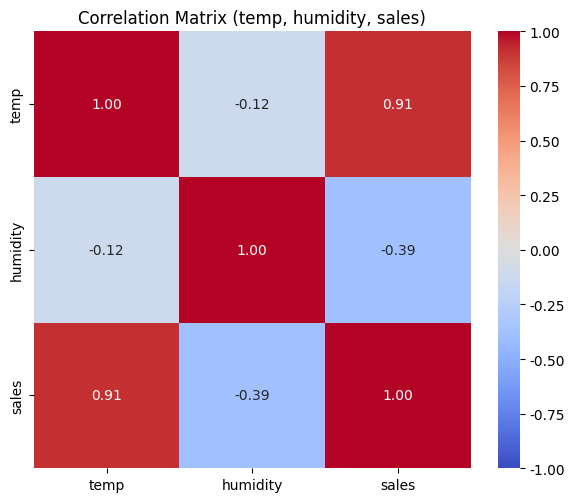

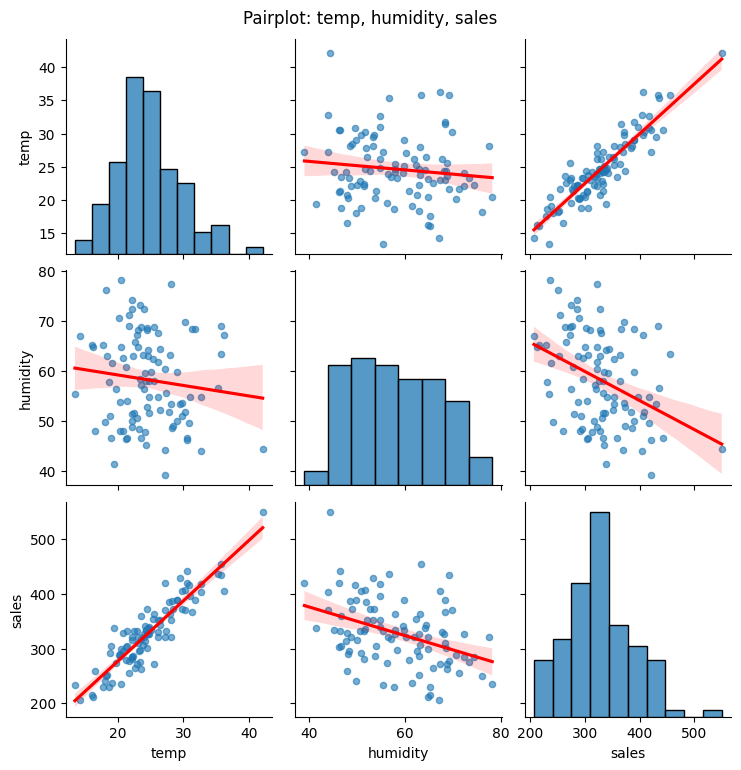

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 200)

# 데이터 생성
np.random.seed(202)
temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200
df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

def strength(r):
    a = abs(r)
    level = '매우 강한' if a >= 0.7 else '강한' if a >= 0.5 else '중간 정도의' if a >= 0.3 else '약한' if a >= 0.1 else '거의 없는'
    sign = '양(+)의' if r > 0 else '음(-)의'
    return f"{level} {sign} 상관" if a >= 0.1 else '상관 거의 없음'

# ═════════════════════════════════════════════
# 0. 상관계수 행렬
# ═════════════════════════════════════════════
header("기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.")

corr = df6.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix (temp, humidity, sales)')
plt.tight_layout()
plt.show()

print("\n[답] 상관계수 행렬")
print(corr.round(3))

r_ts = corr.loc['temp', 'sales']
r_hs = corr.loc['humidity', 'sales']
r_th = corr.loc['temp', 'humidity']
print(f"""
  · 기온 ↔ 매출: {r_ts:.2f} → {strength(r_ts)}. 기온이 높을수록 매출이 늘어나는 경향이 있습니다.
  · 습도 ↔ 매출: {r_hs:.2f} → {strength(r_hs)}. 습도가 높을수록 매출이 줄어드는 경향이 있습니다.
  · 기온 ↔ 습도: {r_th:.2f} → {strength(r_th)}. 상관이 약해 두 변수는 사실상 따로 움직입니다.

대각선의 1.00은 자기 자신과의 상관이라 항상 1입니다.
매출에는 기온이 습도보다 더 강하게 관련되어 있습니다.
(데이터 생성식에서도 기온은 ×10, 습도는 ×(-2)로 매출에 반영되어 있어 결과와 일치합니다.)""")

# ═════════════════════════════════════════════
# 1. 페어플롯
# ═════════════════════════════════════════════
header("1. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.")

g = sns.pairplot(df6, kind='reg', diag_kind='hist',
                 plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.6, 's': 20}})
g.fig.suptitle('Pairplot: temp, humidity, sales', y=1.02)
plt.show()

print(f"""
[답] 페어플롯 읽는 법
  · 대각선 칸: 각 변수 하나의 분포(히스토그램)입니다. temp와 sales는 가운데가 볼록한 종 모양에 가깝고,
    humidity는 40~75 사이에 비교적 고르게 퍼져 있습니다.
  · 대각선 밖 칸: 두 변수의 산점도와 추세선(빨간 선)입니다.

  · temp × sales: 점들이 오른쪽 위로 올라가는 띠 모양이고 추세선 기울기가 뚜렷합니다.
    → 기온이 오를수록 매출이 오르는 양의 관계 (r = {r_ts:.2f})
    → 오른쪽 위 끝에 기온 약 42도·매출 약 550인 점 하나가 떨어져 있지만, 추세선 위에 있어 관계를 흐트러뜨리지는 않습니다.
  · humidity × sales: 점들이 오른쪽 아래로 약하게 내려가고, 퍼짐이 큽니다.
    → 습도가 오를수록 매출이 약간 줄어드는 음의 관계 (r = {r_hs:.2f})
  · temp × humidity: 점들이 둥글게 흩어져 있고 추세선이 거의 평평합니다.
    → 두 변수 사이에 뚜렷한 관계가 없음 (r = {r_th:.2f})

상관계수 행렬은 관계의 세기를 숫자 하나로 보여 주고, 페어플롯은 그 관계가 직선인지, 이상값이 있는지,
점이 얼마나 퍼져 있는지까지 눈으로 확인하게 해 줍니다. 그래서 두 가지를 함께 보는 것이 좋습니다.
단, 상관관계는 인과관계가 아니므로 '기온이 매출을 올린다'고 단정하려면 추가 분석이 필요합니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 상관계수 행렬을 보고,
   - 어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
   - 어느 쌍이 **양의 상관관계**, 어느 쌍이 **음의 상관관계**인가요?

2. 페어플롯에서
   - 어떤 변수 쌍은 **직선 형태**로 관계가 보이나요?
   - 어떤 변수 쌍은 **분산이 크거나 패턴이 없는**가요?

3. **상관관계가 반드시 인과관계를 의미하지는 않습니다.**
   - 온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?

4. 이 데이터를 바탕으로 어떤 **추가 가설**이나 **실험 설계**를 생각해볼 수 있을까요?


══════════════════════════════════════════════════════════════════════
1. 출력된 상관계수 행렬을 보고,
══════════════════════════════════════════════════════════════════════
           temp  humidity  sales
temp      1.000    -0.116  0.907
humidity -0.116     1.000 -0.390
sales     0.907    -0.390  1.000

▸어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
[답] temp입니다. temp와 sales의 상관계수는 0.91로 매우 강한 양의 상관이고,
     humidity와 sales(-0.39)보다 절댓값이 2배 이상 큽니다.

▸어느 쌍이 양의 상관관계, 어느 쌍이 음의 상관관계인가요?
[답] 양의 상관: temp - sales (0.91) → 기온이 오르면 매출도 오름
     음의 상관: humidity - sales (-0.39) → 습도가 오르면 매출이 내려감
     음의 상관: temp - humidity (-0.12) → 다만 0에 가까워 사실상 관계가 없음

══════════════════════════════════════════════════════════════════════
2. 페어플롯에서
══════════════════════════════════════════════════════════════════════
              쌍  상관계수 r  설명력 R²  기울기
    temp - sales        0.91       0.82   11.02
humidity - sales       -0.39       0.15   -2.62
 temp - humidity       -0.12       0.01   -0.21

R²(설명력)는 한 변수가 다른 변수의 변화를 직선으로 얼마나 설명하는

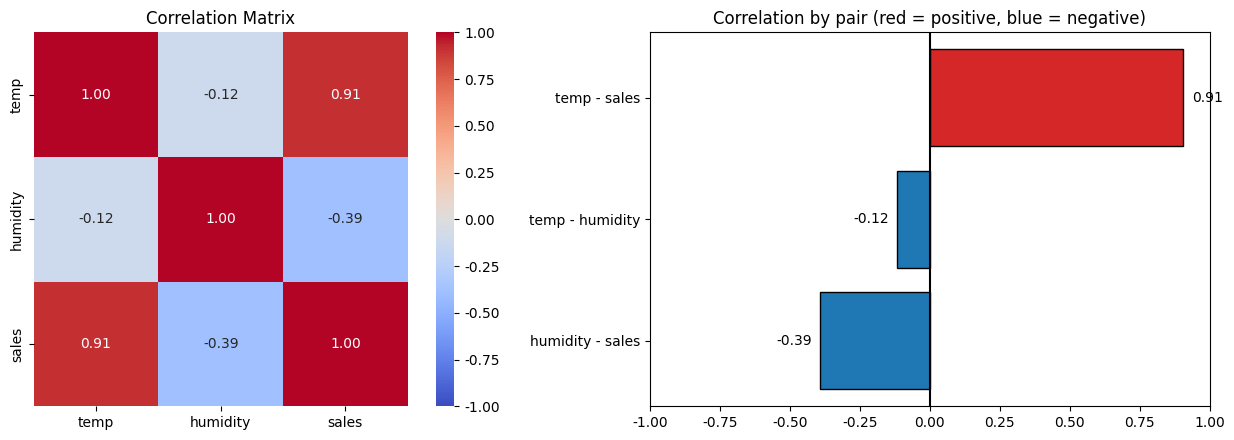

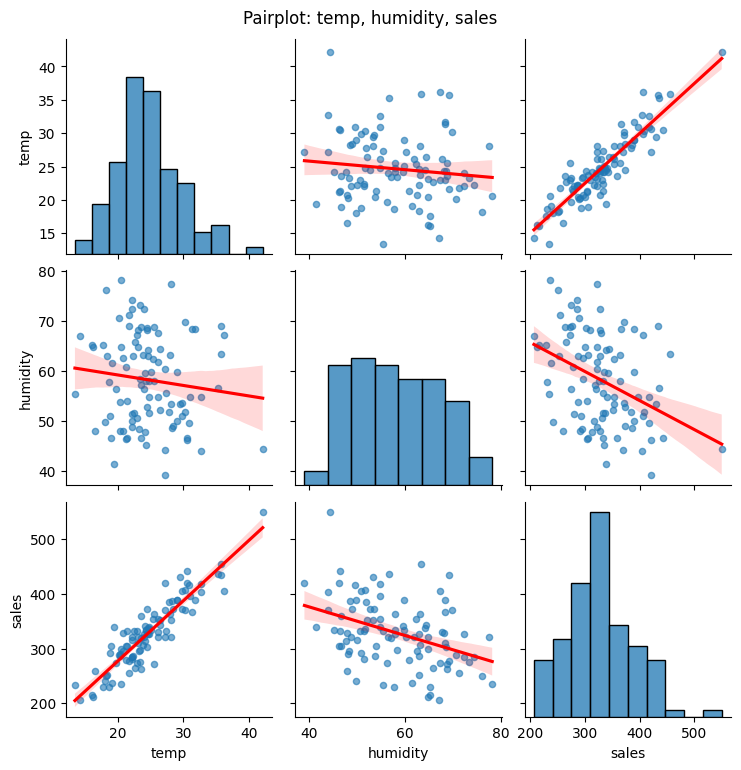

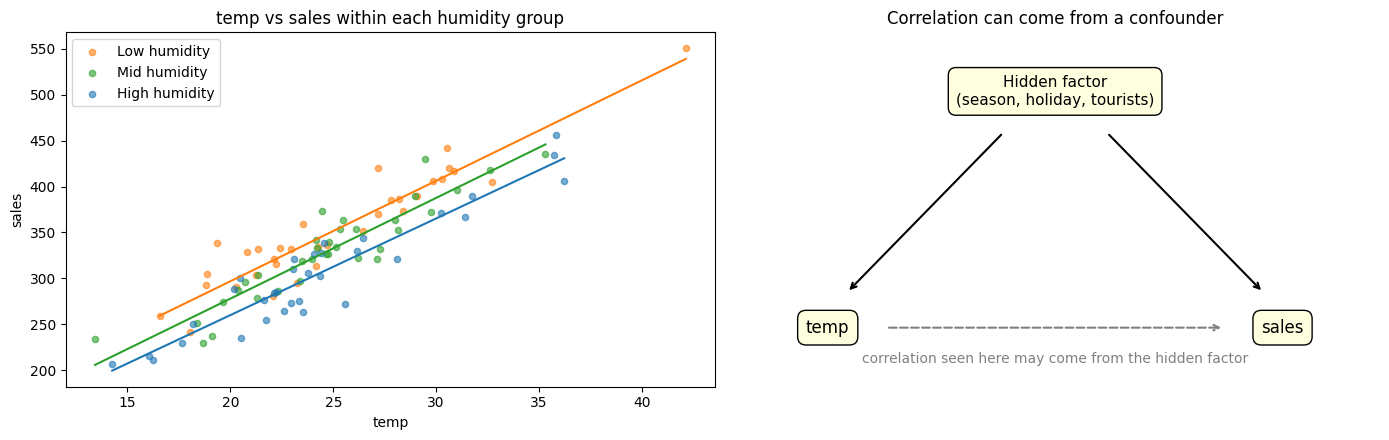

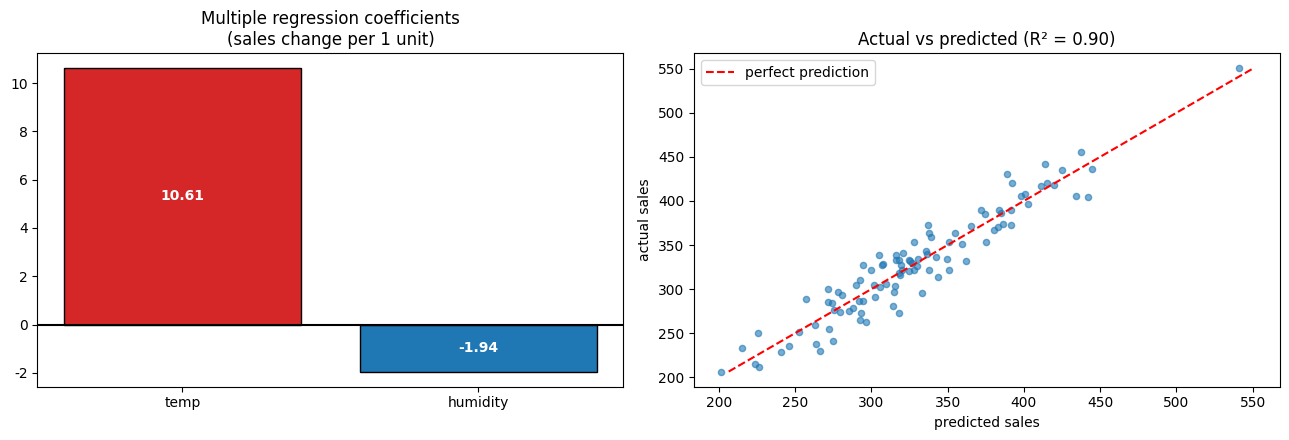

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 200)

# 데이터 생성
np.random.seed(202)
temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200
df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

corr = df6.corr()
pairs = [('temp', 'sales'), ('humidity', 'sales'), ('temp', 'humidity')]

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

def fit_line(x, y):
    """단순 회귀선: 기울기, 절편, 결정계수(R²), 잔차 표준편차"""
    slope, intercept = np.polyfit(x, y, 1)
    pred = slope * x + intercept
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return slope, intercept, r2, (y - pred).std()

# ═════════════════════════════════════════════
# 1. 상관계수 행렬 읽기
# ═════════════════════════════════════════════
header("1. 출력된 상관계수 행렬을 보고,")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax[0])
ax[0].set_title('Correlation Matrix')
pair_r = pd.Series({f'{a} - {b}': corr.loc[a, b] for a, b in pairs}).sort_values()
ax[1].barh(pair_r.index, pair_r.values, color=['tab:blue' if v < 0 else 'tab:red' for v in pair_r.values], edgecolor='black')
for i, v in enumerate(pair_r.values):
    ax[1].text(v + (0.03 if v >= 0 else -0.03), i, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right')
ax[1].axvline(0, color='black')
ax[1].set_xlim(-1, 1)
ax[1].set_title('Correlation by pair (red = positive, blue = negative)')
plt.tight_layout()
plt.show()

print(corr.round(3))
with_sales = corr['sales'].drop('sales')
top = with_sales.abs().idxmax()
print(f"""
▸어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
[답] {top}입니다. temp와 sales의 상관계수는 {corr.loc['temp', 'sales']:.2f}로 매우 강한 양의 상관이고,
     humidity와 sales({corr.loc['humidity', 'sales']:.2f})보다 절댓값이 2배 이상 큽니다.

▸어느 쌍이 양의 상관관계, 어느 쌍이 음의 상관관계인가요?
[답] 양의 상관: temp - sales ({corr.loc['temp', 'sales']:.2f}) → 기온이 오르면 매출도 오름
     음의 상관: humidity - sales ({corr.loc['humidity', 'sales']:.2f}) → 습도가 오르면 매출이 내려감
     음의 상관: temp - humidity ({corr.loc['temp', 'humidity']:.2f}) → 다만 0에 가까워 사실상 관계가 없음""")

# ═════════════════════════════════════════════
# 2. 페어플롯 읽기
# ═════════════════════════════════════════════
header("2. 페어플롯에서")

g = sns.pairplot(df6, kind='reg', diag_kind='hist',
                 plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.6, 's': 20}})
g.fig.suptitle('Pairplot: temp, humidity, sales', y=1.02)
plt.show()

fit_rows = []
for a, b in pairs:
    slope, intercept, r2, resid_sd = fit_line(df6[a], df6[b])
    fit_rows.append({'쌍': f'{a} - {b}', '상관계수 r': round(corr.loc[a, b], 2),
                     '설명력 R²': round(r2, 2), '기울기': round(slope, 2)})
fit_df = pd.DataFrame(fit_rows)
print(fit_df.to_string(index=False))
print(f"""
R²(설명력)는 한 변수가 다른 변수의 변화를 직선으로 얼마나 설명하는지를 0~1로 나타냅니다.

▸어떤 변수 쌍은 직선 형태로 관계가 보이나요?
[답] temp - sales입니다. 점들이 추세선 주위에 좁은 띠로 모여 오른쪽 위로 올라갑니다.
     R²가 {fit_df.loc[0, '설명력 R²']}로, 기온 하나로 매출 변화의 약 {fit_df.loc[0, '설명력 R²'] * 100:.0f}%를 설명할 수 있습니다.
     기울기 {fit_df.loc[0, '기울기']}는 기온이 1도 오를 때 매출이 평균 약 {fit_df.loc[0, '기울기']:.0f}만큼 늘어난다는 뜻입니다.

▸어떤 변수 쌍은 분산이 크거나 패턴이 없는가요?
[답] humidity - sales는 내려가는 방향은 보이지만 점이 추세선에서 넓게 흩어져 분산이 큽니다.
     R²가 {fit_df.loc[1, '설명력 R²']}로 습도만으로는 매출 변화의 약 {fit_df.loc[1, '설명력 R²'] * 100:.0f}%만 설명됩니다.
     temp - humidity는 점들이 둥글게 퍼져 있고 추세선이 거의 평평해 뚜렷한 패턴이 없습니다 (R² {fit_df.loc[2, '설명력 R²']}).""")

# ═════════════════════════════════════════════
# 3. 상관관계 ≠ 인과관계
# ═════════════════════════════════════════════
header("3. 상관관계가 반드시 인과관계를 의미하지는 않습니다.")

df6['humidity_group'] = pd.qcut(df6['humidity'], 3, labels=['Low humidity', 'Mid humidity', 'High humidity'])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
colors = {'Low humidity': 'tab:orange', 'Mid humidity': 'tab:green', 'High humidity': 'tab:blue'}
group_rows = []
for grp, d in df6.groupby('humidity_group', observed=True):
    slope, intercept, r2, _ = fit_line(d['temp'], d['sales'])
    xs = np.linspace(d['temp'].min(), d['temp'].max(), 10)
    ax[0].scatter(d['temp'], d['sales'], alpha=0.6, s=20, color=colors[grp], label=grp)
    ax[0].plot(xs, slope * xs + intercept, color=colors[grp])
    group_rows.append({'습도 그룹': grp, '관측 수': len(d), 'temp-sales 상관': round(d['temp'].corr(d['sales']), 2),
                       '기울기': round(slope, 1), '평균 매출': round(d['sales'].mean(), 1)})
ax[0].set_xlabel('temp')
ax[0].set_ylabel('sales')
ax[0].set_title('temp vs sales within each humidity group')
ax[0].legend()
# 숨은 변수(교란변수) 예시 그림: 계절 → 기온, 계절 → 매출
ax[1].axis('off')
ax[1].set_xlim(0, 10)
ax[1].set_ylim(0, 6)
box = dict(boxstyle='round,pad=0.5', fc='lightyellow', ec='black')
ax[1].text(5, 5, 'Hidden factor\n(season, holiday, tourists)', ha='center', va='center', bbox=box, fontsize=11)
ax[1].text(1.5, 1, 'temp', ha='center', va='center', bbox=box, fontsize=12)
ax[1].text(8.5, 1, 'sales', ha='center', va='center', bbox=box, fontsize=12)
ax[1].annotate('', xy=(1.8, 1.6), xytext=(4.2, 4.3), arrowprops=dict(arrowstyle='->', lw=1.5))
ax[1].annotate('', xy=(8.2, 1.6), xytext=(5.8, 4.3), arrowprops=dict(arrowstyle='->', lw=1.5))
ax[1].annotate('', xy=(7.6, 1), xytext=(2.4, 1), arrowprops=dict(arrowstyle='->', lw=1.5, ls='--', color='gray'))
ax[1].text(5, 0.4, 'correlation seen here may come from the hidden factor', ha='center', color='gray')
ax[1].set_title('Correlation can come from a confounder')
plt.tight_layout()
plt.show()

group_df = pd.DataFrame(group_rows)
print(group_df.to_string(index=False))
print(f"""
▸온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?
[답] 상관계수만으로는 단정할 수 없습니다.
  · 왼쪽 그래프처럼 습도를 낮음·중간·높음으로 나눠 봐도, 세 그룹 모두에서 기온과 매출은 같은 방향으로 함께 움직입니다.
    즉 '습도 때문에 생긴 가짜 상관'은 아니라는 근거는 됩니다.
    (세 직선이 거의 평행하게 위아래로만 벌어져 있는데, 습도가 높은 그룹일수록 같은 기온에서도 매출이 낮다는 뜻입니다.)
  · 하지만 오른쪽 그림처럼 데이터에 없는 숨은 변수(계절, 휴일, 관광객 수, 프로모션 등)가 기온과 매출을 동시에 올렸을 수 있습니다.
    예를 들어 여름 휴가철에는 기온도 높고 유동인구도 많아 매출이 늘 수 있는데, 이 경우 매출을 올린 건 기온이 아니라 유동인구입니다.
  · 또 상관계수는 '함께 움직인다'는 것만 보여 줄 뿐, 무엇이 원인이고 무엇이 결과인지 방향은 알려 주지 않습니다.
  · 참고로 이 데이터는 sales = temp × 10 − humidity × 2 + … 식으로 만들어서 실제로 기온이 매출을 결정하지만,
    현실 데이터에서는 이런 생성 규칙을 모르기 때문에 추가 분석이나 실험으로 확인해야 합니다.""")

# ═════════════════════════════════════════════
# 4. 추가 가설·실험 설계
# ═════════════════════════════════════════════
header("4. 이 데이터를 바탕으로 어떤 추가 가설이나 실험 설계를 생각해볼 수 있을까요?")

# 다중회귀: sales = b0 + b1*temp + b2*humidity
X = np.column_stack([np.ones(len(df6)), df6['temp'], df6['humidity']])
coef, *_ = np.linalg.lstsq(X, df6['sales'], rcond=None)
pred = X @ coef
r2_multi = 1 - ((df6['sales'] - pred) ** 2).sum() / ((df6['sales'] - df6['sales'].mean()) ** 2).sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(['temp', 'humidity'], coef[1:], color=['tab:red', 'tab:blue'], edgecolor='black')
for i, v in enumerate(coef[1:]):
    ax[0].text(i, v / 2, f'{v:.2f}', ha='center', va='center', color='white', fontweight='bold')
ax[0].axhline(0, color='black')
ax[0].set_title('Multiple regression coefficients\n(sales change per 1 unit)')
ax[1].scatter(pred, df6['sales'], alpha=0.6, s=20)
lims = [df6['sales'].min(), df6['sales'].max()]
ax[1].plot(lims, lims, color='red', linestyle='--', label='perfect prediction')
ax[1].set_xlabel('predicted sales')
ax[1].set_ylabel('actual sales')
ax[1].set_title(f'Actual vs predicted (R² = {r2_multi:.2f})')
ax[1].legend()
plt.tight_layout()
plt.show()

print(f"""[다중회귀 결과] sales = {coef[0]:.1f} + {coef[1]:.2f} × temp + ({coef[2]:.2f}) × humidity,  R² = {r2_multi:.2f}
  · 습도를 고정했을 때 기온이 1도 오르면 매출이 약 {coef[1]:.1f} 늘고,
    기온을 고정했을 때 습도가 1%p 오르면 매출이 약 {abs(coef[2]):.1f} 줄어듭니다.
  · 기온과 습도를 함께 넣으면 매출 변화의 약 {r2_multi * 100:.0f}%를 설명해, 기온 하나만 쓸 때({fit_df.loc[0, '설명력 R²'] * 100:.0f}%)보다 좋아집니다.

[답] 추가 가설
  · 가설 1: 기온이 1도 오를 때마다 매출이 일정하게 약 {coef[1]:.0f}씩 늘어난다.
    → 실제로는 일정 온도를 넘으면 오히려 외출이 줄어 매출이 꺾일 수 있으므로, 구간별(예: 30도 이상)로 따로 확인합니다.
  · 가설 2: 기온과 습도가 함께 높을 때(덥고 습할 때, 불쾌지수가 높을 때) 매출이 더 크게 떨어진다.
    → 기온 × 습도 상호작용 항을 회귀모형에 넣어 검증합니다.
  · 가설 3: 기온의 효과는 요일·휴일·지역에 따라 다르다.
    → 날짜, 요일, 매장 위치 데이터를 추가로 모아 그룹별로 비교합니다.

[답] 실험 설계
  · 숨은 변수 통제: 같은 계절·같은 요일끼리 비교하거나, 회귀모형에 요일·휴일·프로모션 여부를 함께 넣습니다.
  · 자연 실험: 같은 날 기온이 다른 두 지역 매장(예: 서울과 강릉)의 매출을 비교해 계절 효과를 걸러 냅니다.
  · A/B 테스트: 기온 자체는 조작할 수 없으므로, 더운 날 시원한 메뉴 할인 같은 판촉을 무작위로 일부 매장에만 적용하고
    매출 차이를 비교합니다. 그러면 '더운 날 판촉이 매출을 올리는가'라는 인과적 질문에 답할 수 있습니다.
  · 시계열 수집: 하루 단위로 오랜 기간 데이터를 모아, 같은 매장 안에서 기온이 오르내릴 때 매출이 어떻게 변하는지 봅니다.""")

# 문제 7. 범주형 변수 시각화

**📘 문제**

- 앞에서는 수치형 변수의 분포를 시각화하고, 변수 간의 관계도 살펴보았습니다.
- 이번에는 범주형 변수인 커피 음료 데이터를 시각화해 봅시다.
- 어떤 종류가 많이 판매되었는지 빈도 분석을 통해 알아보겠습니다.

In [15]:
# 데이터 생성
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.
   - 각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.
   - **막대그래프(bar plot)**를 그려서 결과를 시각화해 봅시다.

2. 시각화 결과를 보고,
   - 어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.
   - 이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.


══════════════════════════════════════════════════════════════════════
1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.
══════════════════════════════════════════════════════════════════════

▸각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.
            판매 수  비율(%)
drink                       
아메리카노      112     37.3
콜드브루         98     32.7
라떼             90     30.0
합계            300    100.0

▸막대그래프(bar plot)를 그려서 결과를 시각화해 봅시다.
[답] 막대가 많이 팔린 순서대로 정렬되어 있고, 빨간 점선은 세 음료가 똑같이 팔렸을 때의 기준(100잔)입니다.

══════════════════════════════════════════════════════════════════════
2. 시각화 결과를 보고,
══════════════════════════════════════════════════════════════════════

▸어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.
[답] 가장 많이 팔린 음료는 아메리카노(112잔, 37.3%)이고,
     가장 적게 팔린 음료는 라떼(90잔, 30.0%)입니다. 차이는 22잔입니다.

  · 다만 카이제곱 검정 결과 p값이 0.29로, 0.05보다 커서 세 음료의 판매 차이가 우연히 생긴 수준일 가능성이 높습니다.
  · 실제로 이 데이터는 np.random.choice로 세 음료를 같은 확률(각 1/3)로 뽑아 만든 것이라, 이론상 기대값은 각 100잔입니다.
    그래서 시드를 바꿔 다시 실행하면 1위 음료가 바뀔 수 있습니다.

▸이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.
[답]
  · 인

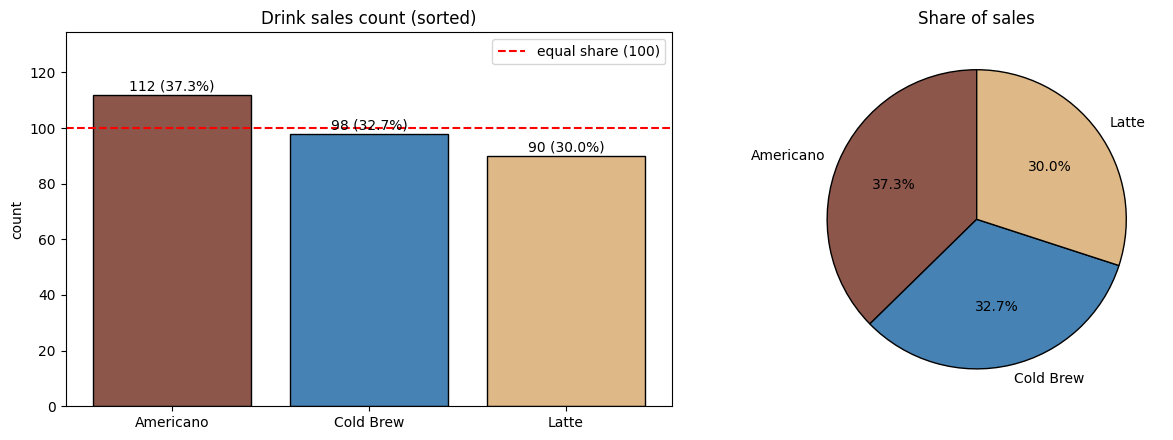

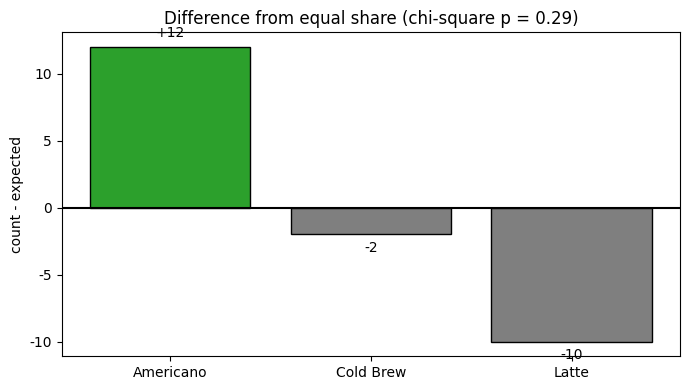

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare

pd.set_option('display.width', 200)

# 데이터 생성 (결과를 매번 같게 하려고 시드 고정 — 원본 코드에는 시드가 없어 실행할 때마다 결과가 달라짐)
np.random.seed(2025)
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

# 그래프용 영어 표기 (Colab 한글 깨짐 방지)
EN = {'아메리카노': 'Americano', '라떼': 'Latte', '콜드브루': 'Cold Brew'}

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 1. 빈도표와 막대그래프
# ═════════════════════════════════════════════
header("1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.")

counts = df7['drink'].value_counts()
pct = (counts / counts.sum() * 100).round(1)
freq = pd.DataFrame({'판매 수': counts, '비율(%)': pct})
freq.loc['합계'] = [counts.sum(), 100.0]
freq['판매 수'] = freq['판매 수'].astype(int)

print("\n▸각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.")
print(freq)

print("\n▸막대그래프(bar plot)를 그려서 결과를 시각화해 봅시다.")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
labels = [EN[d] for d in counts.index]
COLOR = {'아메리카노': 'tab:brown', '라떼': 'burlywood', '콜드브루': 'steelblue'}
colors = [COLOR[d] for d in counts.index]
bars = ax[0].bar(labels, counts.values, color=colors, edgecolor='black')
for b, c, p in zip(bars, counts.values, pct.values):
    ax[0].text(b.get_x() + b.get_width() / 2, c + 1.5, f'{c} ({p}%)', ha='center')
ax[0].axhline(counts.sum() / len(counts), color='red', linestyle='--', label=f'equal share ({counts.sum() / len(counts):.0f})')
ax[0].set_ylim(0, counts.max() * 1.2)
ax[0].set_title('Drink sales count (sorted)')
ax[0].set_ylabel('count')
ax[0].legend(loc='upper right')
ax[1].pie(counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90,
          wedgeprops={'edgecolor': 'black'})
ax[1].set_title('Share of sales')
plt.tight_layout()
plt.show()
print(f"[답] 막대가 많이 팔린 순서대로 정렬되어 있고, 빨간 점선은 세 음료가 똑같이 팔렸을 때의 기준({counts.sum() / len(counts):.0f}잔)입니다.")

# ═════════════════════════════════════════════
# 2. 해석과 마케팅 활용
# ═════════════════════════════════════════════
header("2. 시각화 결과를 보고,")

top, low = counts.idxmax(), counts.idxmin()
stat, p_value = chisquare(counts.values)

print("\n▸어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.")
fig, ax = plt.subplots(figsize=(7, 4))
diff = counts - counts.sum() / len(counts)
ax.bar([EN[d] for d in diff.index], diff.values,
       color=['tab:green' if v > 0 else 'tab:gray' for v in diff.values], edgecolor='black')
for i, v in enumerate(diff.values):
    ax.text(i, v + (0.5 if v >= 0 else -0.5), f'{v:+.0f}', ha='center', va='bottom' if v >= 0 else 'top')
ax.axhline(0, color='black')
ax.set_title(f'Difference from equal share (chi-square p = {p_value:.2f})')
ax.set_ylabel('count - expected')
plt.tight_layout()
plt.show()

print(f"""[답] 가장 많이 팔린 음료는 {top}({counts[top]}잔, {pct[top]}%)이고,
     가장 적게 팔린 음료는 {low}({counts[low]}잔, {pct[low]}%)입니다. 차이는 {counts[top] - counts[low]}잔입니다.

  · 다만 카이제곱 검정 결과 p값이 {p_value:.2f}로, {'0.05보다 커서 세 음료의 판매 차이가 우연히 생긴 수준일 가능성이 높습니다.' if p_value >= 0.05 else '0.05보다 작아서 판매 차이가 우연이라고 보기 어렵습니다.'}
  · 실제로 이 데이터는 np.random.choice로 세 음료를 같은 확률(각 1/3)로 뽑아 만든 것이라, 이론상 기대값은 각 100잔입니다.
    그래서 시드를 바꿔 다시 실행하면 1위 음료가 바뀔 수 있습니다.""")

print("\n▸이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.")
print(f"""[답]
  · 인기 음료({top}) 활용: 매장 메뉴판 맨 앞이나 대표 메뉴로 노출하고, 주재료 재고를 우선 확보합니다.
    세트 메뉴(음료 + 디저트)의 기본 음료로 넣어 객단가를 높일 수 있습니다.
  · 비인기 음료({low}) 활용: 바로 단종하기보다 원인을 먼저 확인합니다.
    시간대(아침/오후), 계절, 가격, 고객층에 따라 덜 팔렸을 수 있으므로, 시음 행사나 '오늘의 음료' 할인으로 반응을 시험합니다.
  · 결과의 한계 인식: {'이번 차이는 통계적으로 의미가 없을 정도로 작아서, 이 데이터만으로 메뉴를 빼거나 크게 바꾸는 것은 위험합니다.' if p_value >= 0.05 else '차이가 통계적으로 의미 있는 수준이지만, 한 번의 조사이므로 기간을 늘려 다시 확인하는 것이 안전합니다.'}
  · 추가로 모을 데이터: 판매 시간대, 날씨, 가격, 고객 연령대, 매출 금액을 함께 모으면 더 정확한 전략을 세울 수 있습니다.
    예를 들어 콜드브루가 더운 날에만 잘 팔린다면 여름 한정 프로모션 대상으로 쓰는 식입니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?
   - 판매량이 가장 많은 음료는?
   - 그 다음으로 인기 있는 음료는?

2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?
   - 가장 많이 팔린 음료를 주력 상품으로 홍보해야 할까요?
   - 판매량이 적은 음료를 프로모션 대상으로 삼는 것은 어떨까요?

3. 막대그래프는 왜 범주형 변수에 적합할까요?
   - `drink`처럼 종류가 명확히 나뉘는 변수를 분석할 때 어떤 점이 중요한가요?

4. 범주형 변수 분석 시 주의할 점은?


══════════════════════════════════════════════════════════════════════
1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?
══════════════════════════════════════════════════════════════════════
            순위  판매 수  비율(%)
drink                             
아메리카노     1      112     37.3
콜드브루       2       98     32.7
라떼           3       90     30.0

▸판매량이 가장 많은 음료는?
[답] 아메리카노입니다. 112잔으로 전체의 37.3%를 차지합니다.

▸그 다음으로 인기 있는 음료는?
[답] 콜드브루입니다. 98잔(32.7%)이며, 1위와 14잔 차이입니다.
     마지막은 라떼로 90잔(30.0%)입니다.

══════════════════════════════════════════════════════════════════════
2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?
══════════════════════════════════════════════════════════════════════
            비율(%) 95% 신뢰구간
drink                           
아메리카노     37.3  31.9 ~ 42.8
콜드브루       32.7  27.4 ~ 38.0
라떼           30.0  24.8 ~ 35.2

왼쪽 그래프의 검은 선(오차 막대)은 비율의 95% 신뢰구간입니다. 세 음료의 구간이 서로 겹쳐 있어, '아메리카노가 확실히 더 인기 있다'고 말하기 어렵습니다 (카이제곱 검정 p = 0.29).
오른쪽 그래프는 세 음료의 인기가 똑같다고 가정하고 300잔을 1,000번 다시 뽑아 본 결과로, 어느 음료든 1위가 될 수 있음을 

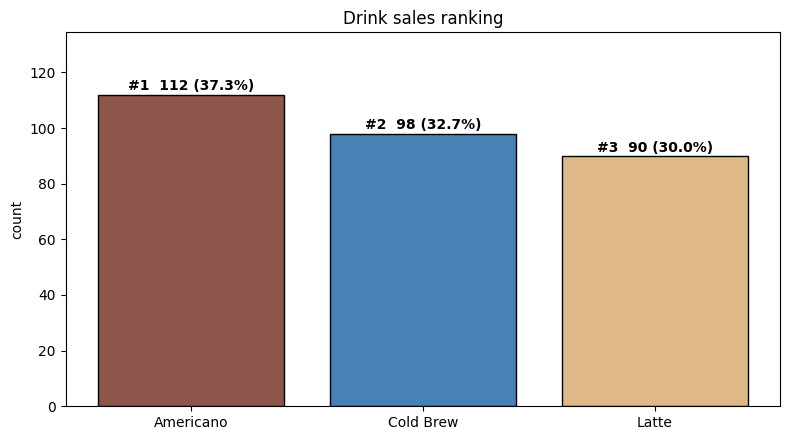

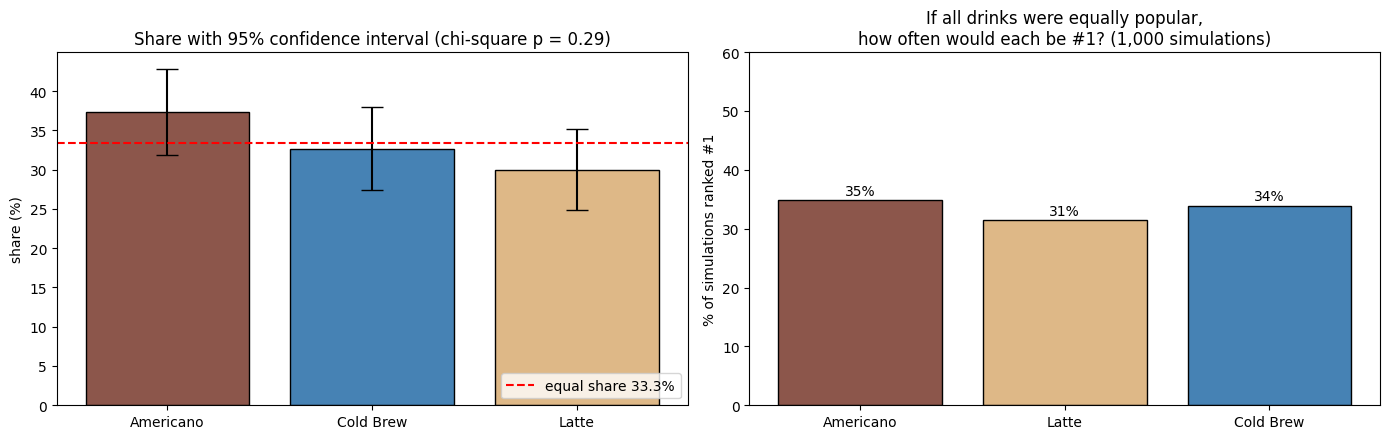

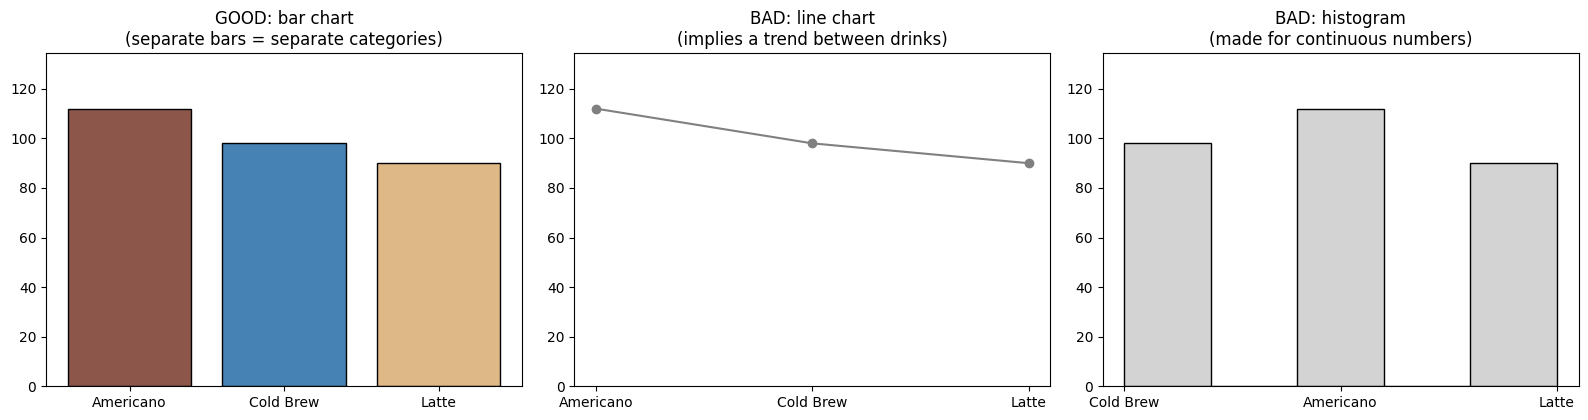

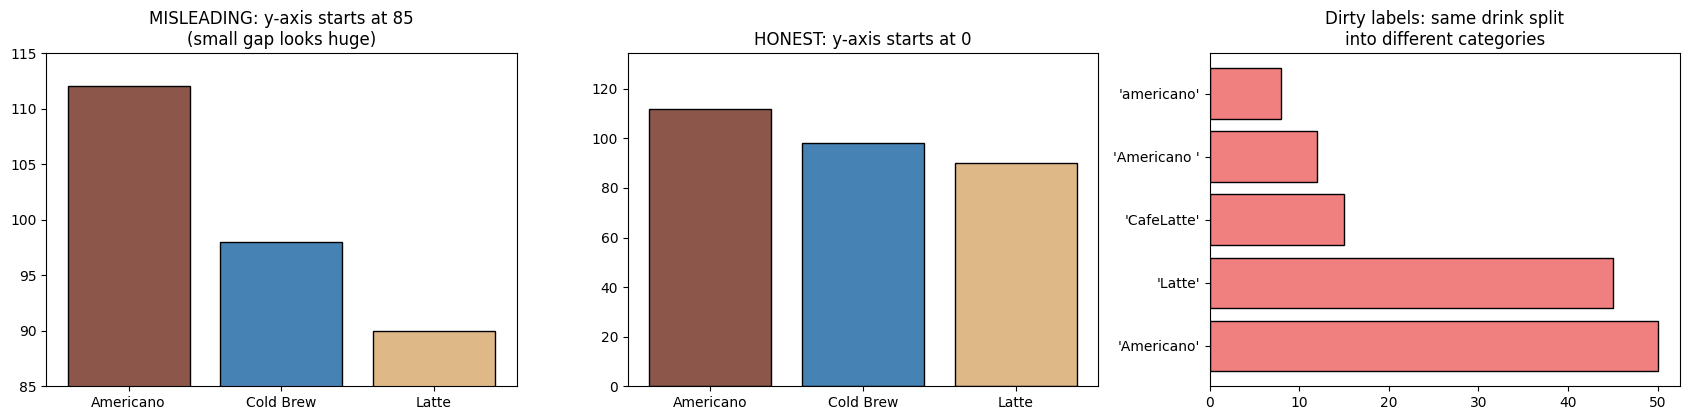

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare

pd.set_option('display.width', 200)

# 데이터 생성 (앞 문제와 같은 결과를 위해 시드 고정)
np.random.seed(2025)
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

# 그래프용 영어 표기와 색 (Colab 한글 깨짐 방지)
EN = {'아메리카노': 'Americano', '라떼': 'Latte', '콜드브루': 'Cold Brew'}
COLOR = {'아메리카노': 'tab:brown', '라떼': 'burlywood', '콜드브루': 'steelblue'}

counts = df7['drink'].value_counts()           # 많이 팔린 순
n = counts.sum()
pct = counts / n * 100
first, second, third = counts.index[:3]
labels = [EN[d] for d in counts.index]
colors = [COLOR[d] for d in counts.index]

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 1. 가장 많이 판매된 음료
# ═════════════════════════════════════════════
header("1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?")

freq = pd.DataFrame({'순위': range(1, len(counts) + 1), '판매 수': counts, '비율(%)': pct.round(1)})
print(freq)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels, counts.values, color=colors, edgecolor='black')
for rank, (b, c, p) in enumerate(zip(bars, counts.values, pct.values), start=1):
    ax.text(b.get_x() + b.get_width() / 2, c + 1.5, f'#{rank}  {c} ({p:.1f}%)', ha='center', fontweight='bold')
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel('count')
ax.set_title('Drink sales ranking')
plt.tight_layout()
plt.show()

print(f"""
▸판매량이 가장 많은 음료는?
[답] {first}입니다. {counts[first]}잔으로 전체의 {pct[first]:.1f}%를 차지합니다.

▸그 다음으로 인기 있는 음료는?
[답] {second}입니다. {counts[second]}잔({pct[second]:.1f}%)이며, 1위와 {counts[first] - counts[second]}잔 차이입니다.
     마지막은 {third}로 {counts[third]}잔({pct[third]:.1f}%)입니다.""")

# ═════════════════════════════════════════════
# 2. 마케팅 전략 활용
# ═════════════════════════════════════════════
header("2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?")

# 비율의 95% 신뢰구간: 순위가 얼마나 확실한지 확인
p_hat = counts / n
se = np.sqrt(p_hat * (1 - p_hat) / n)
lo, hi = (p_hat - 1.96 * se) * 100, (p_hat + 1.96 * se) * 100
stat, p_value = chisquare(counts.values)

# 같은 조건(각 1/3 확률)으로 300잔을 1,000번 다시 뽑았을 때 각 음료가 1위를 하는 비율
rng = np.random.default_rng(0)
sims = rng.multinomial(n, [1 / 3] * 3, size=1000)
win_rate = pd.Series(np.bincount(sims.argmax(axis=1), minlength=3) / 10,
                     index=['Americano', 'Latte', 'Cold Brew'])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(labels, p_hat.values * 100, color=colors, edgecolor='black',
          yerr=[(p_hat * 100 - lo).values, (hi - p_hat * 100).values], capsize=8)
ax[0].axhline(100 / 3, color='red', linestyle='--', label='equal share 33.3%')
ax[0].set_ylabel('share (%)')
ax[0].set_title(f'Share with 95% confidence interval (chi-square p = {p_value:.2f})')
ax[0].legend(loc='lower right')
ax[1].bar(win_rate.index, win_rate.values, color=[COLOR[k] for k in ['아메리카노', '라떼', '콜드브루']], edgecolor='black')
for i, v in enumerate(win_rate.values):
    ax[1].text(i, v + 1, f'{v:.0f}%', ha='center')
ax[1].set_ylim(0, 60)
ax[1].set_ylabel('% of simulations ranked #1')
ax[1].set_title('If all drinks were equally popular,\nhow often would each be #1? (1,000 simulations)')
plt.tight_layout()
plt.show()

ci = pd.DataFrame({'비율(%)': (p_hat * 100).round(1), '95% 신뢰구간': [f'{a:.1f} ~ {b:.1f}' for a, b in zip(lo, hi)]})
print(ci)
uncertain = p_value >= 0.05
ci_msg = ("세 음료의 구간이 서로 겹쳐 있어, '{}가 확실히 더 인기 있다'고 말하기 어렵습니다".format(first) if uncertain
          else "구간 차이가 뚜렷해, {}가 실제로 더 인기 있다고 볼 근거가 있습니다".format(first))
print(f"""
왼쪽 그래프의 검은 선(오차 막대)은 비율의 95% 신뢰구간입니다. {ci_msg} (카이제곱 검정 p = {p_value:.2f}).
오른쪽 그래프는 세 음료의 인기가 똑같다고 가정하고 300잔을 1,000번 다시 뽑아 본 결과로, 어느 음료든 1위가 될 수 있음을 보여 줍니다.

▸가장 많이 팔린 음료를 주력 상품으로 홍보해야 할까요?
[답] {'지금 데이터만으로는 성급합니다. ' + first + '가 1위지만 차이가 우연 수준이라' if uncertain else first + '가 통계적으로도 앞서 있어 주력 상품 후보로 볼 수 있지만'}, 주력 상품으로 크게 투자하기 전에
     2~4주 정도 판매 데이터를 더 모아 순위가 유지되는지 확인해야 합니다.
     순위가 유지된다면 메뉴판 첫 줄 배치, 대표 메뉴 사진, 세트 메뉴의 기본 음료로 활용할 수 있습니다.
     다만 이미 잘 팔리는 음료는 홍보하지 않아도 팔리므로, 홍보 효과(추가로 늘어나는 매출)는 오히려 작을 수 있습니다.

▸판매량이 적은 음료를 프로모션 대상으로 삼는 것은 어떨까요?
[답] 좋은 시도이지만, 먼저 덜 팔린 이유를 구분해야 합니다.
     · 고객이 잘 몰라서라면 → 시음 행사, '오늘의 음료' 할인처럼 노출을 늘리는 프로모션이 효과적입니다.
     · 맛이나 가격에 불만이라면 → 할인보다 레시피나 가격 조정이 먼저입니다.
     {'또 ' + third + '의 비율도 ' + format(pct[third], '.1f') + "%로 다른 음료와 큰 차이가 없으므로, 이 데이터에서는 '비인기 음료'라고 단정하기도 어렵습니다." if uncertain else third + '는 통계적으로도 덜 팔리는 음료로 보여 프로모션 대상으로 적합합니다.'}
     프로모션을 한다면 일부 매장·일부 기간에만 적용하고 나머지와 비교하는 A/B 테스트로 효과를 확인하는 것이 좋습니다.""")

# ═════════════════════════════════════════════
# 3. 막대그래프가 범주형에 적합한 이유
# ═════════════════════════════════════════════
header("3. 막대그래프는 왜 범주형 변수에 적합할까요?")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].bar(labels, counts.values, color=colors, edgecolor='black')
ax[0].set_title('GOOD: bar chart\n(separate bars = separate categories)')
ax[1].plot(labels, counts.values, marker='o', color='gray')
ax[1].set_title('BAD: line chart\n(implies a trend between drinks)')
ax[2].hist(df7['drink'].map(EN), bins=5, color='lightgray', edgecolor='black')
ax[2].set_title('BAD: histogram\n(made for continuous numbers)')
for a in ax:
    a.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.show()

print(f"""[답] 막대그래프는 막대 하나가 범주 하나를 나타내고, 막대 사이가 떨어져 있어 '서로 별개의 종류'라는 점이 그대로 드러납니다.
     막대 높이로 개수를 바로 비교할 수 있어, 범주형 변수의 핵심 정보인 빈도를 보여 주기에 가장 알맞습니다.
     · 꺾은선그래프는 점을 선으로 이어서 {first} → {second} → {third}로 '증가·감소하는 흐름'이 있는 것처럼 보이게 만듭니다.
     · 히스토그램은 연속된 숫자를 구간으로 나누는 그래프라, 범주형에 쓰면 구간이 어긋나 빈 막대가 생기는 등 어색해집니다.

▸`drink`처럼 종류가 명확히 나뉘는 변수를 분석할 때 어떤 점이 중요한가요?
[답] · 범주가 서로 겹치지 않아야 합니다 (한 잔은 반드시 하나의 음료에만 속해야 함).
     · 모든 경우가 포함되어야 합니다 (빠진 메뉴나 '기타'가 있는지 확인).
     · 순서가 없는 명목형이므로 막대는 이름순보다 많이 팔린 순으로 정렬하면 비교가 쉽습니다.
     · 개수와 함께 비율(%)을 같이 봐야, 전체 판매량이 다른 매장이나 기간끼리도 비교할 수 있습니다.""")

# ═════════════════════════════════════════════
# 4. 범주형 변수 분석 시 주의할 점
# ═════════════════════════════════════════════
header("4. 범주형 변수 분석 시 주의할 점은?")

# 예시 1: y축을 자르면 차이가 과장됨
# 예시 2: 표기가 제각각이면 같은 음료가 다른 범주로 나뉨
dirty = pd.Series(['아메리카노'] * 50 + ['아메리카노 '] * 12 + ['americano'] * 8 + ['라떼'] * 45 + ['카페라떼'] * 15)
clean = dirty.str.strip().str.lower().replace({'americano': '아메리카노', '카페라떼': '라떼'})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].bar(labels, counts.values, color=colors, edgecolor='black')
ax[0].set_ylim(counts.min() - 5, counts.max() + 3)
ax[0].set_title(f'MISLEADING: y-axis starts at {counts.min() - 5}\n(small gap looks huge)')
ax[1].bar(labels, counts.values, color=colors, edgecolor='black')
ax[1].set_ylim(0, counts.max() * 1.2)
ax[1].set_title('HONEST: y-axis starts at 0')
dirty_counts = dirty.map(lambda s: repr(s).replace('아메리카노', 'Americano').replace('카페라떼', 'CafeLatte').replace('라떼', 'Latte')).value_counts()
ax[2].barh(dirty_counts.index, dirty_counts.values, color='lightcoral', edgecolor='black')
ax[2].set_title('Dirty labels: same drink split\ninto different categories')
plt.tight_layout()
plt.show()

print("[표기 정리 예시] 정리 전 → 정리 후")
print(pd.DataFrame({'정리 전 범주 수': [dirty.nunique()], '정리 후 범주 수': [clean.nunique()]}).to_string(index=False))
print(clean.value_counts().to_string())

print(f"""
[답]
  · 축을 0부터 시작하기: 왼쪽 그래프처럼 y축을 잘라서 그리면 {counts[first] - counts[third]}잔 차이가 몇 배 차이처럼 보입니다.
    막대그래프는 막대 길이로 비교하므로 반드시 0에서 시작해야 합니다.
  · 표기 통일하기: '아메리카노', '아메리카노 '(공백), 'americano'가 서로 다른 범주로 세어지면 집계가 틀어집니다.
    오른쪽 예시는 같은 음료 2종이 5개 범주로 나뉜 경우로, 공백 제거·대소문자 통일·동의어 정리를 먼저 해야 합니다.
  · 숫자 코드에 속지 않기: 음료를 1=아메리카노, 2=라떼, 3=콜드브루로 저장해도 평균 '1.9'는 아무 의미가 없습니다.
    범주형은 평균 대신 빈도, 비율, 최빈값으로 요약합니다.
  · 작은 차이를 과대 해석하지 않기: 이번 데이터처럼 차이가 작을 때는 카이제곱 검정이나 신뢰구간으로 우연인지 확인합니다.
  · 범주가 너무 많거나 희소할 때: 몇 잔밖에 안 팔린 메뉴가 많으면 '기타'로 묶어야 그래프와 분석이 읽기 쉬워집니다.
  · 개수와 비율을 함께 보기: 판매량 규모가 다른 매장·기간을 비교할 때는 개수보다 비율이 공정한 기준입니다.""")

# 문제 8. 요일별 평균 비교

**📘 문제**

- 이번에는 요일 별 소비 금액 데이터를 분석해 봅시다.
- 각 요일마다 평균 소비 금액이 얼마나 되는지 비교하고,
  **평일과 주말의 소비 패턴 차이**도 함께 살펴보겠습니다.

In [18]:
# 데이터 생성
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.
2. 요일별 평균 금액을 **막대그래프(bar plot)**로 시각화해 봅시다.


══════════════════════════════════════════════════════════════════════
아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.
══════════════════════════════════════════════════════════════════════
     거래 수  평균 금액  표준편차  전체 평균과의 차이
day                                                  
월        75    11666.0    1975.0              -223.0
화        58    11862.0    2070.0               -27.0
수        67    12147.0    2072.0               258.0
목        77    12014.0    2099.0               125.0
금        77    11902.0    1810.0                13.0
토        76    12015.0    1969.0               126.0
일        70    11611.0    1561.0              -278.0

[답] 전체 평균 소비 금액은 11,889원입니다.
     평균이 가장 높은 요일은 수요일(12,147원),
     가장 낮은 요일은 일요일(11,611원)로, 차이는 536원입니다.
     요일별 거래 수는 58~77건으로 비슷합니다.

══════════════════════════════════════════════════════════════════════
1. 요일별 평균 금액을 막대그래프(bar plot)로 시각화해 봅시다.
══════════════════════════════════════════════════════════════════════
[답] 왼쪽 막대그래프를 보면 요일별 평

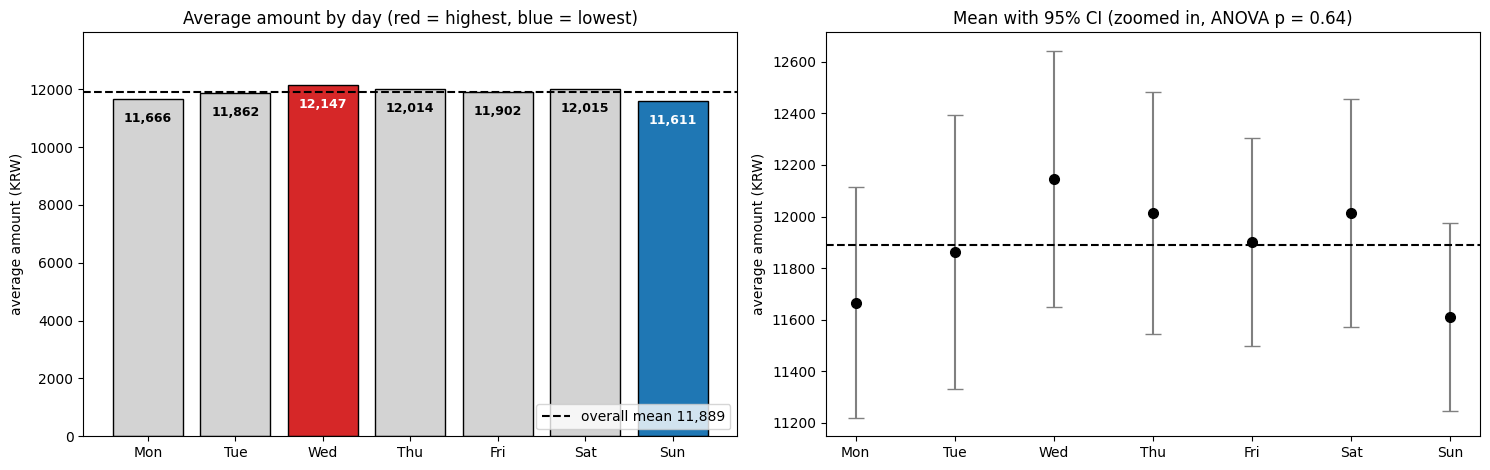

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f_oneway

pd.set_option('display.width', 200)

# 데이터 생성 (결과를 매번 같게 하려고 시드 고정)
np.random.seed(2025)
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

# 요일은 순서가 있으므로 월~일 순서로 지정 (지정하지 않으면 가나다순으로 정렬됨)
DAYS = ['월', '화', '수', '목', '금', '토', '일']
EN = dict(zip(DAYS, ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']))   # 그래프 한글 깨짐 방지
df8['day'] = pd.Categorical(df8['day'], categories=DAYS, ordered=True)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 0. 요일별 평균 계산
# ═════════════════════════════════════════════
header("아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.")

summary = df8.groupby('day', observed=True)['amount'].agg(['count', 'mean', 'std']).round(0)
summary.columns = ['거래 수', '평균 금액', '표준편차']
summary['전체 평균과의 차이'] = (summary['평균 금액'] - df8['amount'].mean()).round(0)
print(summary)

overall = df8['amount'].mean()
top_day, low_day = summary['평균 금액'].idxmax(), summary['평균 금액'].idxmin()
print(f"""
[답] 전체 평균 소비 금액은 {overall:,.0f}원입니다.
     평균이 가장 높은 요일은 {top_day}요일({summary.loc[top_day, '평균 금액']:,.0f}원),
     가장 낮은 요일은 {low_day}요일({summary.loc[low_day, '평균 금액']:,.0f}원)로, 차이는 {summary.loc[top_day, '평균 금액'] - summary.loc[low_day, '평균 금액']:,.0f}원입니다.
     요일별 거래 수는 {summary['거래 수'].min():.0f}~{summary['거래 수'].max():.0f}건으로 비슷합니다.""")

# ═════════════════════════════════════════════
# 1. 막대그래프 시각화
# ═════════════════════════════════════════════
header("1. 요일별 평균 금액을 막대그래프(bar plot)로 시각화해 봅시다.")

means = summary['평균 금액']
ci95 = 1.96 * summary['표준편차'] / np.sqrt(summary['거래 수'])
colors = ['tab:red' if d == top_day else 'tab:blue' if d == low_day else 'lightgray' for d in DAYS]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
# (1) 기본 막대그래프: y축 0부터
bars = ax[0].bar([EN[d] for d in DAYS], means.values, color=colors, edgecolor='black')
for b, v, c in zip(bars, means.values, colors):
    ax[0].text(b.get_x() + b.get_width() / 2, v - 800, f'{v:,.0f}', ha='center', fontsize=9,
               color='white' if c != 'lightgray' else 'black', fontweight='bold')
ax[0].axhline(overall, color='black', linestyle='--', label=f'overall mean {overall:,.0f}')
ax[0].set_ylim(0, means.max() * 1.15)
ax[0].set_ylabel('average amount (KRW)')
ax[0].set_title('Average amount by day (red = highest, blue = lowest)')
ax[0].legend(loc='lower right')
# (2) 평균의 95% 신뢰구간: 차이가 의미 있는지 확인
stat, p_value = f_oneway(*[df8.loc[df8['day'] == d, 'amount'] for d in DAYS])
ax[1].errorbar([EN[d] for d in DAYS], means.values, yerr=ci95.values, fmt='o', color='black',
               ecolor='gray', capsize=6, markersize=7)
ax[1].axhline(overall, color='black', linestyle='--')
ax[1].set_ylabel('average amount (KRW)')
ax[1].set_title(f'Mean with 95% CI (zoomed in, ANOVA p = {p_value:.2f})')
plt.tight_layout()
plt.show()

print(f"""[답] 왼쪽 막대그래프를 보면 요일별 평균 금액이 모두 {means.min():,.0f}~{means.max():,.0f}원 사이로 막대 높이가 거의 같습니다.
     빨간 막대({top_day}요일)가 가장 높고 파란 막대({low_day}요일)가 가장 낮지만, 전체 평균선(점선) 근처에 모여 있습니다.

     오른쪽 그래프는 y축을 확대해 각 요일 평균의 95% 신뢰구간을 그린 것입니다.
     구간들이 서로 겹치고 분산분석(ANOVA) p값이 {p_value:.2f}로 {'0.05보다 커서, 요일에 따른 소비 금액 차이는 우연히 생긴 수준으로 볼 수 있습니다.' if p_value >= 0.05 else '0.05보다 작아서, 요일에 따라 소비 금액이 실제로 다르다고 볼 수 있습니다.'}
     실제로 이 데이터는 요일과 상관없이 평균 12,000원, 표준편차 2,000원으로 만든 것이라 요일 차이가 없는 게 정상입니다.

     그래프를 그릴 때 신경 쓴 점
     · 요일은 순서가 있는 변수라 월→일 순서로 놓았습니다. 그냥 groupby를 하면 가나다순(금, 목, 수, 월, 일, 토, 화)으로 섞입니다.
     · 막대그래프는 y축을 0부터 시작해야 작은 차이가 과장되지 않습니다. 차이를 자세히 보려면 오른쪽처럼 점과 오차 막대로 따로 그립니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 요일에 소비 금액이 가장 높나요?
   - 주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?

2. 소비 금액이 적은 요일은 언제인가요? 왜 그럴까요?

3. 이 결과를 어떻게 활용할 수 있을까요?
   - 주말에 더 많은 재고를 준비하거나
   - 평일에 할인 이벤트를 기획하는 등의 운영/마케팅 전략으로 이어질 수 있을까요?

---

> 💬 정리해 보기
>
> - 범주형 변수(요일)별로 연속형 변수(소비 금액)의 평균을 비교하면 소비 패턴을 이해하고 전략을 수립하는 데 유용한 인사이트를 얻을 수 있습니다.


══════════════════════════════════════════════════════════════════════
1. 어떤 요일에 소비 금액이 가장 높나요?
══════════════════════════════════════════════════════════════════════
     거래 수  평균 금액
day                    
월        75    11666.0
화        58    11862.0
수        67    12147.0
목        77    12014.0
금        77    11902.0
토        76    12015.0
일        70    11611.0

           거래 수  평균 금액  표준편차
week_part                              
평일           354    11916.0    1998.0
주말           146    11821.0    1791.0

[답] 소비 금액(평균)이 가장 높은 요일은 수요일로 12,147원입니다.
     다만 전체 평균(11,889원)보다 259원 높을 뿐이고,
     요일 간 차이를 검정한 분산분석 p값이 0.64라 '수요일에 특별히 많이 쓴다'고 보기는 어렵습니다.

▸주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?
[답] 평일의 평균이 조금 더 높습니다. 평일 11,916원, 주말 11,821원으로
     차이는 95원입니다.
     주말 안에서는 토요일 12,015원, 일요일 11,611원입니다.
     t검정 p값은 0.60이며, 0.05보다 커서 주말과 평일의 차이는 통계적으로 의미가 없습니다.
     오른쪽 박스플롯에서도 두 그룹의 분포가 거의 겹칩니다.

══════════════════════════════════════════════════════════════════════
2. 소비 금액이 적은 요일은 언제인가요? 왜 그

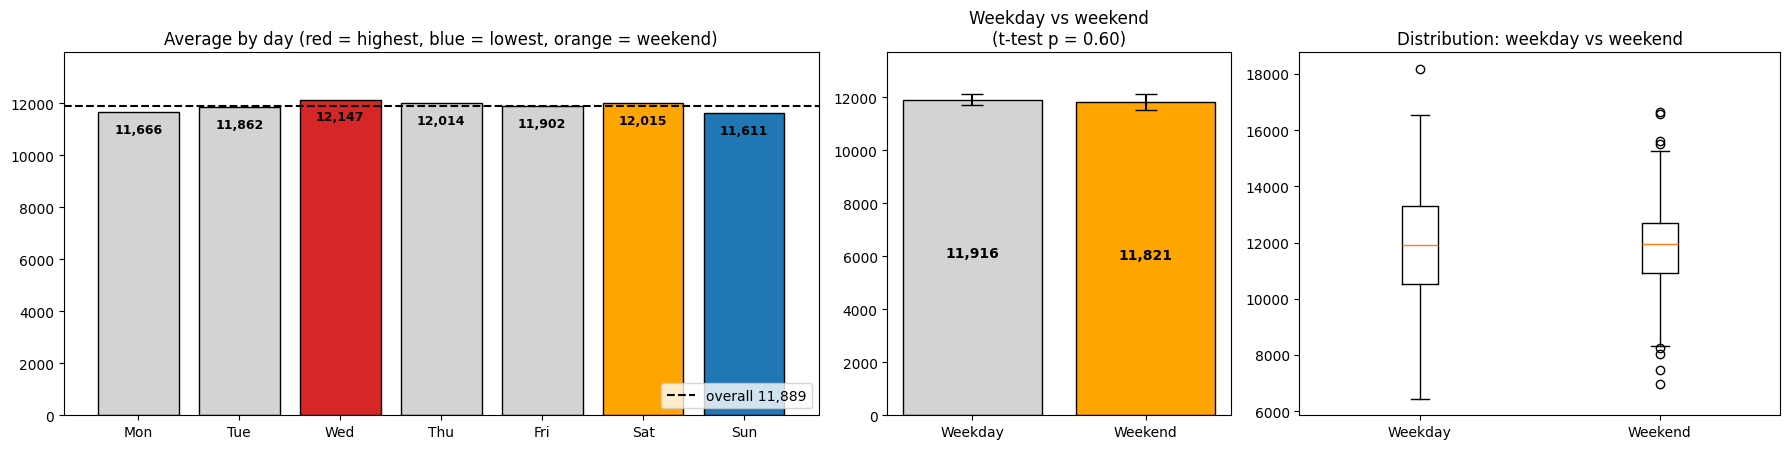

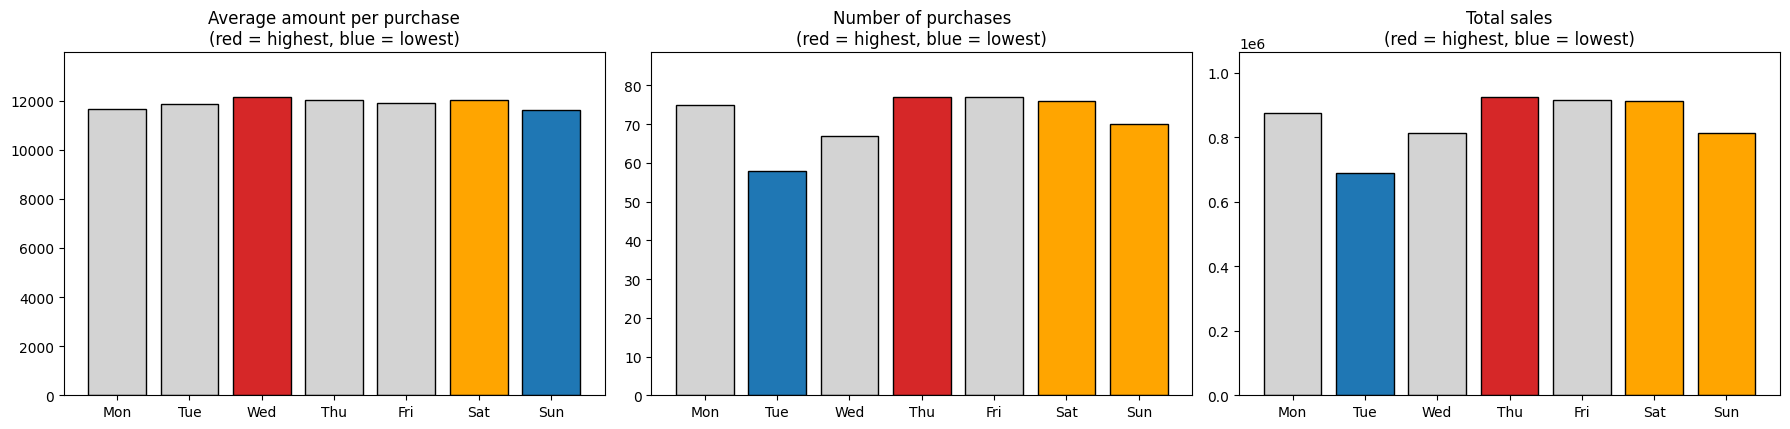

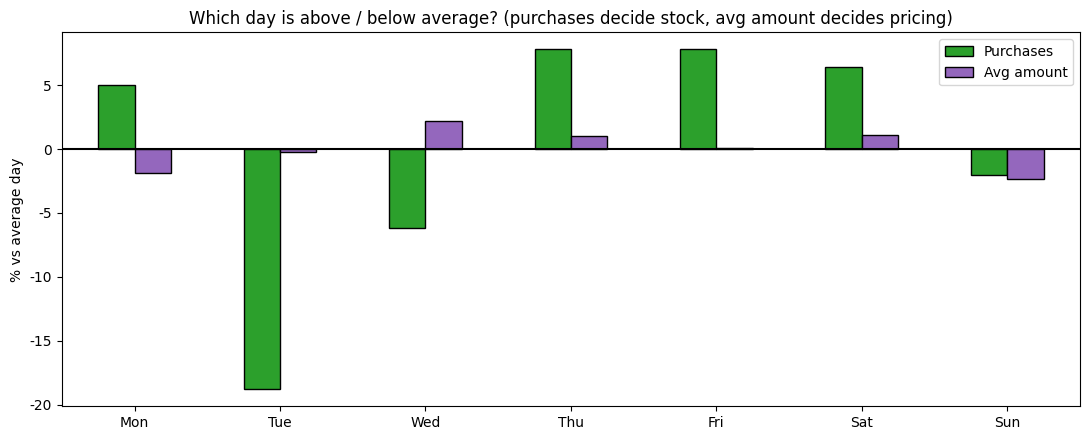

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, f_oneway

pd.set_option('display.width', 200)

# 데이터 생성 (앞 문제와 같은 결과를 위해 시드 고정)
np.random.seed(2025)
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

DAYS = ['월', '화', '수', '목', '금', '토', '일']
EN = dict(zip(DAYS, ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']))   # 그래프 한글 깨짐 방지
df8['day'] = pd.Categorical(df8['day'], categories=DAYS, ordered=True)
df8['week_part'] = np.where(df8['day'].isin(['토', '일']), '주말', '평일')

by_day = df8.groupby('day', observed=True)['amount'].agg(['count', 'mean', 'std', 'sum'])
by_day.columns = ['거래 수', '평균 금액', '표준편차', '총 매출']
overall = df8['amount'].mean()
top_day, low_day = by_day['평균 금액'].idxmax(), by_day['평균 금액'].idxmin()
_, p_anova = f_oneway(*[df8.loc[df8['day'] == d, 'amount'] for d in DAYS])

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

def bar_colors(highlight_high=None, highlight_low=None):
    return ['tab:red' if d == highlight_high else 'tab:blue' if d == highlight_low
            else ('orange' if d in ['토', '일'] else 'lightgray') for d in DAYS]

# ═════════════════════════════════════════════
# 1. 소비 금액이 가장 높은 요일 / 주말 vs 평일
# ═════════════════════════════════════════════
header("1. 어떤 요일에 소비 금액이 가장 높나요?")

wk = df8.groupby('week_part')['amount'].agg(['count', 'mean', 'std'])
wk.columns = ['거래 수', '평균 금액', '표준편차']
wk = wk.loc[['평일', '주말']]
t_stat, p_week = ttest_ind(df8.loc[df8['week_part'] == '주말', 'amount'],
                           df8.loc[df8['week_part'] == '평일', 'amount'], equal_var=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={'width_ratios': [2.2, 1, 1.4]})
bars = ax[0].bar([EN[d] for d in DAYS], by_day['평균 금액'], color=bar_colors(top_day, low_day), edgecolor='black')
for b, v in zip(bars, by_day['평균 금액']):
    ax[0].text(b.get_x() + b.get_width() / 2, v - 800, f'{v:,.0f}', ha='center', fontsize=9, fontweight='bold')
ax[0].axhline(overall, color='black', linestyle='--', label=f'overall {overall:,.0f}')
ax[0].set_ylim(0, by_day['평균 금액'].max() * 1.15)
ax[0].set_title('Average by day (red = highest, blue = lowest, orange = weekend)')
ax[0].legend(loc='lower right')

ax[1].bar(['Weekday', 'Weekend'], wk['평균 금액'], color=['lightgray', 'orange'], edgecolor='black',
          yerr=1.96 * wk['표준편차'] / np.sqrt(wk['거래 수']), capsize=8)
for i, v in enumerate(wk['평균 금액']):
    ax[1].text(i, v / 2, f'{v:,.0f}', ha='center', fontweight='bold')
ax[1].set_ylim(0, wk['평균 금액'].max() * 1.15)
ax[1].set_title(f'Weekday vs weekend\n(t-test p = {p_week:.2f})')

ax[2].boxplot([df8.loc[df8['week_part'] == '평일', 'amount'], df8.loc[df8['week_part'] == '주말', 'amount']])
ax[2].set_xticks([1, 2])
ax[2].set_xticklabels(['Weekday', 'Weekend'])
ax[2].set_title('Distribution: weekday vs weekend')
plt.tight_layout()
plt.show()

print(by_day[['거래 수', '평균 금액']].round(0))
print()
print(wk.round(0))
higher = wk['평균 금액'].idxmax()
print(f"""
[답] 소비 금액(평균)이 가장 높은 요일은 {top_day}요일로 {by_day.loc[top_day, '평균 금액']:,.0f}원입니다.
     다만 전체 평균({overall:,.0f}원)보다 {by_day.loc[top_day, '평균 금액'] - overall:,.0f}원 높을 뿐이고,
     요일 간 차이를 검정한 분산분석 p값이 {p_anova:.2f}라 '{top_day}요일에 특별히 많이 쓴다'고 보기는 어렵습니다.

▸주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?
[답] {higher}의 평균이 조금 더 높습니다. 평일 {wk.loc['평일', '평균 금액']:,.0f}원, 주말 {wk.loc['주말', '평균 금액']:,.0f}원으로
     차이는 {abs(wk.loc['평일', '평균 금액'] - wk.loc['주말', '평균 금액']):,.0f}원입니다.
     주말 안에서는 토요일 {by_day.loc['토', '평균 금액']:,.0f}원, 일요일 {by_day.loc['일', '평균 금액']:,.0f}원입니다.
     t검정 p값은 {p_week:.2f}이며, {'0.05보다 커서 주말과 평일의 차이는 통계적으로 의미가 없습니다.' if p_week >= 0.05 else '0.05보다 작아서 주말과 평일의 차이가 의미 있다고 볼 수 있습니다.'}
     오른쪽 박스플롯에서도 두 그룹의 분포가 거의 겹칩니다.""")

# ═════════════════════════════════════════════
# 2. 소비 금액이 적은 요일과 이유
# ═════════════════════════════════════════════
header("2. 소비 금액이 적은 요일은 언제인가요? 왜 그럴까요?")

# 평균 금액과 거래 수, 총 매출을 함께 비교
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
metrics = [('평균 금액', 'Average amount per purchase'), ('거래 수', 'Number of purchases'), ('총 매출', 'Total sales')]
for a, (col, title) in zip(ax, metrics):
    s = by_day[col]
    a.bar([EN[d] for d in DAYS], s.values, color=bar_colors(s.idxmax(), s.idxmin()), edgecolor='black')
    a.set_ylim(0, s.max() * 1.15)
    a.set_title(f'{title}\n(red = highest, blue = lowest)')
plt.tight_layout()
plt.show()

low_cnt, low_sum = by_day['거래 수'].idxmin(), by_day['총 매출'].idxmin()
high_cnt = by_day['거래 수'].idxmax()
print(by_day[['평균 금액', '거래 수', '총 매출']].round(0))
print(f"""
[답] 1회 평균 소비 금액이 가장 적은 요일은 {low_day}요일({by_day.loc[low_day, '평균 금액']:,.0f}원)이고, 그다음은 {by_day['평균 금액'].nsmallest(2).index[1]}요일입니다.
     그런데 '소비가 적다'는 기준을 바꾸면 답이 달라집니다.
     · 거래 수 기준: {low_cnt}요일이 {by_day.loc[low_cnt, '거래 수']:.0f}건으로 가장 적습니다 (가장 많은 {high_cnt}요일은 {by_day.loc[high_cnt, '거래 수']:.0f}건).
     · 총 매출 기준: {low_sum}요일이 {by_day.loc[low_sum, '총 매출']:,.0f}원으로 가장 적습니다.
     즉 {low_day}요일은 '한 번에 덜 쓰는' 날이고, {low_sum}요일은 '손님이 적어 전체 매출이 적은' 날입니다.

▸왜 그럴까요?
     · 이 데이터에서는 이유가 없습니다. 요일과 상관없이 같은 분포(평균 12,000원)로 무작위로 만든 데이터라,
       {low_day}요일이 낮게 나온 것은 우연입니다 (분산분석 p = {p_anova:.2f}).
     · 실제 데이터에서 일요일 소비가 낮게 나온다면 생각해 볼 수 있는 가설은 이렇습니다.
       - 다음 날 출근을 앞두고 외출과 지출을 줄이는 경향
       - 주변 오피스 상권 매장이라면 일요일에 손님 자체가 적고, 혼자 오는 손님이 많아 1회 금액이 작음
       - 토요일에 큰 지출을 한 뒤 일요일에는 지출을 줄이는 패턴
     · 이런 가설은 시간대별 데이터, 매장 위치, 고객 유형(단체/개인) 데이터를 추가로 모아야 확인할 수 있습니다.""")

# ═════════════════════════════════════════════
# 3. 운영·마케팅 활용
# ═════════════════════════════════════════════
header("3. 이 결과를 어떻게 활용할 수 있을까요?")

# 요일별 지표를 전체 평균 대비 %로 비교 (재고는 거래 수, 객단가 전략은 평균 금액이 기준)
idx = pd.DataFrame({
    'Purchases': by_day['거래 수'] / by_day['거래 수'].mean() * 100 - 100,
    'Avg amount': by_day['평균 금액'] / by_day['평균 금액'].mean() * 100 - 100,
})
idx.index = [EN[d] for d in DAYS]
fig, ax = plt.subplots(figsize=(11, 4.5))
idx.plot(kind='bar', ax=ax, color=['tab:green', 'tab:purple'], edgecolor='black')
ax.axhline(0, color='black')
ax.set_ylabel('% vs average day')
ax.set_title('Which day is above / below average? (purchases decide stock, avg amount decides pricing)')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

weekday_msg = ("가능하지만, '평일이 약하다'는 근거는 이 데이터에 없습니다. " if p_week >= 0.05
               else '평일과 주말의 차이가 통계적으로 의미 있으므로 고려해 볼 만합니다. ')
wkend_cnt = by_day.loc[['토', '일'], '거래 수'].mean()
wkday_cnt = by_day.loc[['월', '화', '수', '목', '금'], '거래 수'].mean()
print(f"""
▸주말에 더 많은 재고를 준비하거나
[답] {'이 데이터만으로는 근거가 부족합니다.' if p_anova >= 0.05 else '요일별 차이가 있으므로 거래 수에 맞춰 재고를 조정할 수 있습니다.'}
     · 재고는 '1회 평균 금액'이 아니라 '얼마나 많이 팔리느냐(거래 수)'로 정해야 합니다.
     · 하루 평균 거래 수는 주말 {wkend_cnt:.1f}건, 평일 {wkday_cnt:.1f}건으로 {'주말이 조금 많지만' if wkend_cnt > wkday_cnt else '주말이 오히려 적고'} 차이가 크지 않습니다.
     · 그래서 지금은 요일별로 재고를 크게 바꾸기보다, 거래 수가 가장 많은 {high_cnt}요일과 가장 적은 {low_cnt}요일 정도만
       소폭 조정하고, 몇 주간 데이터를 더 모아 패턴이 반복되는지 확인하는 것이 안전합니다.

▸평일에 할인 이벤트를 기획하는 등의 운영/마케팅 전략으로 이어질 수 있을까요?
[답] {weekday_msg}평일 평균은 {wk.loc['평일', '평균 금액']:,.0f}원, 주말 평균은 {wk.loc['주말', '평균 금액']:,.0f}원입니다.
     데이터에 맞춰 바꾸면 이런 전략이 더 적절합니다.
     · {low_cnt}요일(거래 수 최저): 방문을 늘리는 이벤트 (요일 한정 할인, 스탬프 2배)
     · {low_day}요일(1회 금액 최저): 객단가를 올리는 이벤트 (세트 메뉴, 일정 금액 이상 구매 시 사은품)
     · 효과 확인: 이벤트를 일부 주에만 진행하고 진행하지 않은 주와 비교해, 매출이 실제로 늘었는지 측정합니다.

[정리] 요일별 평균 차이가 작고 통계적으로 의미가 없으므로, 이 결과만으로 큰 운영 결정을 내리면 안 됩니다.
       평균 금액·거래 수·총 매출을 함께 보고, 데이터를 더 모은 뒤 반복되는 패턴에 맞춰 전략을 세워야 합니다.""")

# 문제 9. 정규분포와 표준편차

**📘 문제**

- 정규분포와 표준편차의 개념을 실제 데이터에 적용해 보겠습니다.
- 정규분포를 따르는 점수 데이터에서 다음을 확인해 봅시다:
  - 평균 ±1σ, 평균 ±2σ 범위에 속한 값들의 비율은 실제로 얼마나 되는가?
  - 이 결과가 이론적인 68-95-99 법칙과 얼마나 유사한지 비교해 봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.
2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.
3. 결과를 바탕으로 68-95-99 법칙과 비교해 봅시다.


══════════════════════════════════════════════════════════════════════
1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.
══════════════════════════════════════════════════════════════════════
count    1000.00
mean       69.68
std         9.63
min        38.16
25%        63.13
50%        69.48
75%        76.25
max        99.15
Name: score, dtype: float64

[답] np.random.normal(70, 10, 1000)으로 점수 1,000개를 만들었습니다.
     실제 표본 평균은 69.68, 표본 표준편차는 9.63로, 설정값(70, 10)과 거의 같습니다.
     히스토그램이 빨간 이론 곡선과 겹치는 종 모양이라 정규분포를 잘 따른다는 것을 확인할 수 있습니다.
     (무작위로 뽑았기 때문에 설정값과 완전히 같지는 않고 조금씩 차이가 납니다.)

══════════════════════════════════════════════════════════════════════
2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.
══════════════════════════════════════════════════════════════════════
범위        구간  포함 개수  실제 비율(%)
 ±1σ 60.1 ~ 79.3        688          68.8
 ±2σ 50.4 ~ 88.9        950          95.0
 ±3σ 40.8 ~ 98.6        996          99.6

[답] 표본 평균 69.68, 표본 표준편차 9.63를 기준으로 계산했습니다.
     · 평균 ±1σ (60.1 ~ 79.3점)

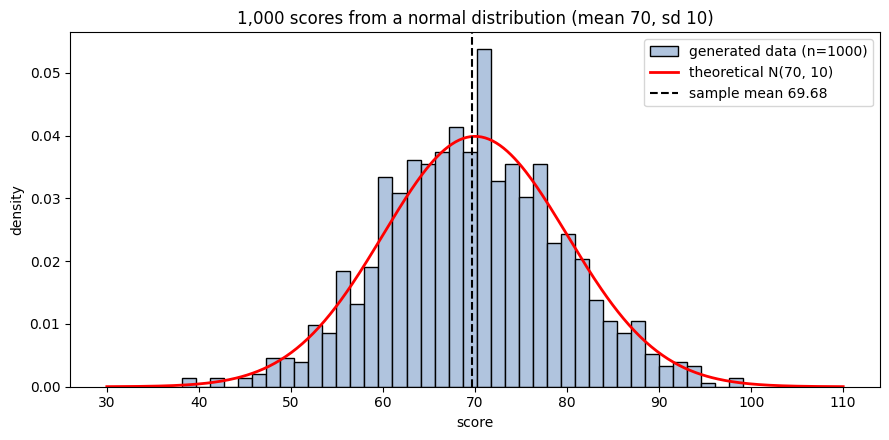

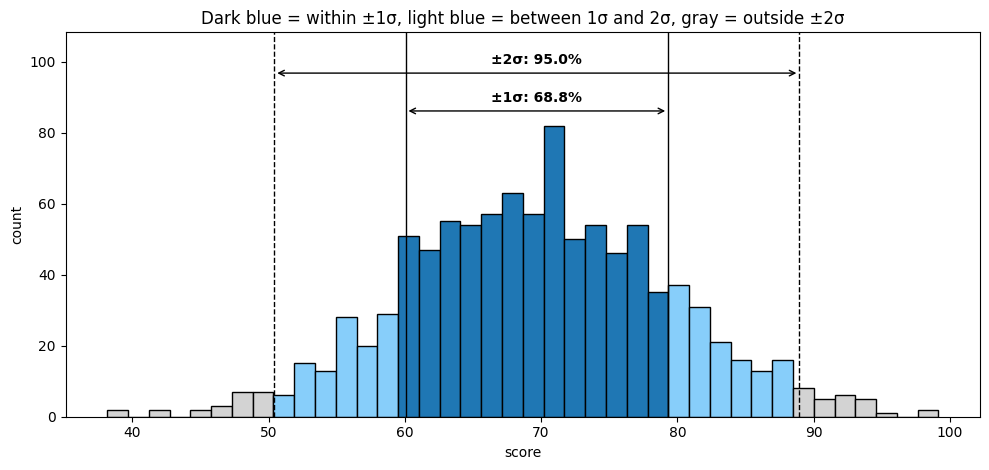

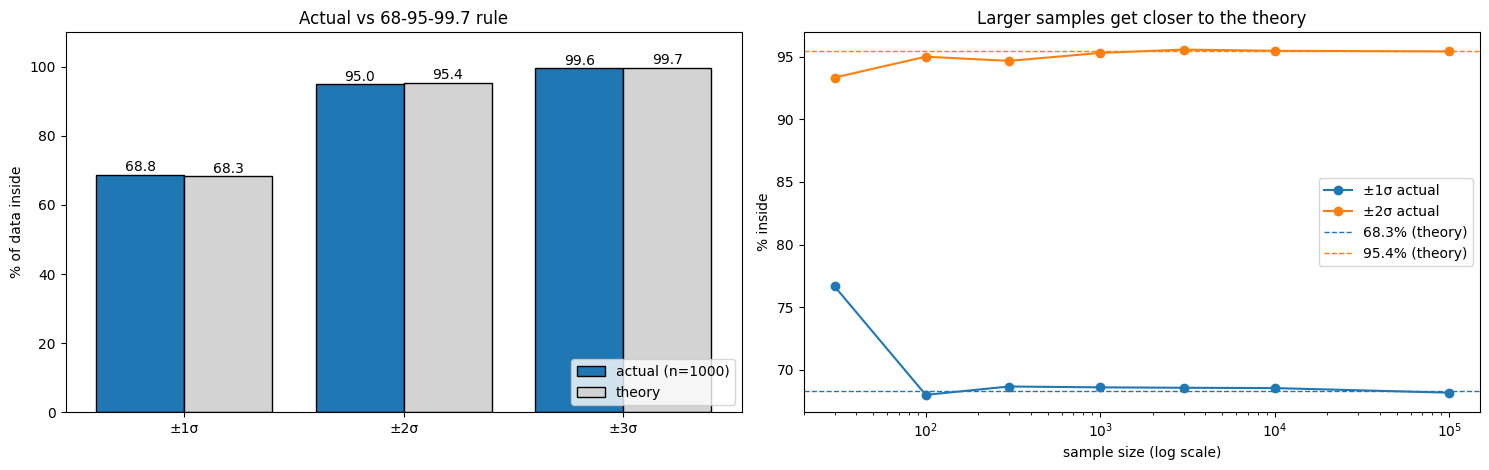

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.width', 200)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 1. 정규분포 데이터 1000개 생성
# ═════════════════════════════════════════════
header("1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.")

np.random.seed(2025)                      # 결과를 매번 같게 하려고 시드 고정
scores = np.random.normal(70, 10, 1000)
df9 = pd.DataFrame({'score': scores})

mu, sigma = scores.mean(), scores.std(ddof=1)   # 표본 평균·표본 표준편차 (pandas describe와 같은 방식)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(scores, bins=40, density=True, color='lightsteelblue', edgecolor='black', label='generated data (n=1000)')
x = np.linspace(30, 110, 400)
ax.plot(x, norm.pdf(x, 70, 10), color='red', lw=2, label='theoretical N(70, 10)')
ax.axvline(mu, color='black', linestyle='--', label=f'sample mean {mu:.2f}')
ax.set_xlabel('score')
ax.set_ylabel('density')
ax.set_title('1,000 scores from a normal distribution (mean 70, sd 10)')
ax.legend()
plt.tight_layout()
plt.show()

print(df9['score'].describe().round(2))
print(f"""
[답] np.random.normal(70, 10, 1000)으로 점수 1,000개를 만들었습니다.
     실제 표본 평균은 {mu:.2f}, 표본 표준편차는 {sigma:.2f}로, 설정값(70, 10)과 거의 같습니다.
     히스토그램이 빨간 이론 곡선과 겹치는 종 모양이라 정규분포를 잘 따른다는 것을 확인할 수 있습니다.
     (무작위로 뽑았기 때문에 설정값과 완전히 같지는 않고 조금씩 차이가 납니다.)""")

# ═════════════════════════════════════════════
# 2. ±1σ, ±2σ 범위 비율 계산
# ═════════════════════════════════════════════
header("2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.")

rows = []
for k in [1, 2, 3]:
    lo, hi = mu - k * sigma, mu + k * sigma
    inside = ((scores >= lo) & (scores <= hi))
    rows.append({'범위': f'±{k}σ', '구간': f'{lo:.1f} ~ {hi:.1f}', '포함 개수': int(inside.sum()),
                 '실제 비율(%)': round(inside.mean() * 100, 1)})
result = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.8))
counts, edges, patches = ax.hist(scores, bins=40, color='lightgray', edgecolor='black')
for p, left, right in zip(patches, edges[:-1], edges[1:]):
    center = (left + right) / 2
    if abs(center - mu) <= sigma:
        p.set_facecolor('tab:blue')
    elif abs(center - mu) <= 2 * sigma:
        p.set_facecolor('lightskyblue')
for k, ls in [(1, '-'), (2, '--')]:
    for sgn in [-1, 1]:
        ax.axvline(mu + sgn * k * sigma, color='black', linestyle=ls, lw=1)
top = counts.max()
ax.annotate('', xy=(mu - sigma, top * 1.05), xytext=(mu + sigma, top * 1.05), arrowprops=dict(arrowstyle='<->'))
ax.text(mu, top * 1.08, f'±1σ: {result.loc[0, "실제 비율(%)"]}%', ha='center', fontweight='bold')
ax.annotate('', xy=(mu - 2 * sigma, top * 1.18), xytext=(mu + 2 * sigma, top * 1.18), arrowprops=dict(arrowstyle='<->'))
ax.text(mu, top * 1.21, f'±2σ: {result.loc[1, "실제 비율(%)"]}%', ha='center', fontweight='bold')
ax.set_ylim(0, top * 1.32)
ax.set_xlabel('score')
ax.set_ylabel('count')
ax.set_title('Dark blue = within ±1σ, light blue = between 1σ and 2σ, gray = outside ±2σ')
plt.tight_layout()
plt.show()

print(result.to_string(index=False))
print(f"""
[답] 표본 평균 {mu:.2f}, 표본 표준편차 {sigma:.2f}를 기준으로 계산했습니다.
     · 평균 ±1σ ({result.loc[0, '구간']}점): {result.loc[0, '포함 개수']}개, {result.loc[0, '실제 비율(%)']}%
     · 평균 ±2σ ({result.loc[1, '구간']}점): {result.loc[1, '포함 개수']}개, {result.loc[1, '실제 비율(%)']}%
     · 참고로 평균 ±3σ ({result.loc[2, '구간']}점): {result.loc[2, '포함 개수']}개, {result.loc[2, '실제 비율(%)']}%
     즉 학생 대부분이 {result.loc[0, '구간']}점 사이에 몰려 있고, {result.loc[1, '구간']}점을 벗어나는 학생은
     {1000 - result.loc[1, '포함 개수']}명({100 - result.loc[1, '실제 비율(%)']:.1f}%)뿐입니다.""")

# ═════════════════════════════════════════════
# 3. 68-95-99 법칙과 비교
# ═════════════════════════════════════════════
header("3. 결과를 바탕으로 68-95-99 법칙과 비교해 봅시다.")

theory = [norm.cdf(k) - norm.cdf(-k) for k in [1, 2, 3]]
result['이론 비율(%)'] = [round(t * 100, 1) for t in theory]
result['차이(%p)'] = (result['실제 비율(%)'] - result['이론 비율(%)']).round(1)

# 표본 크기에 따라 실제 비율이 이론값에 얼마나 가까워지는지
sizes = [30, 100, 300, 1000, 3000, 10000, 100000]
rng = np.random.default_rng(1)
conv = []
for n in sizes:
    s = rng.normal(70, 10, n)
    m, sd = s.mean(), s.std(ddof=1)
    conv.append([np.mean(np.abs(s - m) <= k * sd) * 100 for k in [1, 2]])
conv = np.array(conv)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
xpos = np.arange(3)
ax[0].bar(xpos - 0.2, result['실제 비율(%)'], width=0.4, label='actual (n=1000)', color='tab:blue', edgecolor='black')
ax[0].bar(xpos + 0.2, result['이론 비율(%)'], width=0.4, label='theory', color='lightgray', edgecolor='black')
for i in range(3):
    ax[0].text(i - 0.2, result.loc[i, '실제 비율(%)'] + 1, f"{result.loc[i, '실제 비율(%)']}", ha='center')
    ax[0].text(i + 0.2, result.loc[i, '이론 비율(%)'] + 1, f"{result.loc[i, '이론 비율(%)']}", ha='center')
ax[0].set_xticks(xpos)
ax[0].set_xticklabels(['±1σ', '±2σ', '±3σ'])
ax[0].set_ylim(0, 110)
ax[0].set_ylabel('% of data inside')
ax[0].set_title('Actual vs 68-95-99.7 rule')
ax[0].legend(loc='lower right')

ax[1].plot(sizes, conv[:, 0], marker='o', label='±1σ actual')
ax[1].plot(sizes, conv[:, 1], marker='o', label='±2σ actual')
ax[1].axhline(theory[0] * 100, color='tab:blue', linestyle='--', lw=1, label='68.3% (theory)')
ax[1].axhline(theory[1] * 100, color='tab:orange', linestyle='--', lw=1, label='95.4% (theory)')
ax[1].set_xscale('log')
ax[1].set_xlabel('sample size (log scale)')
ax[1].set_ylabel('% inside')
ax[1].set_title('Larger samples get closer to the theory')
ax[1].legend(loc='center right')
plt.tight_layout()
plt.show()

print(result[['범위', '실제 비율(%)', '이론 비율(%)', '차이(%p)']].to_string(index=False))
print(f"""
[답] 68-95-99 법칙(정확히는 68-95-99.7 법칙)은 정규분포에서 데이터가
     평균 ±1σ 안에 약 68%, ±2σ 안에 약 95%, ±3σ 안에 약 99.7% 들어간다는 규칙입니다.
     · ±1σ: 실제 {result.loc[0, '실제 비율(%)']}% vs 이론 {result.loc[0, '이론 비율(%)']}% → 차이 {result.loc[0, '차이(%p)']:+.1f}%p
     · ±2σ: 실제 {result.loc[1, '실제 비율(%)']}% vs 이론 {result.loc[1, '이론 비율(%)']}% → 차이 {result.loc[1, '차이(%p)']:+.1f}%p
     · ±3σ: 실제 {result.loc[2, '실제 비율(%)']}% vs 이론 {result.loc[2, '이론 비율(%)']}% → 차이 {result.loc[2, '차이(%p)']:+.1f}%p
     세 구간 모두 차이가 {result['차이(%p)'].abs().max():.1f}%p 이내로, 실제 데이터가 68-95-99 법칙을 잘 따릅니다.

     완전히 같지 않은 이유는 1,000개를 무작위로 뽑은 '표본'이기 때문입니다.
     오른쪽 그래프처럼 표본이 30개일 때는 이론값과 차이가 크지만, 표본이 커질수록 실제 비율이 점선(이론값)에 가까워집니다.

     활용 의미
     · 이 법칙을 알면 평균과 표준편차만으로 분포를 빠르게 파악할 수 있습니다.
       예: 평균 70점, 표준편차 10점이면 약 68%의 학생이 60~80점, 약 95%가 50~90점 사이입니다.
     · 평균에서 2σ 이상 떨어진 값(이 데이터에서는 {mu - 2 * sigma:.0f}점 미만 또는 {mu + 2 * sigma:.0f}점 초과)은 전체의 약 5%뿐이라
       '드문 값'으로 보고, 이상값 후보로 확인하는 기준으로 쓸 수 있습니다.
     · 단, 이 법칙은 데이터가 정규분포일 때만 성립합니다. 앞의 소득 데이터처럼 한쪽으로 치우친 분포에는 그대로 적용하면 안 됩니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?
2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?
3. 표준편차는 왜 중요한 지표인가요?
4. 이 개념이 실제로 어떻게 활용될 수 있을까요?


══════════════════════════════════════════════════════════════════════
1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?
══════════════════════════════════════════════════════════════════════
범위        구간  포함 개수  실제 비율(%)
 ±1σ 60.1 ~ 79.3        688          68.8
 ±2σ 50.4 ~ 88.9        950          95.0
 ±3σ 40.8 ~ 98.6        996          99.6

[답] 표본 평균 69.68점, 표본 표준편차 9.63점을 기준으로 계산했습니다.
     · ±1σ (60.1 ~ 79.3점): 1,000개 중 688개 → 68.8%
     · ±2σ (50.4 ~ 88.9점): 1,000개 중 950개 → 95.0%

══════════════════════════════════════════════════════════════════════
2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?
══════════════════════════════════════════════════════════════════════
범위  실제 비율(%)  이론 비율(%)  차이(%p)
 ±1σ          68.8          68.3       0.5
 ±2σ          95.0          95.4      -0.4
 ±3σ          99.6          99.7      -0.1

[답] 매우 비슷했습니다. 이론값과의 차이가 ±1σ +0.5%p, ±2σ -0.4%p,
     ±3σ -0.1%p로 모두 0.5%p 이내입니다.
     완전히 같지 않은 것은 1,000개 표본을 무작위로 뽑았기 때문에 생긴 자연스러운 오차입니다.
     오른쪽 그래프처럼 표본이 30개일 때는 ±1σ 비율이 76.7%로

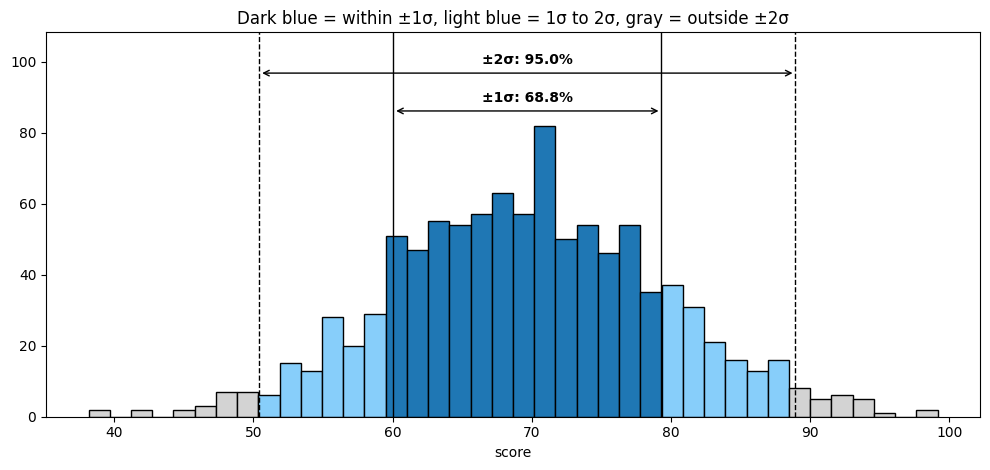

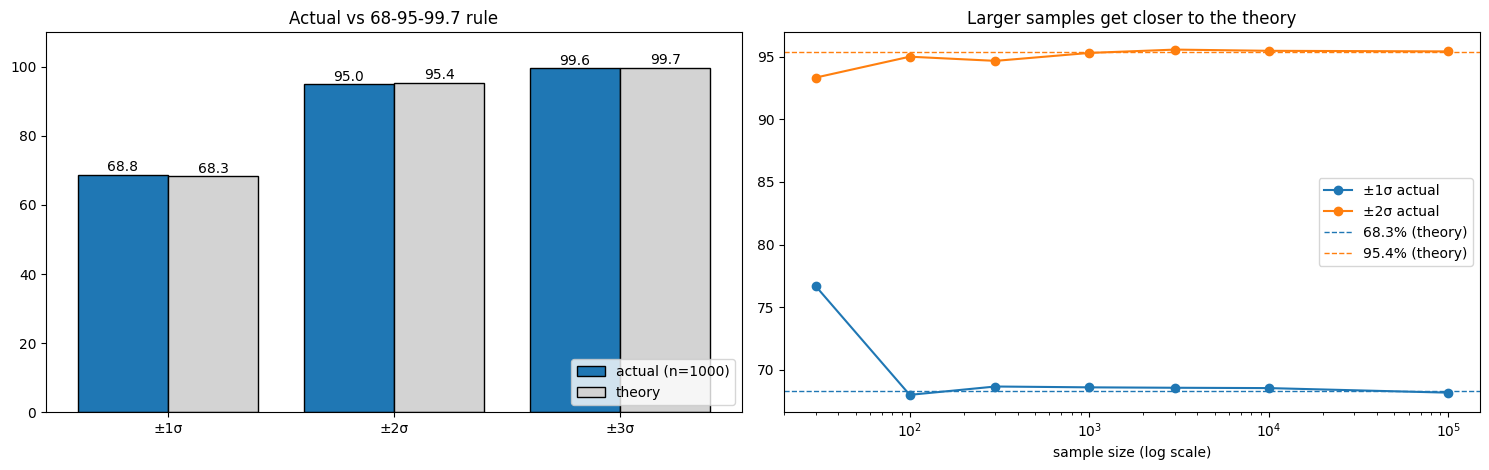

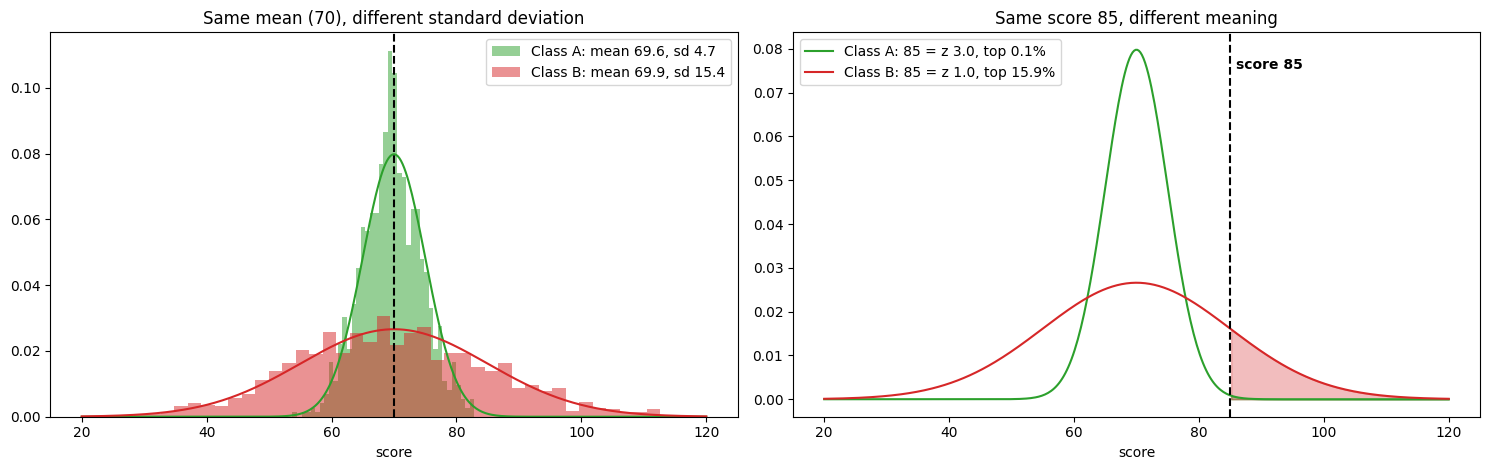

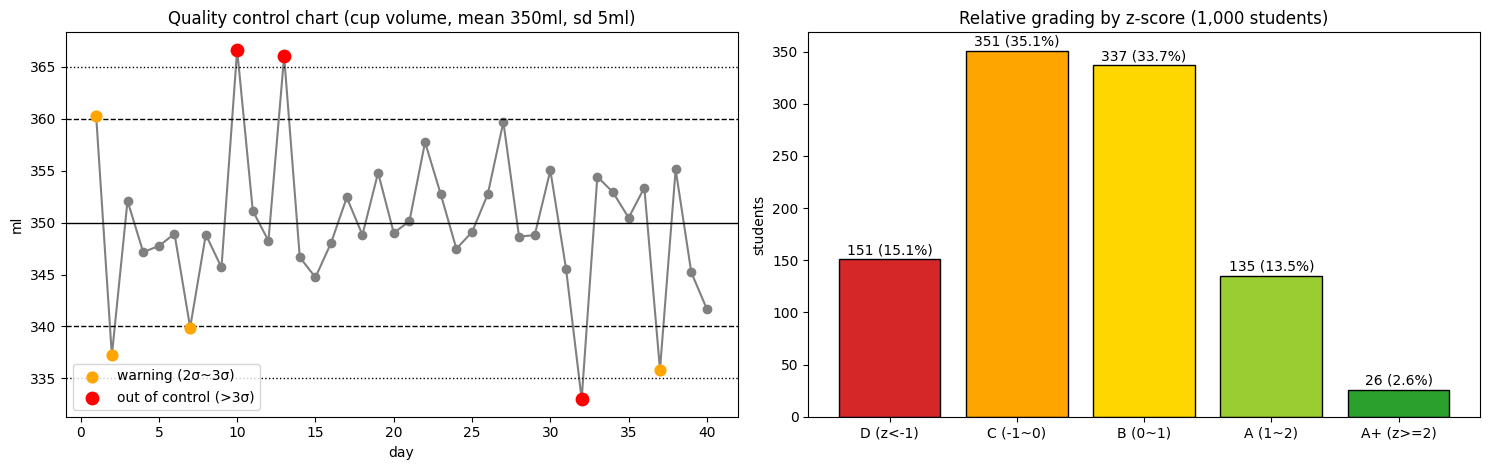

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.width', 200)

# 데이터 생성 (앞 문제와 같은 데이터)
np.random.seed(2025)
scores = np.random.normal(70, 10, 1000)
mu, sigma = scores.mean(), scores.std(ddof=1)

# ±kσ 범위의 실제 비율과 이론 비율
rows = []
for k in [1, 2, 3]:
    inside = np.abs(scores - mu) <= k * sigma
    rows.append({'범위': f'±{k}σ', '구간': f'{mu - k * sigma:.1f} ~ {mu + k * sigma:.1f}',
                 '포함 개수': int(inside.sum()), '실제 비율(%)': round(inside.mean() * 100, 1),
                 '이론 비율(%)': round((norm.cdf(k) - norm.cdf(-k)) * 100, 1)})
result = pd.DataFrame(rows)
result['차이(%p)'] = (result['실제 비율(%)'] - result['이론 비율(%)']).round(1)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 1. ±1σ, ±2σ 범위의 실제 비율
# ═════════════════════════════════════════════
header("1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?")

fig, ax = plt.subplots(figsize=(10, 4.8))
counts, edges, patches = ax.hist(scores, bins=40, color='lightgray', edgecolor='black')
for p, left, right in zip(patches, edges[:-1], edges[1:]):
    c = (left + right) / 2
    if abs(c - mu) <= sigma:
        p.set_facecolor('tab:blue')
    elif abs(c - mu) <= 2 * sigma:
        p.set_facecolor('lightskyblue')
top = counts.max()
for k, y, ls in [(1, 1.05, '-'), (2, 1.18, '--')]:
    for sgn in [-1, 1]:
        ax.axvline(mu + sgn * k * sigma, color='black', linestyle=ls, lw=1)
    ax.annotate('', xy=(mu - k * sigma, top * y), xytext=(mu + k * sigma, top * y), arrowprops=dict(arrowstyle='<->'))
    ax.text(mu, top * (y + 0.03), f'±{k}σ: {result.loc[k - 1, "실제 비율(%)"]}%', ha='center', fontweight='bold')
ax.set_ylim(0, top * 1.32)
ax.set_xlabel('score')
ax.set_title('Dark blue = within ±1σ, light blue = 1σ to 2σ, gray = outside ±2σ')
plt.tight_layout()
plt.show()

print(result[['범위', '구간', '포함 개수', '실제 비율(%)']].to_string(index=False))
print(f"""
[답] 표본 평균 {mu:.2f}점, 표본 표준편차 {sigma:.2f}점을 기준으로 계산했습니다.
     · ±1σ ({result.loc[0, '구간']}점): 1,000개 중 {result.loc[0, '포함 개수']}개 → {result.loc[0, '실제 비율(%)']}%
     · ±2σ ({result.loc[1, '구간']}점): 1,000개 중 {result.loc[1, '포함 개수']}개 → {result.loc[1, '실제 비율(%)']}%""")

# ═════════════════════════════════════════════
# 2. 68-95-99 법칙과 비교
# ═════════════════════════════════════════════
header("2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?")

sizes = [30, 100, 300, 1000, 3000, 10000, 100000]
rng = np.random.default_rng(1)
conv = []
for n in sizes:
    s = rng.normal(70, 10, n)
    conv.append([np.mean(np.abs(s - s.mean()) <= k * s.std(ddof=1)) * 100 for k in [1, 2]])
conv = np.array(conv)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
xpos = np.arange(3)
ax[0].bar(xpos - 0.2, result['실제 비율(%)'], width=0.4, label='actual (n=1000)', color='tab:blue', edgecolor='black')
ax[0].bar(xpos + 0.2, result['이론 비율(%)'], width=0.4, label='theory', color='lightgray', edgecolor='black')
for i in range(3):
    ax[0].text(i - 0.2, result.loc[i, '실제 비율(%)'] + 1, f"{result.loc[i, '실제 비율(%)']}", ha='center')
    ax[0].text(i + 0.2, result.loc[i, '이론 비율(%)'] + 1, f"{result.loc[i, '이론 비율(%)']}", ha='center')
ax[0].set_xticks(xpos)
ax[0].set_xticklabels(['±1σ', '±2σ', '±3σ'])
ax[0].set_ylim(0, 110)
ax[0].set_title('Actual vs 68-95-99.7 rule')
ax[0].legend(loc='lower right')
ax[1].plot(sizes, conv[:, 0], marker='o', label='±1σ actual')
ax[1].plot(sizes, conv[:, 1], marker='o', label='±2σ actual')
ax[1].axhline(result.loc[0, '이론 비율(%)'], color='tab:blue', linestyle='--', lw=1, label='68.3% (theory)')
ax[1].axhline(result.loc[1, '이론 비율(%)'], color='tab:orange', linestyle='--', lw=1, label='95.4% (theory)')
ax[1].set_xscale('log')
ax[1].set_xlabel('sample size (log scale)')
ax[1].set_title('Larger samples get closer to the theory')
ax[1].legend(loc='center right')
plt.tight_layout()
plt.show()

print(result[['범위', '실제 비율(%)', '이론 비율(%)', '차이(%p)']].to_string(index=False))
print(f"""
[답] 매우 비슷했습니다. 이론값과의 차이가 ±1σ {result.loc[0, '차이(%p)']:+.1f}%p, ±2σ {result.loc[1, '차이(%p)']:+.1f}%p,
     ±3σ {result.loc[2, '차이(%p)']:+.1f}%p로 모두 {result['차이(%p)'].abs().max():.1f}%p 이내입니다.
     완전히 같지 않은 것은 1,000개 표본을 무작위로 뽑았기 때문에 생긴 자연스러운 오차입니다.
     오른쪽 그래프처럼 표본이 30개일 때는 ±1σ 비율이 {conv[0, 0]:.1f}%로 이론값과 꽤 다르지만,
     표본이 커질수록 점선(이론값)에 가까워집니다. 데이터가 많을수록 68–95–99 법칙이 더 정확히 맞습니다.""")

# ═════════════════════════════════════════════
# 3. 표준편차가 중요한 이유
# ═════════════════════════════════════════════
header("3. 표준편차는 왜 중요한 지표인가요?")

rng = np.random.default_rng(7)
class_a = rng.normal(70, 5, 1000)    # 평균 같고 표준편차 작음
class_b = rng.normal(70, 15, 1000)   # 평균 같고 표준편차 큼
x = np.linspace(20, 120, 400)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].hist(class_a, bins=40, density=True, alpha=0.5, color='tab:green', label=f'Class A: mean {class_a.mean():.1f}, sd {class_a.std(ddof=1):.1f}')
ax[0].hist(class_b, bins=40, density=True, alpha=0.5, color='tab:red', label=f'Class B: mean {class_b.mean():.1f}, sd {class_b.std(ddof=1):.1f}')
ax[0].plot(x, norm.pdf(x, 70, 5), color='tab:green')
ax[0].plot(x, norm.pdf(x, 70, 15), color='tab:red')
ax[0].axvline(70, color='black', linestyle='--')
ax[0].set_title('Same mean (70), different standard deviation')
ax[0].set_xlabel('score')
ax[0].legend()

# 같은 85점이라도 표준편차에 따라 위치(z점수·상위 %)가 달라짐
z_a, z_b = (85 - 70) / 5, (85 - 70) / 15
top_a, top_b = (1 - norm.cdf(z_a)) * 100, (1 - norm.cdf(z_b)) * 100
ax[1].plot(x, norm.pdf(x, 70, 5), color='tab:green', label=f'Class A: 85 = z {z_a:.1f}, top {top_a:.1f}%')
ax[1].fill_between(x, norm.pdf(x, 70, 5), where=x >= 85, color='tab:green', alpha=0.4)
ax[1].plot(x, norm.pdf(x, 70, 15), color='tab:red', label=f'Class B: 85 = z {z_b:.1f}, top {top_b:.1f}%')
ax[1].fill_between(x, norm.pdf(x, 70, 15), where=x >= 85, color='tab:red', alpha=0.3)
ax[1].axvline(85, color='black', linestyle='--')
ax[1].text(86, ax[1].get_ylim()[1] * 0.9, 'score 85', fontweight='bold')
ax[1].set_title('Same score 85, different meaning')
ax[1].set_xlabel('score')
ax[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

comp = pd.DataFrame({
    '반': ['A반 (σ=5)', 'B반 (σ=15)'],
    '평균': [70, 70],
    '±1σ 범위(68%)': ['65 ~ 75점', '55 ~ 85점'],
    '±2σ 범위(95%)': ['60 ~ 80점', '40 ~ 100점'],
    '85점의 z점수': [round(z_a, 1), round(z_b, 1)],
    '85점의 위치': [f'상위 {top_a:.1f}%', f'상위 {top_b:.1f}%'],
})
print(comp.to_string(index=False))
print(f"""
[답] 표준편차는 데이터가 평균에서 얼마나 퍼져 있는지를 하나의 숫자로 보여 주기 때문에 중요합니다.
  · 평균만으로는 부족합니다: A반과 B반은 평균이 똑같이 70점이지만, A반은 학생 68%가 65~75점에 모여 있고
    B반은 55~85점으로 넓게 퍼져 있습니다. 평균만 보면 두 반이 같아 보이지만 실제 모습은 전혀 다릅니다.
  · 개별 값의 위치를 알려 줍니다: 같은 85점이라도 A반에서는 평균보다 표준편차 {z_a:.0f}개만큼 높아 상위 {top_a:.1f}%의 최상위권이고,
    B반에서는 표준편차 {z_b:.0f}개만큼 높아 상위 {top_b:.1f}% 정도입니다. 이렇게 (값 − 평균) ÷ 표준편차로 계산한 값을 z점수라고 합니다.
  · 예측과 판단의 기준이 됩니다: 68–95–99 법칙처럼, 평균과 표준편차만 알면 데이터가 어느 범위에 몇 % 있는지 예상할 수 있고,
    평균에서 2σ나 3σ 이상 떨어진 값을 '드문 값(이상값 후보)'으로 판단할 수 있습니다.
  · 신뢰도를 보여 줍니다: 표준편차가 작으면 결과가 안정적이고 예측이 쉽고, 크면 들쭉날쭉해서 평균만 믿기 어렵습니다.""")

# ═════════════════════════════════════════════
# 4. 실제 활용
# ═════════════════════════════════════════════
header("4. 이 개념이 실제로 어떻게 활용될 수 있을까요?")

# (1) 품질 관리: 공정 관리도 (예: 커피 1잔 용량 350ml, 표준편차 5ml)
rng = np.random.default_rng(3)
daily = rng.normal(350, 5, 40)
daily[[12, 31]] = [366, 333]                        # 이상 공정 예시 2건
c_mu, c_sd = 350, 5
out = np.abs(daily - c_mu) > 3 * c_sd
warn = (np.abs(daily - c_mu) > 2 * c_sd) & ~out

# (2) 성적 등급: z점수로 상대평가 구간 나누기 (이 데이터 1,000명 기준)
z = (scores - mu) / sigma
bins = [-np.inf, -1, 0, 1, 2, np.inf]
labels = ['D (z<-1)', 'C (-1~0)', 'B (0~1)', 'A (1~2)', 'A+ (z>=2)']
grade = pd.cut(z, bins=bins, labels=labels, right=False)
grade_cnt = pd.Series(grade).value_counts().reindex(labels)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].plot(range(1, 41), daily, marker='o', color='gray')
ax[0].scatter(np.where(warn)[0] + 1, daily[warn], color='orange', zorder=3, s=60, label='warning (2σ~3σ)')
ax[0].scatter(np.where(out)[0] + 1, daily[out], color='red', zorder=3, s=80, label='out of control (>3σ)')
for k, ls in [(0, '-'), (2, '--'), (3, ':')]:
    for sgn in ([1] if k == 0 else [-1, 1]):
        ax[0].axhline(c_mu + sgn * k * c_sd, color='black', linestyle=ls, lw=1)
ax[0].set_title('Quality control chart (cup volume, mean 350ml, sd 5ml)')
ax[0].set_xlabel('day')
ax[0].set_ylabel('ml')
ax[0].legend(loc='lower left')

bars = ax[1].bar(labels, grade_cnt.values, color=['tab:red', 'orange', 'gold', 'yellowgreen', 'tab:green'], edgecolor='black')
for b, v in zip(bars, grade_cnt.values):
    ax[1].text(b.get_x() + b.get_width() / 2, v + 5, f'{v} ({v / 10:.1f}%)', ha='center')
ax[1].set_title('Relative grading by z-score (1,000 students)')
ax[1].set_ylabel('students')
plt.tight_layout()
plt.show()

print("[성적 등급 예시: z점수 기준 학생 수]")
print(pd.DataFrame({'학생 수': grade_cnt, '비율(%)': (grade_cnt / 10).round(1)}))
print(f"""
[답] 평균과 표준편차, 68–95–99 법칙은 '정상 범위'와 '드문 값'을 나누는 기준으로 여러 분야에서 쓰입니다.
  · 품질 관리 (왼쪽 그래프): 커피 1잔 용량이 평균 350ml, 표준편차 5ml라면 99.7%가 335~365ml 안에 들어와야 합니다.
    이 범위(±3σ)를 벗어난 날(빨간 점 {out.sum()}건)은 기계 고장 같은 이상으로 보고 점검하고,
    ±2σ~3σ 사이(주황 점 {warn.sum()}건)는 경고로 보고 지켜봅니다. 제조업의 관리도와 식스시그마가 이 원리입니다.
  · 성적 평가 (오른쪽 그래프): 점수를 z점수로 바꾸면 시험 난이도가 달라도 학생의 상대적 위치를 비교할 수 있습니다.
    수능 표준점수와 백분위, 상대평가 등급이 이 방식입니다. 이 데이터에서 z≥2인 학생은 {grade_cnt.iloc[-1]}명({grade_cnt.iloc[-1] / 10:.1f}%)으로, 이론값(상위 약 2.3%)과 비슷합니다.
  · 이상 거래 탐지: 평소 카드 결제 금액의 평균과 표준편차를 계산해 두고, 평균보다 3σ 이상 큰 결제가 생기면 사기 의심으로 알림을 보냅니다.
  · 재고·수요 예측: 하루 판매량 평균이 100개, 표준편차가 15개라면 재고를 130개(평균+2σ) 준비했을 때 약 97.7%의 날은 품절이 나지 않습니다.
  · 금융 위험 관리: 주식 수익률의 표준편차(변동성)가 클수록 위험한 자산으로 보고, 투자 비중을 조절합니다.

  주의할 점: 이 활용은 데이터가 정규분포에 가까울 때 정확합니다. 소득이나 집값처럼 한쪽으로 치우친 데이터는
  로그 변환을 하거나, 앞에서 배운 IQR 기준처럼 분포 모양에 덜 민감한 방법을 함께 써야 합니다.""")

# 문제 10. 표본 평균 실험

**📘 문제**

- 큰 모집단에서 표본을 여러 번 추출하여 표본 평균의 분포를 비교해봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.
2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다:
   - 표본 크기 5
   - 표본 크기 50
3. 두 조건의 **표본 평균 분포(histogram)**를 비교합니다.


══════════════════════════════════════════════════════════════════════
1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.
══════════════════════════════════════════════════════════════════════
[답] np.random.normal(100, 15, 100000)으로 100,000개짜리 모집단을 만들었습니다.
     모집단 평균은 99.95, 모집단 표준편차는 15.03로 설정값(100, 15)과 거의 같습니다.
     이 모집단에서 표본을 반복해서 뽑아, 표본 평균이 어떻게 분포하는지 살펴봅니다.

══════════════════════════════════════════════════════════════════════
2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다: 표본 크기 5 / 표본 크기 50
══════════════════════════════════════════════════════════════════════
 표본 크기  반복 횟수  표본 평균들의 평균  표본 평균들의 표준편차  최소  최대
         5       1000               99.92                    6.67  78.2 121.7
        50       1000               99.93                    2.14  93.0 107.1

[답] 모집단에서 표본을 뽑아 평균을 구하는 일을 표본 크기별로 1,000번씩 반복했습니다.
     · 표본 크기 5: 표본 평균이 78.2 ~ 121.7 사이에서 크게 출렁입니다.
     · 표본 크기 50: 표본 평균이 93.0 ~ 107.1 사이로, 모집단 평균 근처에 훨씬 촘촘하게 모입니다.
     위 그래프는 처음 50번의 표본 평균을 순서대로 그린 것으로, 표본 크기 5일 때 점들이 빨간 선(모집단 평균)에서 더 멀리 튑

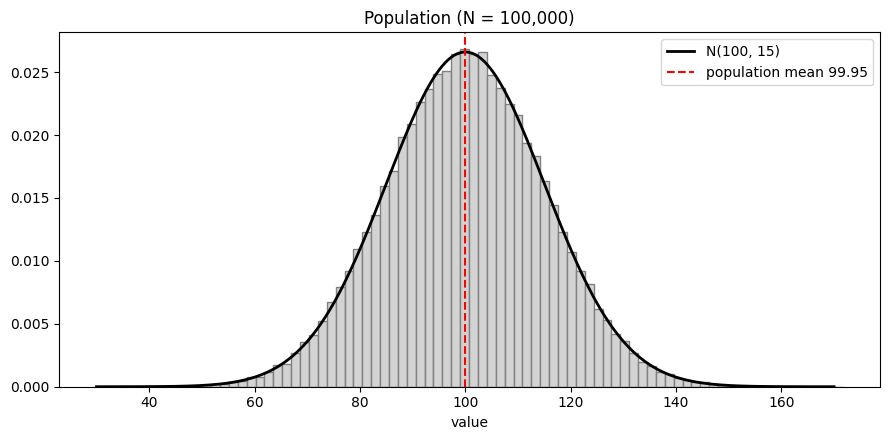

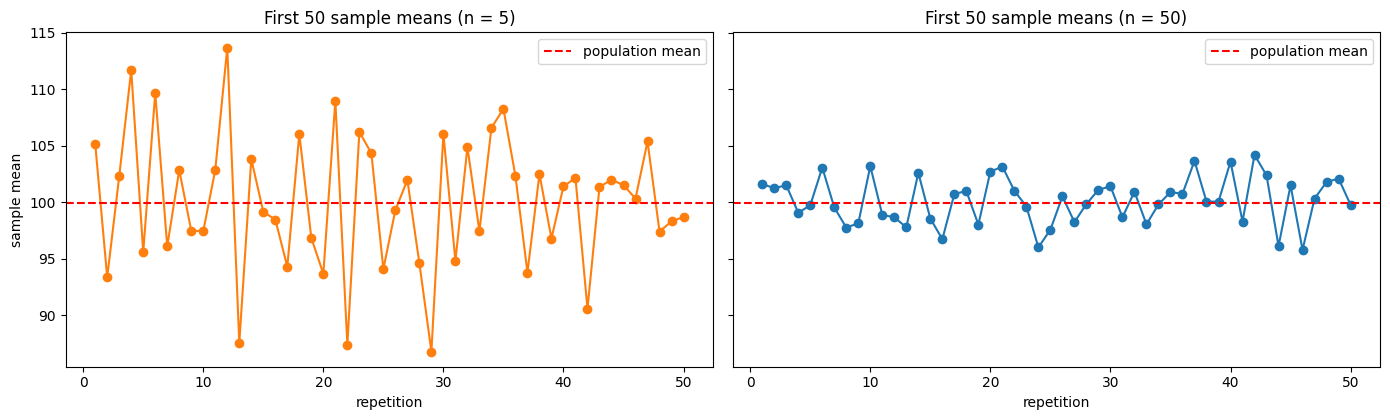

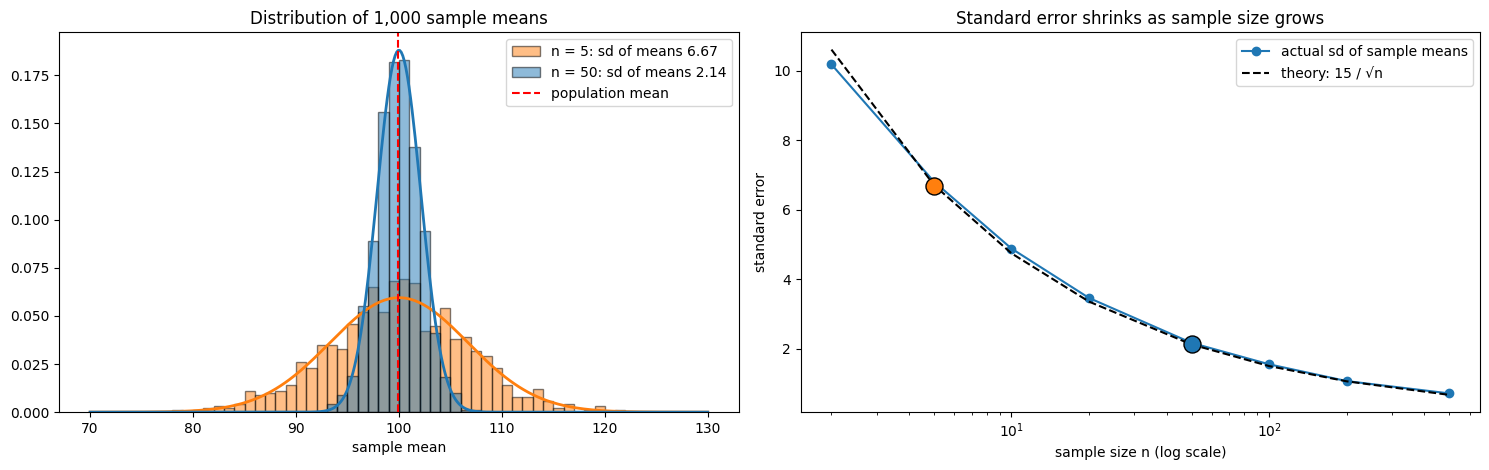

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.width', 200)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

np.random.seed(2025)   # 결과를 매번 같게 하려고 시드 고정

# ═════════════════════════════════════════════
# 1. 모집단 생성
# ═════════════════════════════════════════════
header("1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.")

POP_SIZE = 100_000
population = np.random.normal(100, 15, POP_SIZE)
pop_mu, pop_sd = population.mean(), population.std()   # 모집단 전체이므로 ddof=0

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(population, bins=80, density=True, color='lightgray', edgecolor='gray')
x = np.linspace(30, 170, 400)
ax.plot(x, norm.pdf(x, 100, 15), color='black', lw=2, label='N(100, 15)')
ax.axvline(pop_mu, color='red', linestyle='--', label=f'population mean {pop_mu:.2f}')
ax.set_title(f'Population (N = {POP_SIZE:,})')
ax.set_xlabel('value')
ax.legend()
plt.tight_layout()
plt.show()

print(f"""[답] np.random.normal(100, 15, {POP_SIZE})으로 {POP_SIZE:,}개짜리 모집단을 만들었습니다.
     모집단 평균은 {pop_mu:.2f}, 모집단 표준편차는 {pop_sd:.2f}로 설정값(100, 15)과 거의 같습니다.
     이 모집단에서 표본을 반복해서 뽑아, 표본 평균이 어떻게 분포하는지 살펴봅니다.""")

# ═════════════════════════════════════════════
# 2. 표본 크기 5, 50으로 각각 1000번 표본 평균 구하기
# ═════════════════════════════════════════════
header("2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다: 표본 크기 5 / 표본 크기 50")

N_REPEAT = 1000
SIZES = [5, 50]
means = {n: np.array([np.random.choice(population, n, replace=False).mean() for _ in range(N_REPEAT)])
         for n in SIZES}

# 예시: 처음 몇 개의 표본 평균이 어떻게 나왔는지
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for a, n, c in zip(ax, SIZES, ['tab:orange', 'tab:blue']):
    a.plot(range(1, 51), means[n][:50], marker='o', color=c)
    a.axhline(pop_mu, color='red', linestyle='--', label='population mean')
    a.set_title(f'First 50 sample means (n = {n})')
    a.set_xlabel('repetition')
    a.legend()
ax[0].set_ylabel('sample mean')
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    '표본 크기': SIZES,
    '반복 횟수': [N_REPEAT] * 2,
    '표본 평균들의 평균': [means[n].mean().round(2) for n in SIZES],
    '표본 평균들의 표준편차': [means[n].std(ddof=1).round(2) for n in SIZES],
    '최소': [means[n].min().round(1) for n in SIZES],
    '최대': [means[n].max().round(1) for n in SIZES],
})
print(summary.to_string(index=False))
print(f"""
[답] 모집단에서 표본을 뽑아 평균을 구하는 일을 표본 크기별로 1,000번씩 반복했습니다.
     · 표본 크기 5: 표본 평균이 {means[5].min():.1f} ~ {means[5].max():.1f} 사이에서 크게 출렁입니다.
     · 표본 크기 50: 표본 평균이 {means[50].min():.1f} ~ {means[50].max():.1f} 사이로, 모집단 평균 근처에 훨씬 촘촘하게 모입니다.
     위 그래프는 처음 50번의 표본 평균을 순서대로 그린 것으로, 표본 크기 5일 때 점들이 빨간 선(모집단 평균)에서 더 멀리 튑니다.""")

# ═════════════════════════════════════════════
# 3. 표본 평균 분포(histogram) 비교
# ═════════════════════════════════════════════
header("3. 두 조건의 표본 평균 분포(histogram)를 비교합니다.")

theory_se = {n: 15 / np.sqrt(n) for n in SIZES}       # 이론적 표준오차 σ/√n
actual_se = {n: means[n].std(ddof=1) for n in SIZES}
within5 = {n: np.mean(np.abs(means[n] - pop_mu) <= 5) * 100 for n in SIZES}

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
bins = np.linspace(70, 130, 61)
x = np.linspace(70, 130, 400)
for n, c in zip(SIZES, ['tab:orange', 'tab:blue']):
    ax[0].hist(means[n], bins=bins, density=True, alpha=0.5, color=c, edgecolor='black',
               label=f'n = {n}: sd of means {actual_se[n]:.2f}')
    ax[0].plot(x, norm.pdf(x, 100, theory_se[n]), color=c, lw=2)
ax[0].axvline(pop_mu, color='red', linestyle='--', label='population mean')
ax[0].set_title('Distribution of 1,000 sample means')
ax[0].set_xlabel('sample mean')
ax[0].legend()

# 표본 크기를 늘릴수록 표준오차가 σ/√n으로 줄어드는 모습
ns = [2, 5, 10, 20, 50, 100, 200, 500]
emp = [np.std([np.random.choice(population, n, replace=False).mean() for _ in range(500)], ddof=1) for n in ns]
ax[1].plot(ns, emp, marker='o', label='actual sd of sample means')
ax[1].plot(ns, [15 / np.sqrt(n) for n in ns], linestyle='--', color='black', label='theory: 15 / √n')
for n, c in zip(SIZES, ['tab:orange', 'tab:blue']):
    ax[1].scatter(n, actual_se[n], s=150, color=c, zorder=3, edgecolor='black')
ax[1].set_xscale('log')
ax[1].set_xlabel('sample size n (log scale)')
ax[1].set_ylabel('standard error')
ax[1].set_title('Standard error shrinks as sample size grows')
ax[1].legend()
plt.tight_layout()
plt.show()

comp = pd.DataFrame({
    '표본 크기': SIZES,
    '실제 표준편차(표준오차)': [round(actual_se[n], 2) for n in SIZES],
    '이론 표준오차 15/√n': [round(theory_se[n], 2) for n in SIZES],
    '모집단 평균 ±5 안에 든 비율(%)': [round(within5[n], 1) for n in SIZES],
})
print(comp.to_string(index=False))
print(f"""
[답] 두 히스토그램 모두 모집단 평균({pop_mu:.1f}) 근처에 중심이 있는 종 모양이지만, 퍼진 정도가 크게 다릅니다.
  · 중심: 표본 평균들의 평균은 n=5일 때 {means[5].mean():.2f}, n=50일 때 {means[50].mean():.2f}로 둘 다 모집단 평균과 거의 같습니다.
    즉 표본 크기와 상관없이 표본 평균은 평균적으로 모집단 평균을 정확히 맞힙니다.
  · 퍼짐: 표본 평균의 표준편차(표준오차)는 n=5일 때 {actual_se[5]:.2f}, n=50일 때 {actual_se[50]:.2f}로 약 {actual_se[5] / actual_se[50]:.1f}배 차이가 납니다.
    이는 이론값 15/√n (n=5: {theory_se[5]:.2f}, n=50: {theory_se[50]:.2f})과 거의 일치합니다.
    표본 크기가 10배 커지면 표준오차는 √10 ≈ 3.2배 줄어듭니다.
  · 정확도: 표본 평균이 모집단 평균 ±5 안에 들어온 비율은 n=5일 때 {within5[5]:.1f}%, n=50일 때 {within5[50]:.1f}%입니다.
    표본을 50개 뽑으면 거의 항상 모집단 평균에 가까운 값을 얻지만, 5개만 뽑으면 크게 빗나갈 때가 많습니다.

  정리하면, 표본 평균의 분포는 모집단 평균을 중심으로 하는 정규분포에 가깝고(중심극한정리),
  그 퍼짐은 σ/√n으로 표본 크기가 클수록 좁아집니다. 그래서 여론조사나 실험에서 표본을 충분히 크게 뽑아야
  추정이 정확해지며, 오른쪽 그래프처럼 표본을 늘릴수록 정확도는 좋아지지만 늘어나는 폭은 점점 작아집니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. **표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?**
2. **왜 표본 크기가 중요할까요?**
3. **이 개념은 실제로 어디에 활용될 수 있을까요?**


══════════════════════════════════════════════════════════════════════
1. 표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?
══════════════════════════════════════════════════════════════════════
 표본 크기  중심(평균)  퍼짐(표준편차)  IQR  최소 ~ 최대  왜도
         5       99.92            6.67 8.68 78.2 ~ 121.7 -0.04
        50       99.93            2.14 2.86 93.0 ~ 107.1 -0.04

[답] 중심은 같고, 퍼짐이 크게 달라졌습니다.
  · 중심: 두 분포 모두 모집단 평균(99.9) 근처에 중심이 있습니다 (n=5: 99.92, n=50: 99.93).
  · 퍼짐: 표준편차가 n=5일 때 6.67, n=50일 때 2.14로, 표본이 커지자 분포 폭이 약 3.1분의 1로 좁아졌습니다.
    가운데 95%가 들어가는 범위도 n=5는 약 26.2점 폭, n=50은 약 8.4점 폭입니다.
  · 극단값: n=5에서는 모집단 평균에서 최대 21.8점까지 벗어난 표본 평균이 나왔지만,
    n=50에서는 가장 멀리 벗어난 값도 7.1점 차이에 그쳤습니다.
  · 모양: 두 분포 모두 좌우대칭인 종 모양(왜도 0 근처)이고, 박스플롯에서도 n=50의 상자가 훨씬 납작합니다.

══════════════════════════════════════════════════════════════════════
2. 왜 표본 크기가 중요할까요?
══════════════════════════════════════════════════════════════════════
 표본 크기  5점 넘게 빗나갈 확률(%)  95% 범위 폭(점)
         2                     62.6             41.6
         5

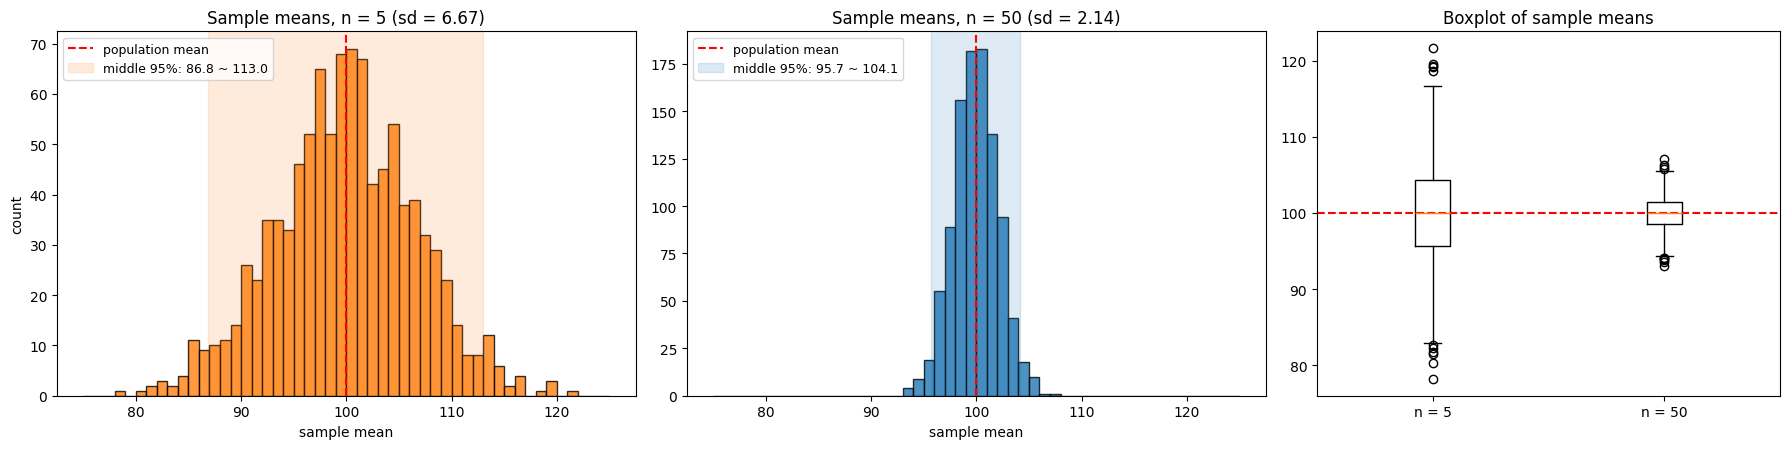

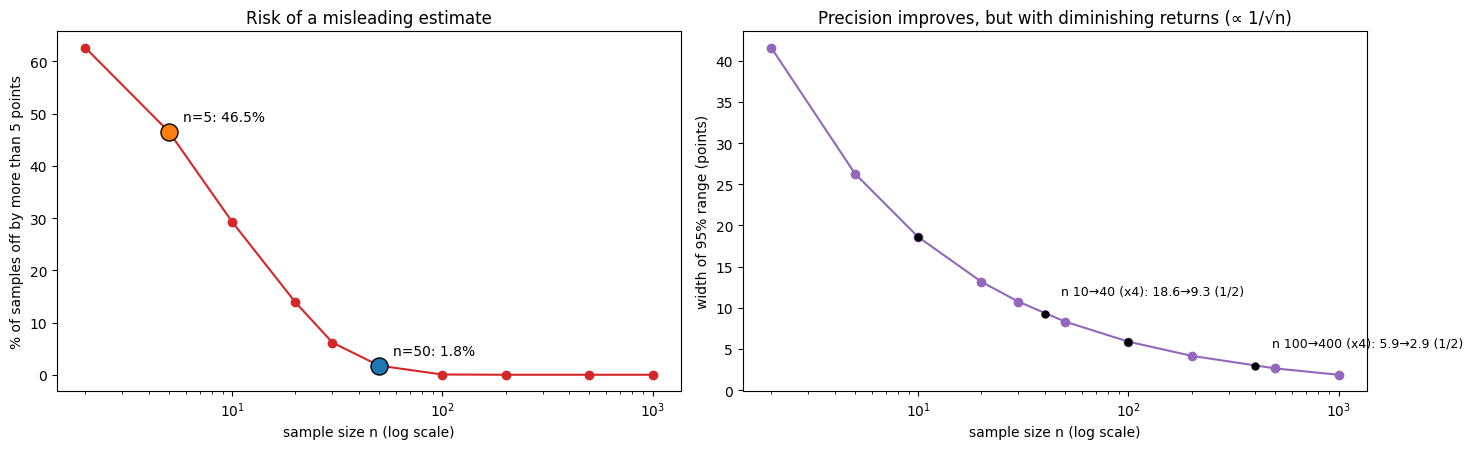

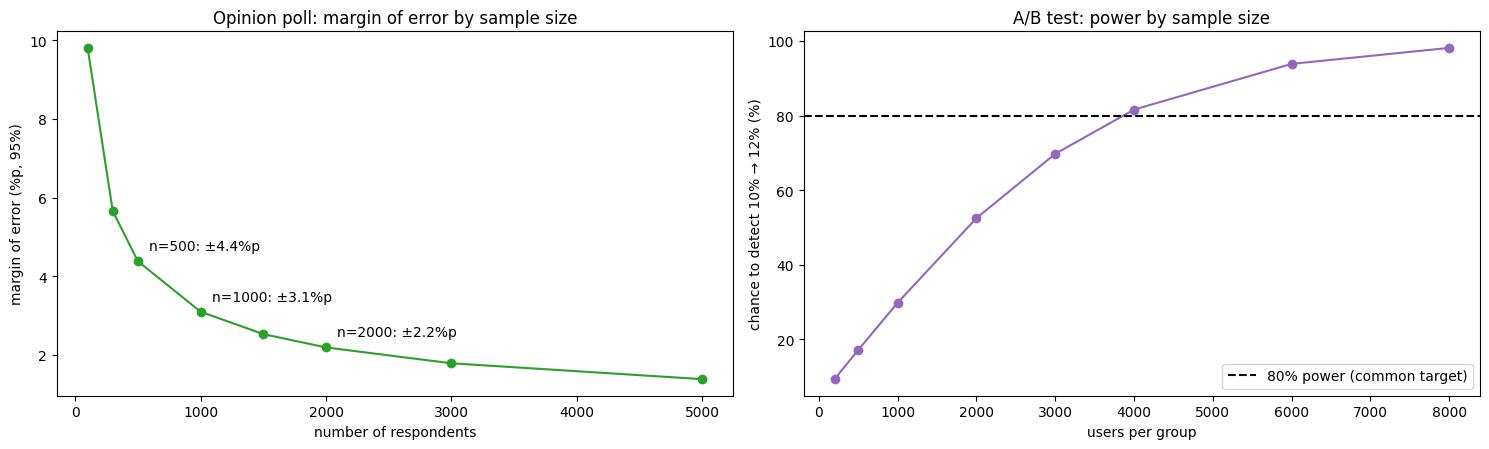

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.width', 200)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# 데이터 생성 (앞 문제와 같은 데이터: 모집단 10만 개, 표본 크기 5·50으로 각 1,000번)
np.random.seed(2025)
population = np.random.normal(100, 15, 100_000)
pop_mu, pop_sd = population.mean(), population.std()
SIZES = [5, 50]
means = {n: np.array([np.random.choice(population, n, replace=False).mean() for _ in range(1000)])
         for n in SIZES}
se = {n: means[n].std(ddof=1) for n in SIZES}
COL = {5: 'tab:orange', 50: 'tab:blue'}

# ═════════════════════════════════════════════
# 1. 표본 크기에 따른 표본 평균 분포의 차이
# ═════════════════════════════════════════════
header("1. 표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={'width_ratios': [1, 1, 0.8]})
bins = np.linspace(75, 125, 51)
for a, n in zip(ax[:2], SIZES):
    a.hist(means[n], bins=bins, color=COL[n], edgecolor='black', alpha=0.8)
    a.axvline(pop_mu, color='red', linestyle='--', label='population mean')
    a.axvspan(means[n].mean() - 1.96 * se[n], means[n].mean() + 1.96 * se[n], color=COL[n], alpha=0.15,
              label=f'middle 95%: {means[n].mean() - 1.96 * se[n]:.1f} ~ {means[n].mean() + 1.96 * se[n]:.1f}')
    a.set_title(f'Sample means, n = {n} (sd = {se[n]:.2f})')
    a.set_xlabel('sample mean')
    a.legend(loc='upper left', fontsize=9)
ax[0].set_ylabel('count')
ax[2].boxplot([means[5], means[50]])
ax[2].set_xticks([1, 2])
ax[2].set_xticklabels(['n = 5', 'n = 50'])
ax[2].axhline(pop_mu, color='red', linestyle='--')
ax[2].set_title('Boxplot of sample means')
plt.tight_layout()
plt.show()

q = {n: np.percentile(means[n], [25, 75]) for n in SIZES}
tbl = pd.DataFrame({
    '표본 크기': SIZES,
    '중심(평균)': [round(means[n].mean(), 2) for n in SIZES],
    '퍼짐(표준편차)': [round(se[n], 2) for n in SIZES],
    'IQR': [round(q[n][1] - q[n][0], 2) for n in SIZES],
    '최소 ~ 최대': [f'{means[n].min():.1f} ~ {means[n].max():.1f}' for n in SIZES],
    '왜도': [round(pd.Series(means[n]).skew(), 2) for n in SIZES],
})
print(tbl.to_string(index=False))
print(f"""
[답] 중심은 같고, 퍼짐이 크게 달라졌습니다.
  · 중심: 두 분포 모두 모집단 평균({pop_mu:.1f}) 근처에 중심이 있습니다 (n=5: {means[5].mean():.2f}, n=50: {means[50].mean():.2f}).
  · 퍼짐: 표준편차가 n=5일 때 {se[5]:.2f}, n=50일 때 {se[50]:.2f}로, 표본이 커지자 분포 폭이 약 {se[5] / se[50]:.1f}분의 1로 좁아졌습니다.
    가운데 95%가 들어가는 범위도 n=5는 약 {3.92 * se[5]:.1f}점 폭, n=50은 약 {3.92 * se[50]:.1f}점 폭입니다.
  · 극단값: n=5에서는 모집단 평균에서 최대 {np.abs(means[5] - pop_mu).max():.1f}점까지 벗어난 표본 평균이 나왔지만,
    n=50에서는 가장 멀리 벗어난 값도 {np.abs(means[50] - pop_mu).max():.1f}점 차이에 그쳤습니다.
  · 모양: 두 분포 모두 좌우대칭인 종 모양(왜도 0 근처)이고, 박스플롯에서도 n=50의 상자가 훨씬 납작합니다.""")

# ═════════════════════════════════════════════
# 2. 표본 크기가 중요한 이유
# ═════════════════════════════════════════════
header("2. 왜 표본 크기가 중요할까요?")

rng = np.random.default_rng(11)
ns = np.array([2, 5, 10, 20, 30, 50, 100, 200, 500, 1000])
sim = {n: rng.choice(population, (2000, n)).mean(axis=1) for n in ns}       # 큰 모집단이라 복원추출로 근사
miss5 = np.array([np.mean(np.abs(sim[n] - pop_mu) > 5) * 100 for n in ns])  # 5점 넘게 빗나갈 확률
width = 2 * 1.96 * 15 / np.sqrt(ns)                                          # 95% 범위의 폭

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(ns, miss5, marker='o', color='tab:red')
for n in SIZES:
    i = list(ns).index(n)
    ax[0].scatter(n, miss5[i], s=150, color=COL[n], edgecolor='black', zorder=3)
    ax[0].annotate(f'n={n}: {miss5[i]:.1f}%', (n, miss5[i]), textcoords='offset points', xytext=(10, 8))
ax[0].set_xscale('log')
ax[0].set_xlabel('sample size n (log scale)')
ax[0].set_ylabel('% of samples off by more than 5 points')
ax[0].set_title('Risk of a misleading estimate')

ax[1].plot(ns, width, marker='o', color='tab:purple')
ax[1].set_xscale('log')
ax[1].set_xlabel('sample size n (log scale)')
ax[1].set_ylabel('width of 95% range (points)')
ax[1].set_title('Precision improves, but with diminishing returns (∝ 1/√n)')
for n0, n1 in [(10, 40), (100, 400)]:
    w0, w1 = 2 * 1.96 * 15 / np.sqrt(n0), 2 * 1.96 * 15 / np.sqrt(n1)
    ax[1].scatter([n0, n1], [w0, w1], color='black', zorder=3, s=25)
    ax[1].annotate(f'n {n0}→{n1} (x4): {w0:.1f}→{w1:.1f} (1/2)', (n1, w1), textcoords='offset points',
                   xytext=(12, 14), ha='left', fontsize=9)
plt.tight_layout()
plt.show()

risk = pd.DataFrame({'표본 크기': ns, '5점 넘게 빗나갈 확률(%)': miss5.round(1), '95% 범위 폭(점)': width.round(1)})
print(risk.to_string(index=False))
i5, i50 = list(ns).index(5), list(ns).index(50)
print(f"""
[답] 표본 크기가 클수록 표본 평균이 모집단 평균에 가까워져, 표본 하나로 내린 결론을 믿을 수 있게 되기 때문입니다.
  · 오판 위험이 줄어듭니다: 왼쪽 그래프처럼 표본 평균이 실제보다 5점 넘게 빗나갈 확률이
    n=5일 때 {miss5[i5]:.1f}%, n=50일 때 {miss5[i50]:.1f}%입니다. 표본이 작으면 운이 나쁠 때 전혀 다른 결론을 내릴 수 있습니다.
  · 정밀도가 좋아집니다: 표본 평균의 퍼짐(표준오차)은 σ/√n이라, 표본을 늘릴수록 추정값이 들어갈 범위가 좁아집니다.
  · 하지만 효과는 점점 줄어듭니다: 정밀도를 2배로 높이려면 표본을 4배로 늘려야 합니다 (오른쪽 그래프의 n 10→40, 100→400).
    표본을 늘리면 비용과 시간도 늘어나므로, 필요한 정밀도에 맞춰 적당한 표본 크기를 정하는 것이 중요합니다.
  · 단, 표본 크기는 '무작위로 잘 뽑았을 때'만 의미가 있습니다. 한쪽으로 치우친 방법으로 뽑으면 표본이 아무리 커도
    엉뚱한 값 근처로 정확하게 모일 뿐입니다 (편향은 표본 크기로 해결되지 않음).""")

# ═════════════════════════════════════════════
# 3. 실제 활용
# ═════════════════════════════════════════════
header("3. 이 개념은 실제로 어디에 활용될 수 있을까요?")

# (1) 여론조사: 지지율 50% 근처에서 표본 크기별 표본오차(95% 신뢰수준)
poll_n = np.array([100, 300, 500, 1000, 1500, 2000, 3000, 5000])
moe = 1.96 * np.sqrt(0.5 * 0.5 / poll_n) * 100

# (2) A/B 테스트: 전환율 10% → 12% 차이를 찾아낼 확률(검정력)
def power(n, p1=0.10, p2=0.12, alpha=0.05):
    se_ = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    return (1 - norm.cdf(norm.ppf(1 - alpha / 2) - (p2 - p1) / se_)) * 100
ab_n = np.array([200, 500, 1000, 2000, 3000, 4000, 6000, 8000])
pw = power(ab_n)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(poll_n, moe, marker='o', color='tab:green')
for n in [500, 1000, 2000]:
    m = 1.96 * np.sqrt(0.25 / n) * 100
    ax[0].annotate(f'n={n}: ±{m:.1f}%p', (n, m), textcoords='offset points', xytext=(8, 8))
ax[0].set_xlabel('number of respondents')
ax[0].set_ylabel('margin of error (%p, 95%)')
ax[0].set_title('Opinion poll: margin of error by sample size')

ax[1].plot(ab_n, pw, marker='o', color='tab:purple')
ax[1].axhline(80, color='black', linestyle='--', label='80% power (common target)')
ax[1].set_xlabel('users per group')
ax[1].set_ylabel('chance to detect 10% → 12% (%)')
ax[1].set_title('A/B test: power by sample size')
ax[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

need = ab_n[np.argmax(pw >= 80)]
print(pd.DataFrame({'응답자 수': poll_n, '표본오차(±%p)': moe.round(1)}).to_string(index=False))
print(f"""
[답] 표본 평균이 모집단 평균 주변에 σ/√n 만큼 퍼진다는 원리는 '일부만 보고 전체를 추정하는' 모든 곳에 쓰입니다.
  · 여론조사 (왼쪽 그래프): 뉴스의 "표본오차 ±3.1%p, 95% 신뢰수준"이 바로 이 개념입니다.
    1,000명을 조사하면 실제 지지율과의 차이가 95% 확률로 약 ±{1.96 * np.sqrt(0.25 / 1000) * 100:.1f}%p 안이고,
    오차를 절반으로 줄이려면 응답자를 4배(약 4,000명)로 늘려야 합니다.
  · A/B 테스트 (오른쪽 그래프): 웹사이트 버튼 색을 바꿨을 때 전환율이 10%에서 12%로 오르는지 확인하려면,
    그룹당 약 {need:,}명 이상이 있어야 80% 확률로 차이를 잡아낼 수 있습니다. 표본이 부족하면 실제로 효과가 있어도 놓칩니다.
  · 품질 검사: 공장에서 모든 제품을 검사할 수 없으므로 일부를 뽑아 평균 무게나 불량률을 추정합니다.
    필요한 정확도에 맞춰 몇 개를 뽑을지 정합니다.
  · 의학·임상시험: 신약 효과를 확인할 때 환자 수가 적으면 우연한 결과에 속을 수 있어, 미리 필요한 참가자 수를 계산합니다.
  · 시장 조사·설문: 고객 만족도 평균을 추정할 때, 원하는 오차 범위(예: ±0.2점)에 맞춰 설문 인원을 정합니다.

  공통점은 '정밀도는 √n에 비례해 좋아지고, 비용은 n에 비례해 늘어난다'는 점입니다.
  그래서 실무에서는 필요한 정확도와 예산 사이에서 적정 표본 크기를 미리 계산하고 조사를 설계합니다.""")

# 문제 11. 단순 선형 회귀 분석

**📘 문제**

- 공부 시간과 성적 간의 관계를 회귀 분석으로 확인해봅시다.

In [25]:
# 데이터 생성
from sklearn.linear_model import LinearRegression

np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

**📌 아래를 수행해 보세요:**

1. 공부 시간(`study_time`)과 성적(`score`)간의 관계를 단순 선형 회귀모델로 분석합니다.
2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.
3. 산점도 위에 회귀선을 시각화해 봅시다.


══════════════════════════════════════════════════════════════════════
1. 공부 시간(study_time)과 성적(score)간의 관계를 단순 선형 회귀모델로 분석합니다.
══════════════════════════════════════════════════════════════════════
       study_time   score
count      100.00  100.00
mean         5.03   91.37
std          1.96   16.11
min          0.49   47.20
25%          3.78   82.00
50%          4.84   89.66
75%          6.19  100.41
max          9.67  140.37

[답] 학생 100명의 공부 시간과 성적 데이터입니다.
     · 공부 시간은 평균 5.03시간(최소 0.49 ~ 최대 9.67),
       성적은 평균 91.4점(최소 47.2 ~ 최대 140.4)입니다.
     · 상관계수는 0.96이며 매우 강한 양의 상관입니다. 산점도에서도 점들이 오른쪽 위로 올라가는 직선 띠 모양입니다.
     · 관계가 직선에 가까우므로 '성적 = 절편 + 기울기 × 공부 시간' 형태의 단순 선형 회귀모델이 잘 맞을 것으로 예상됩니다.
       (여기서 공부 시간은 원인 쪽인 독립변수 X, 성적은 결과 쪽인 종속변수 y로 둡니다.)
     · 참고: 이 데이터는 성적이 100점을 넘는 학생이 27명 있습니다. 만점이 100점인 시험이라면 실제로는 나올 수 없는 값이지만,
       연습용으로 만든 데이터라 그대로 분석합니다.

══════════════════════════════════════════════════════════════════════
2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.
═══════════════════

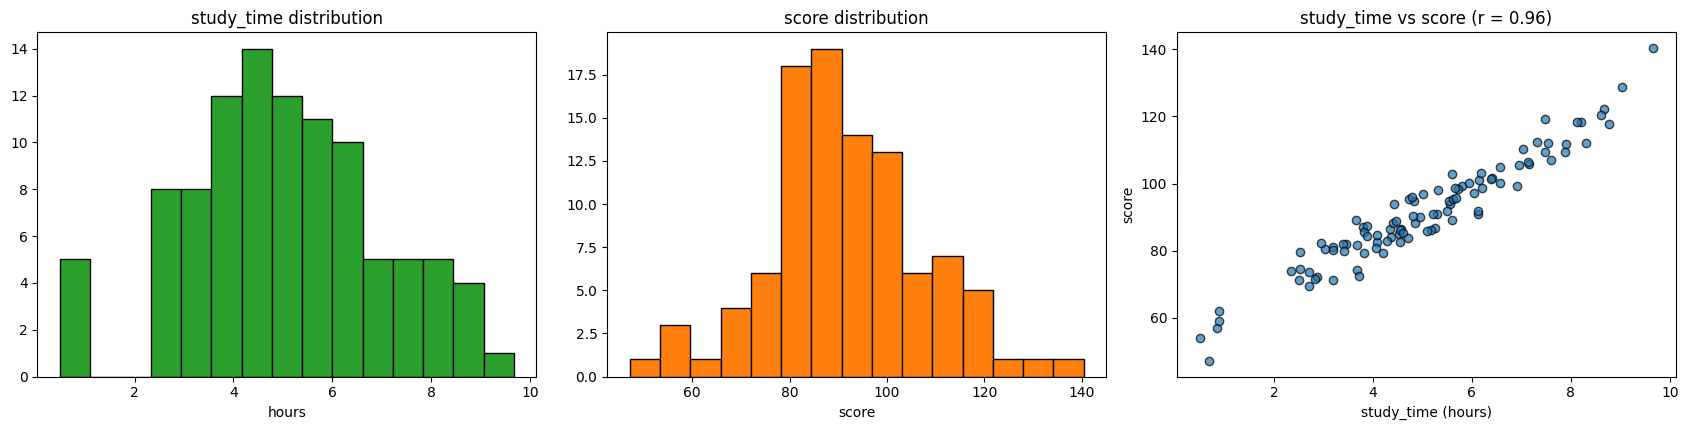

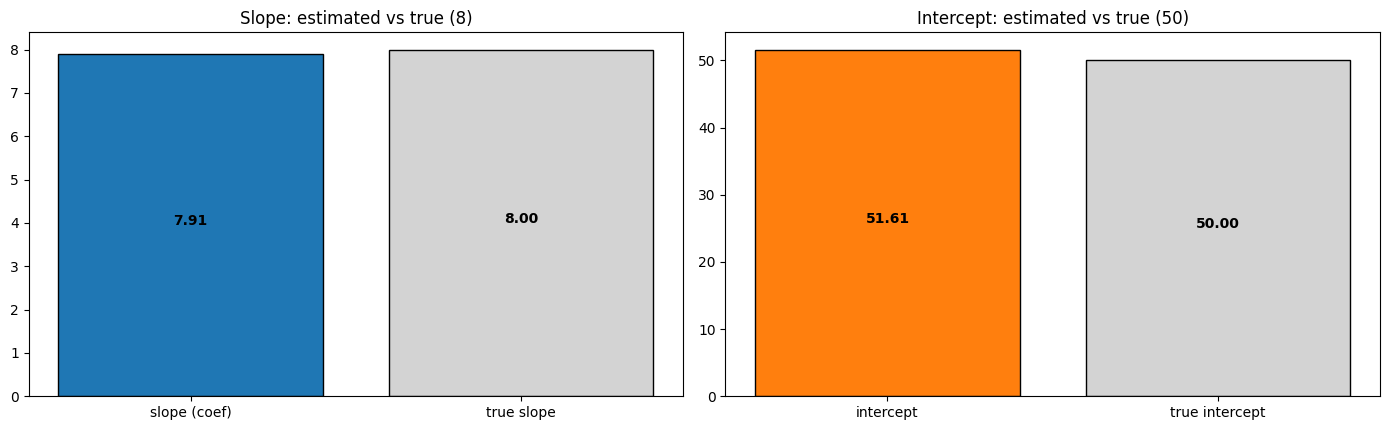

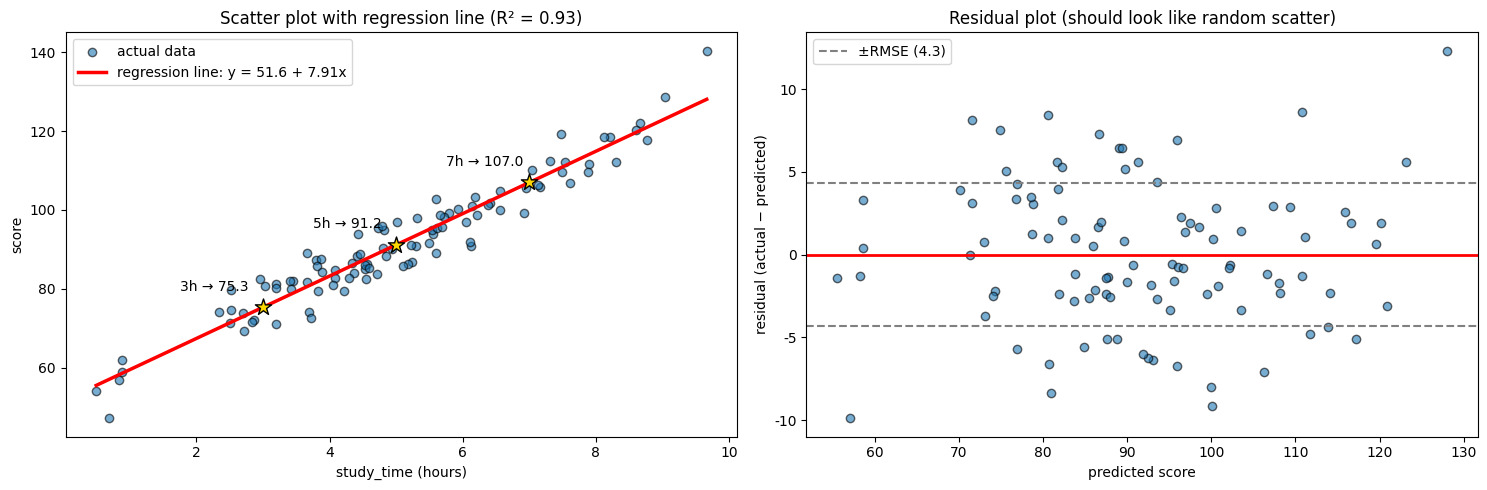

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

pd.set_option('display.width', 200)

# 데이터 생성
np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

# ═════════════════════════════════════════════
# 1. 공부 시간과 성적의 관계 분석
# ═════════════════════════════════════════════
header("1. 공부 시간(study_time)과 성적(score)간의 관계를 단순 선형 회귀모델로 분석합니다.")

r = df11['study_time'].corr(df11['score'])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].hist(df11['study_time'], bins=15, color='tab:green', edgecolor='black')
ax[0].set_title('study_time distribution')
ax[0].set_xlabel('hours')
ax[1].hist(df11['score'], bins=15, color='tab:orange', edgecolor='black')
ax[1].set_title('score distribution')
ax[1].set_xlabel('score')
ax[2].scatter(df11['study_time'], df11['score'], alpha=0.7, edgecolor='black')
ax[2].set_title(f'study_time vs score (r = {r:.2f})')
ax[2].set_xlabel('study_time (hours)')
ax[2].set_ylabel('score')
plt.tight_layout()
plt.show()

print(df11.describe().round(2))
print(f"""
[답] 학생 100명의 공부 시간과 성적 데이터입니다.
     · 공부 시간은 평균 {df11['study_time'].mean():.2f}시간(최소 {df11['study_time'].min():.2f} ~ 최대 {df11['study_time'].max():.2f}),
       성적은 평균 {df11['score'].mean():.1f}점(최소 {df11['score'].min():.1f} ~ 최대 {df11['score'].max():.1f})입니다.
     · 상관계수는 {r:.2f}이며 매우 강한 양의 상관입니다. 산점도에서도 점들이 오른쪽 위로 올라가는 직선 띠 모양입니다.
     · 관계가 직선에 가까우므로 '성적 = 절편 + 기울기 × 공부 시간' 형태의 단순 선형 회귀모델이 잘 맞을 것으로 예상됩니다.
       (여기서 공부 시간은 원인 쪽인 독립변수 X, 성적은 결과 쪽인 종속변수 y로 둡니다.)""")
over100 = (df11['score'] > 100).sum()
if over100:
    print(f"     · 참고: 이 데이터는 성적이 100점을 넘는 학생이 {over100}명 있습니다. 만점이 100점인 시험이라면 실제로는 나올 수 없는 값이지만,\n       연습용으로 만든 데이터라 그대로 분석합니다.")
if df11['study_time'].min() < 0:
    print(f"     · 참고: 정규분포로 만든 데이터라 공부 시간이 음수인 값({(df11['study_time'] < 0).sum()}개)이 섞여 있습니다. 실제 데이터라면 오류로 처리해야 합니다.")

# ═════════════════════════════════════════════
# 2. 모델 학습, 기울기와 절편 출력
# ═════════════════════════════════════════════
header("2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.")

X = df11[['study_time']]          # sklearn은 X를 2차원(표 형태)으로 받아야 함
y = df11['score']
model = LinearRegression()
model.fit(X, y)

slope, intercept = model.coef_[0], model.intercept_
pred = model.predict(X)
r2 = r2_score(y, pred)
rmse = np.sqrt(mean_squared_error(y, pred))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].bar(['slope (coef)', 'true slope'], [slope, 8], color=['tab:blue', 'lightgray'], edgecolor='black')
for i, v in enumerate([slope, 8]):
    ax[0].text(i, v / 2, f'{v:.2f}', ha='center', fontweight='bold')
ax[0].set_title('Slope: estimated vs true (8)')
ax[1].bar(['intercept', 'true intercept'], [intercept, 50], color=['tab:orange', 'lightgray'], edgecolor='black')
for i, v in enumerate([intercept, 50]):
    ax[1].text(i, v / 2, f'{v:.2f}', ha='center', fontweight='bold')
ax[1].set_title('Intercept: estimated vs true (50)')
plt.tight_layout()
plt.show()

print(f"기울기(계수) model.coef_      : {slope:.4f}")
print(f"절편        model.intercept_ : {intercept:.4f}")
print(f"결정계수 R²                  : {r2:.4f}")
print(f"평균 예측 오차 RMSE          : {rmse:.2f}점")
print(f"""
[답] 학습된 회귀식은  성적 = {intercept:.2f} + {slope:.2f} × 공부 시간  입니다.
     · 기울기 {slope:.2f}: 공부 시간이 1시간 늘 때마다 성적이 평균 약 {slope:.1f}점 오른다는 뜻입니다.
     · 절편 {intercept:.2f}: 공부 시간이 0시간일 때 예상 성적입니다. (기본 점수에 해당)
     · 데이터를 만들 때 쓴 실제 값(기울기 8, 절편 50)과 거의 같게 추정되었습니다.
       차이가 조금 나는 것은 성적에 더한 무작위 오차(표준편차 5) 때문입니다.
     · R²는 {r2:.2f}이며, 성적 차이의 약 {r2 * 100:.0f}%를 공부 시간으로 설명할 수 있습니다.
       예측값은 실제 성적과 평균 약 {rmse:.1f}점 정도 차이가 납니다 (RMSE).""")

# ═════════════════════════════════════════════
# 3. 산점도 위 회귀선 시각화
# ═════════════════════════════════════════════
header("3. 산점도 위에 회귀선을 시각화해 봅시다.")

x_line = np.linspace(df11['study_time'].min(), df11['study_time'].max(), 100).reshape(-1, 1)
y_line = model.predict(pd.DataFrame(x_line, columns=['study_time']))
examples = pd.DataFrame({'study_time': [3, 5, 7]})
ex_pred = model.predict(examples)
resid = y - pred

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(X, y, alpha=0.6, edgecolor='black', label='actual data')
ax[0].plot(x_line, y_line, color='red', lw=2.5, label=f'regression line: y = {intercept:.1f} + {slope:.2f}x')
for (_, row), p in zip(examples.iterrows(), ex_pred):
    ax[0].scatter(row['study_time'], p, color='gold', s=150, edgecolor='black', zorder=3, marker='*')
    ax[0].annotate(f'{row["study_time"]:.0f}h → {p:.1f}', (row['study_time'], p), textcoords='offset points',
                   xytext=(-60, 12))
ax[0].set_xlabel('study_time (hours)')
ax[0].set_ylabel('score')
ax[0].set_title(f'Scatter plot with regression line (R² = {r2:.2f})')
ax[0].legend(loc='upper left')

ax[1].scatter(pred, resid, alpha=0.6, edgecolor='black')
ax[1].axhline(0, color='red', lw=2)
ax[1].axhline(rmse, color='gray', linestyle='--', label=f'±RMSE ({rmse:.1f})')
ax[1].axhline(-rmse, color='gray', linestyle='--')
ax[1].set_xlabel('predicted score')
ax[1].set_ylabel('residual (actual − predicted)')
ax[1].set_title('Residual plot (should look like random scatter)')
ax[1].legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({'공부 시간': examples['study_time'], '예측 성적': ex_pred.round(1)}).to_string(index=False))
print(f"""
[답] 왼쪽 그래프의 빨간 직선이 학습된 회귀선입니다.
     · 점들이 회귀선 주위에 고르게 모여 있어, 직선 하나로 공부 시간과 성적의 관계를 잘 설명합니다.
     · 별 표시는 회귀식으로 예측한 값입니다. 예를 들어 하루 7시간 공부하면 약 {ex_pred[2]:.1f}점, 3시간이면 약 {ex_pred[0]:.1f}점으로 예측됩니다.
     · 오른쪽 잔차 그래프(실제 성적 − 예측 성적)는 점들이 0을 중심으로 위아래에 무작위로 흩어져 있어,
       직선 모델이 데이터에 적절하고 특별한 패턴(곡선 관계 등)을 놓치지 않았음을 보여 줍니다.
     · 다만 이 결과는 '공부 시간이 많은 학생이 성적도 높다'는 관계이지 인과관계 자체를 증명하는 것은 아니며,
       데이터 범위(약 {df11['study_time'].min():.0f}~{df11['study_time'].max():.0f}시간) 밖, 예를 들어 하루 20시간 공부 같은 경우에 그대로 적용하면 안 됩니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. 공부 시간이 성적에 어떤 영향을 주었나요?
2. 회귀선은 데이터를 잘 설명하고 있나요?
3. 이 회귀식을 현실에 적용할 수 있을까요?
4. 선형 회귀분석은 언제 활용할 수 있을까요?


══════════════════════════════════════════════════════════════════════
1. 공부 시간이 성적에 어떤 영향을 주었나요?
══════════════════════════════════════════════════════════════════════
               항목          값
             기울기        7.91
기울기 95% 신뢰구간 7.46 ~ 8.35
         기울기 p값     < 0.001
               절편       51.61

[답] 공부 시간이 늘수록 성적이 일정하게 오르는 뚜렷한 양(+)의 영향이 있었습니다.
  · 기울기가 7.91이므로 공부 시간이 1시간 늘 때마다 성적이 평균 약 7.9점 오릅니다.
    오른쪽 그래프처럼 2시간 → 4시간 → 6시간 → 8시간으로 늘 때마다 매번 약 15.8점씩 같은 폭으로 오릅니다.
  · 기울기의 95% 신뢰구간이 7.46 ~ 8.35로 0을 전혀 포함하지 않고, p값도 0.001보다 작아
    '공부 시간과 성적은 관계가 없다'는 가능성은 사실상 배제됩니다.
  · 절편 51.6점은 공부를 전혀 안 했을 때의 예상 성적으로, 기본 실력에 해당하는 값으로 볼 수 있습니다.

══════════════════════════════════════════════════════════════════════
2. 회귀선은 데이터를 잘 설명하고 있나요?
══════════════════════════════════════════════════════════════════════
                     지표             값
         R² (학습 데이터)          0.927
교차검증 R² (5-fold 평균) 0.908 (±0.045)
                     RMSE         4.33점
                잔차 평균           

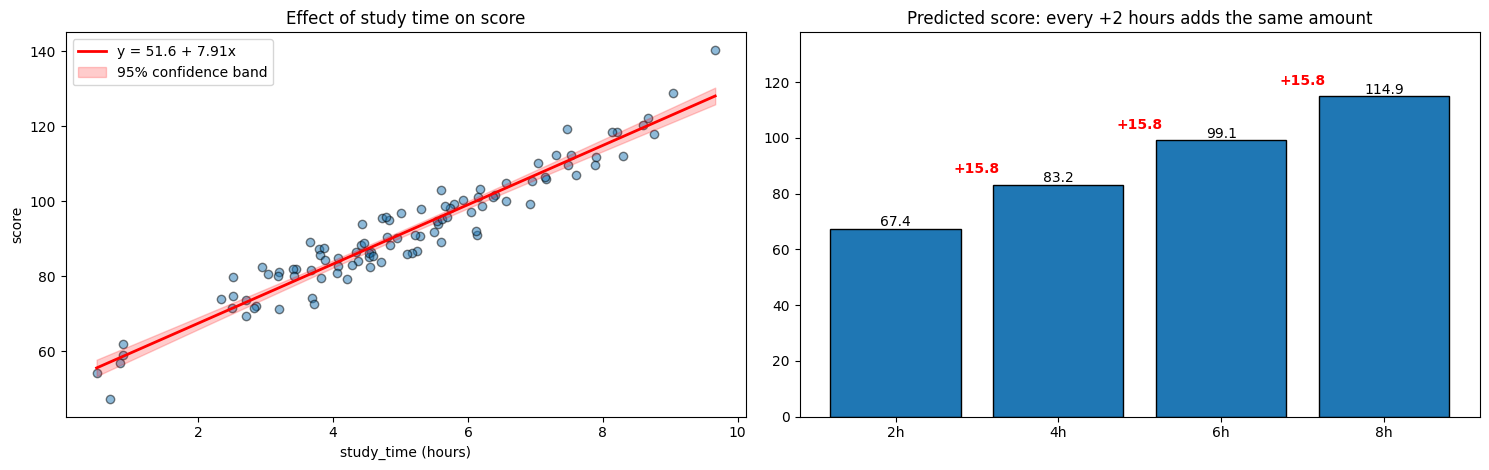

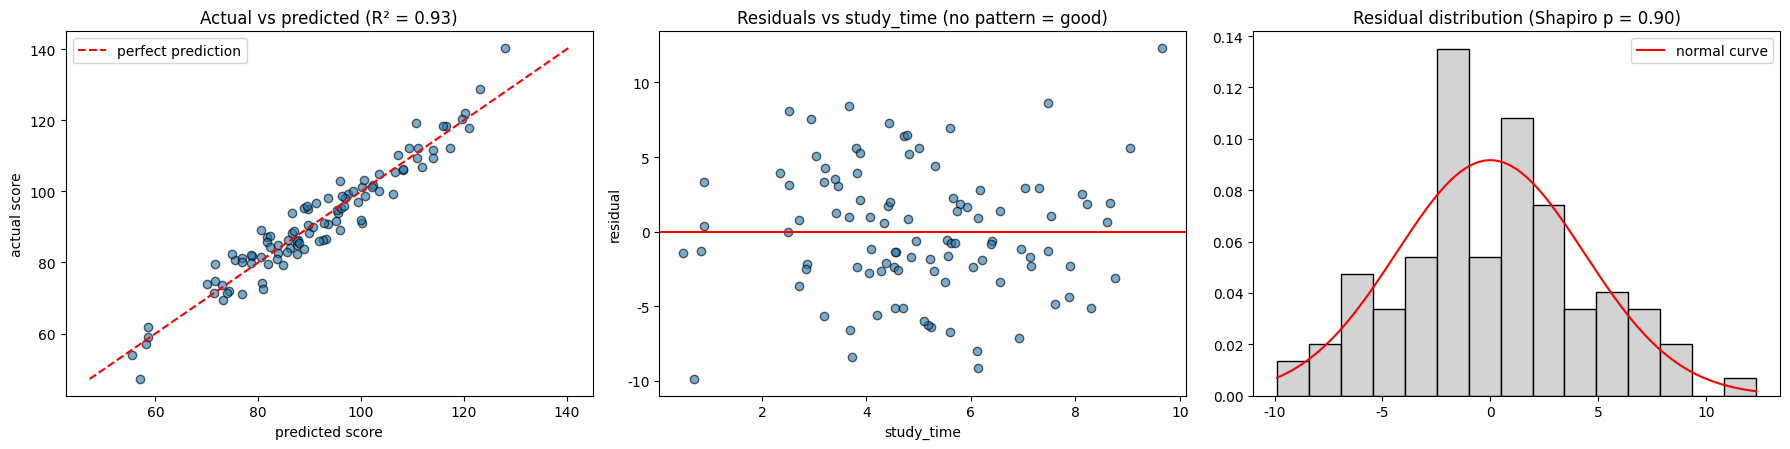

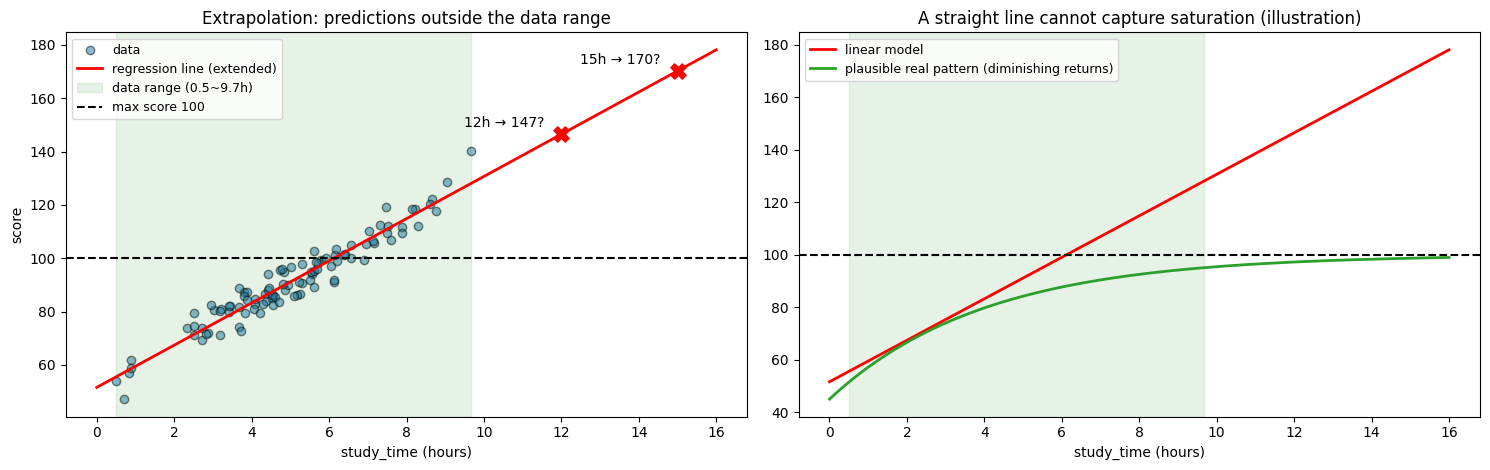

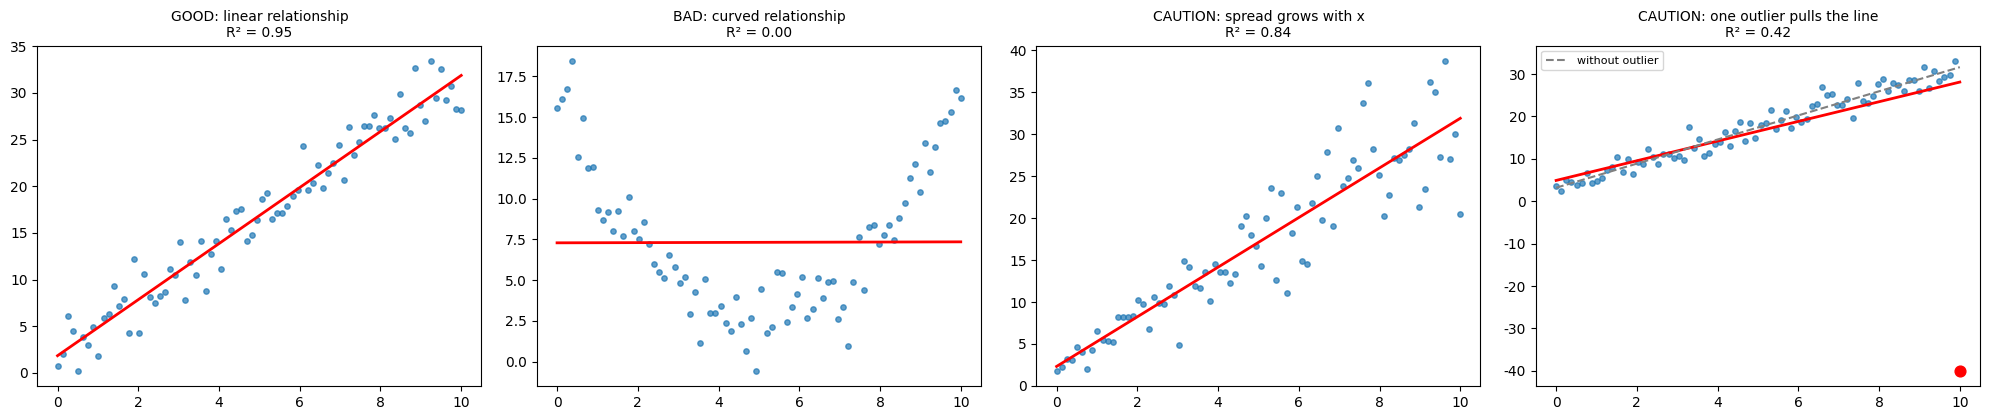

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import cross_val_score, KFold

pd.set_option('display.width', 200)

# 데이터 생성 (앞 문제와 같은 데이터)
np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

X, y = df11[['study_time']], df11['score']
model = LinearRegression().fit(X, y)
slope, intercept = model.coef_[0], model.intercept_
pred = model.predict(X)
resid = y - pred
n = len(df11)
r2 = r2_score(y, pred)
rmse = np.sqrt(mean_squared_error(y, pred))

# 기울기의 표준오차·95% 신뢰구간·p값 (단순회귀 공식)
x = df11['study_time'].values
s_err = np.sqrt((resid ** 2).sum() / (n - 2))
sxx = ((x - x.mean()) ** 2).sum()
se_slope = s_err / np.sqrt(sxx)
t_crit = stats.t.ppf(0.975, n - 2)
ci_lo, ci_hi = slope - t_crit * se_slope, slope + t_crit * se_slope
p_slope = 2 * (1 - stats.t.cdf(abs(slope / se_slope), n - 2))

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

def predict(h):
    return model.predict(pd.DataFrame({'study_time': np.atleast_1d(h)}))

# ═════════════════════════════════════════════
# 1. 공부 시간이 성적에 준 영향
# ═════════════════════════════════════════════
header("1. 공부 시간이 성적에 어떤 영향을 주었나요?")

xs = np.linspace(x.min(), x.max(), 100)
band = t_crit * s_err * np.sqrt(1 / n + (xs - x.mean()) ** 2 / sxx)   # 회귀선의 95% 신뢰대
hours = np.array([2, 4, 6, 8])
hp = predict(hours)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].scatter(x, y, alpha=0.5, edgecolor='black')
ax[0].plot(xs, predict(xs), color='red', lw=2, label=f'y = {intercept:.1f} + {slope:.2f}x')
ax[0].fill_between(xs, predict(xs) - band, predict(xs) + band, color='red', alpha=0.2, label='95% confidence band')
ax[0].set_xlabel('study_time (hours)')
ax[0].set_ylabel('score')
ax[0].set_title('Effect of study time on score')
ax[0].legend(loc='upper left')
bars = ax[1].bar([f'{h}h' for h in hours], hp, color='tab:blue', edgecolor='black')
for b, v in zip(bars, hp):
    ax[1].text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.1f}', ha='center')
for i in range(len(hours) - 1):
    ax[1].annotate(f'+{hp[i + 1] - hp[i]:.1f}', xy=(i + 0.5, (hp[i] + hp[i + 1]) / 2 + 12), ha='center', color='red', fontweight='bold')
ax[1].set_ylim(0, hp.max() * 1.2)
ax[1].set_title('Predicted score: every +2 hours adds the same amount')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'항목': ['기울기', '기울기 95% 신뢰구간', '기울기 p값', '절편'],
                    '값': [f'{slope:.2f}', f'{ci_lo:.2f} ~ {ci_hi:.2f}', ('< 0.001' if p_slope < 0.001 else f'{p_slope:.3f}'), f'{intercept:.2f}']}).to_string(index=False))
print(f"""
[답] 공부 시간이 늘수록 성적이 일정하게 오르는 뚜렷한 양(+)의 영향이 있었습니다.
  · 기울기가 {slope:.2f}이므로 공부 시간이 1시간 늘 때마다 성적이 평균 약 {slope:.1f}점 오릅니다.
    오른쪽 그래프처럼 2시간 → 4시간 → 6시간 → 8시간으로 늘 때마다 매번 약 {2 * slope:.1f}점씩 같은 폭으로 오릅니다.
  · 기울기의 95% 신뢰구간이 {ci_lo:.2f} ~ {ci_hi:.2f}로 0을 전혀 포함하지 않고, p값도 0.001보다 작아
    '공부 시간과 성적은 관계가 없다'는 가능성은 사실상 배제됩니다.
  · 절편 {intercept:.1f}점은 공부를 전혀 안 했을 때의 예상 성적으로, 기본 실력에 해당하는 값으로 볼 수 있습니다.""")

# ═════════════════════════════════════════════
# 2. 회귀선이 데이터를 잘 설명하는가
# ═════════════════════════════════════════════
header("2. 회귀선은 데이터를 잘 설명하고 있나요?")

cv = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0), scoring='r2')
shapiro_p = stats.shapiro(resid).pvalue

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].scatter(pred, y, alpha=0.6, edgecolor='black')
lims = [y.min(), y.max()]
ax[0].plot(lims, lims, color='red', linestyle='--', label='perfect prediction')
ax[0].set_xlabel('predicted score')
ax[0].set_ylabel('actual score')
ax[0].set_title(f'Actual vs predicted (R² = {r2:.2f})')
ax[0].legend()
ax[1].scatter(x, resid, alpha=0.6, edgecolor='black')
ax[1].axhline(0, color='red')
ax[1].set_xlabel('study_time')
ax[1].set_ylabel('residual')
ax[1].set_title('Residuals vs study_time (no pattern = good)')
ax[2].hist(resid, bins=15, density=True, color='lightgray', edgecolor='black')
rr = np.linspace(resid.min(), resid.max(), 200)
ax[2].plot(rr, stats.norm.pdf(rr, 0, resid.std()), color='red', label='normal curve')
ax[2].set_title(f'Residual distribution (Shapiro p = {shapiro_p:.2f})')
ax[2].legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({'지표': ['R² (학습 데이터)', '교차검증 R² (5-fold 평균)', 'RMSE', '잔차 평균', '잔차 정규성 검정 p값'],
                    '값': [f'{r2:.3f}', f'{cv.mean():.3f} (±{cv.std():.3f})', f'{rmse:.2f}점', f'{resid.mean():.2f}', f'{shapiro_p:.2f}']}).to_string(index=False))
print(f"""
[답] 네, 매우 잘 설명하고 있습니다.
  · 설명력: R²는 {r2:.2f}이며, 성적 차이의 약 {r2 * 100:.0f}%를 공부 시간 하나로 설명합니다.
    왼쪽 그래프에서 실제 성적과 예측 성적이 대각선(완벽한 예측) 주위에 촘촘히 모여 있습니다.
  · 예측 오차: RMSE가 {rmse:.1f}점으로, 예측이 평균적으로 약 {rmse:.0f}점 정도만 빗나갑니다 (성적 범위 약 {y.max() - y.min():.0f}점 대비 작은 값).
  · 새 데이터에도 통함: 데이터를 5조각으로 나눠 학습·평가를 번갈아 한 교차검증에서도 R²가 평균 {cv.mean():.2f}로 비슷해,
    학습한 데이터에만 맞춘 것이 아니라 처음 보는 학생에게도 잘 맞습니다.
  · 잔차 점검: 가운데 그래프에서 잔차가 0 주위에 패턴 없이 고르게 흩어져 있고(곡선 관계나 퍼짐 변화 없음),
    오른쪽 히스토그램도 정규분포 모양입니다 (정규성 검정 p = {shapiro_p:.2f}, 0.05보다 크면 정규분포로 봐도 무방).
    즉 선형 회귀의 기본 가정이 잘 지켜지고 있습니다.""")

# ═════════════════════════════════════════════
# 3. 현실 적용 가능성
# ═════════════════════════════════════════════
header("3. 이 회귀식을 현실에 적용할 수 있을까요?")

xe = np.linspace(0, 16, 200)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].scatter(x, y, alpha=0.5, edgecolor='black', label='data')
ax[0].plot(xe, predict(xe), color='red', lw=2, label='regression line (extended)')
ax[0].axvspan(x.min(), x.max(), color='green', alpha=0.1, label=f'data range ({x.min():.1f}~{x.max():.1f}h)')
ax[0].axhline(100, color='black', linestyle='--', label='max score 100')
for h in [12, 15]:
    ax[0].scatter(h, predict(h), color='red', s=120, marker='X', zorder=3)
    ax[0].annotate(f'{h}h → {predict(h)[0]:.0f}?', (h, predict(h)[0]), textcoords='offset points', xytext=(-70, 5))
ax[0].set_xlabel('study_time (hours)')
ax[0].set_ylabel('score')
ax[0].set_title('Extrapolation: predictions outside the data range')
ax[0].legend(loc='upper left', fontsize=9)

# 현실에서 흔한 모습(예시): 일정 시간이 지나면 효과가 줄어듦
real = 100 - 55 * np.exp(-0.25 * xe)
ax[1].plot(xe, predict(xe), color='red', lw=2, label='linear model')
ax[1].plot(xe, real, color='tab:green', lw=2, label='plausible real pattern (diminishing returns)')
ax[1].axvspan(x.min(), x.max(), color='green', alpha=0.1)
ax[1].axhline(100, color='black', linestyle='--')
ax[1].set_xlabel('study_time (hours)')
ax[1].set_title('A straight line cannot capture saturation (illustration)')
ax[1].legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print(f"""[답] 데이터 범위 안에서는 참고용으로 쓸 수 있지만, 그대로 현실에 적용하기에는 한계가 있습니다.
  · 범위 밖 예측(외삽) 주의: 이 데이터의 공부 시간은 {x.min():.1f}~{x.max():.1f}시간입니다.
    회귀식을 그대로 늘리면 12시간은 {predict(12)[0]:.0f}점, 15시간은 {predict(15)[0]:.0f}점으로 만점(100점)을 훌쩍 넘는 불가능한 값이 나옵니다.
    이미 데이터 안에서도 100점을 넘는 학생이 {(y > 100).sum()}명 있어, 실제 시험 점수라면 성립할 수 없는 데이터입니다.
  · 직선이 아닐 수 있음: 현실에서는 오른쪽 초록 곡선처럼 공부 시간이 늘수록 효과가 점점 줄어들거나(만점 상한, 피로),
    너무 오래 하면 오히려 떨어질 수도 있습니다. 직선 모델은 이런 변화를 표현하지 못합니다.
  · 인과관계 아님: 공부 시간이 긴 학생은 원래 성실하거나, 공부 방법이 좋거나, 환경이 좋을 수 있습니다.
    이런 숨은 요인(교란변수)을 고려하지 않았으므로 '공부를 1시간 더 시키면 무조건 {slope:.0f}점 오른다'고 단정할 수 없습니다.
  · 변수가 하나뿐: 실제 성적에는 수업 집중도, 수면, 선행 지식, 시험 난이도 등 많은 요인이 영향을 줍니다.
  · 이 데이터는 공식(50 + 8 × 공부 시간 + 오차)으로 만든 가상 데이터라 직선이 완벽하게 맞는 것입니다.

  현실에 적용하려면: 실제 학생 데이터를 모아 다시 학습하고, 데이터 범위 안에서만 예측하며,
  수면·출석 같은 변수를 함께 넣은 다중 회귀나 곡선 모델을 비교해 보는 것이 좋습니다.""")

# ═════════════════════════════════════════════
# 4. 선형 회귀분석의 활용
# ═════════════════════════════════════════════
header("4. 선형 회귀분석은 언제 활용할 수 있을까요?")

rng = np.random.default_rng(4)
xx = np.linspace(0, 10, 80)
cases = {
    'GOOD: linear relationship': 2 + 3 * xx + rng.normal(0, 2, 80),
    'BAD: curved relationship': 2 + 0.6 * (xx - 5) ** 2 + rng.normal(0, 1.5, 80),
    'CAUTION: spread grows with x': 2 + 3 * xx + rng.normal(0, 0.6 * xx + 0.3, 80),
    'CAUTION: one outlier pulls the line': np.r_[2 + 3 * xx[:-1] + rng.normal(0, 2, 79), -40],
}
fig, axs = plt.subplots(1, 4, figsize=(20, 4.3))
for a, (title, yy) in zip(axs, cases.items()):
    m = LinearRegression().fit(xx.reshape(-1, 1), yy)
    a.scatter(xx, yy, s=15, alpha=0.7)
    a.plot(xx, m.predict(xx.reshape(-1, 1)), color='red', lw=2)
    if 'outlier' in title:
        m2 = LinearRegression().fit(xx[:-1].reshape(-1, 1), yy[:-1])
        a.plot(xx, m2.predict(xx.reshape(-1, 1)), color='gray', linestyle='--', label='without outlier')
        a.scatter(xx[-1], yy[-1], color='red', s=60, zorder=3)
        a.legend(loc='upper left', fontsize=8)
    a.set_title(f'{title}\nR² = {m.score(xx.reshape(-1, 1), yy):.2f}', fontsize=10)
plt.tight_layout()
plt.show()

uses = pd.DataFrame({
    '분야': ['마케팅', '부동산', '제조', '경영', '의료·보건', '교육'],
    'X (원인·입력)': ['광고비', '면적·역까지 거리', '온도·압력', '매장 면적', '운동 시간', '공부 시간'],
    'y (결과·예측 대상)': ['매출', '집값', '불량률', '월 매출', '혈압', '성적'],
})
print(uses.to_string(index=False))
print("""
[답] 선형 회귀분석은 '숫자로 된 결과(y)가 다른 변수(X)에 따라 얼마나 변하는지'를 알고 싶을 때 씁니다.
  · 주로 하는 일
    - 관계의 크기 측정: '광고비를 100만 원 늘리면 매출이 얼마나 늘까?'처럼 기울기로 영향의 크기를 숫자로 보여 줍니다.
    - 예측: 면적으로 집값을, 기온으로 판매량을 예측합니다.
    - 요인 비교: 다중 회귀로 여러 변수를 함께 넣어, 어떤 요인이 결과에 더 크게 영향을 주는지 비교합니다.
  · 이럴 때 잘 맞습니다 (위 그래프의 첫 번째 경우)
    - y가 연속적인 숫자일 때 (성적, 매출, 가격 등)
    - X와 y의 관계가 대략 직선일 때 (산점도로 먼저 확인)
    - 잔차가 고르게 퍼져 있고, 극단적인 이상값이 없을 때
  · 이럴 때는 주의하거나 다른 방법을 씁니다
    - 관계가 곡선일 때 (두 번째 그래프): 다항 회귀나 변수 변환(로그 등)을 사용합니다.
    - x가 커질수록 퍼짐이 커질 때 (세 번째): 예측 오차가 구간마다 달라 로그 변환 등을 검토합니다.
    - 이상값이 있을 때 (네 번째): 점 하나가 회귀선을 끌어당기므로, 이상값을 먼저 확인합니다.
    - y가 '합격/불합격', '구매/비구매'처럼 범주일 때: 선형 회귀 대신 로지스틱 회귀를 씁니다.

  정리하면, 선형 회귀는 해석이 쉽고 빠른 기본 도구라서 데이터 분석의 첫 단계로 가장 많이 쓰이지만,
  산점도와 잔차를 먼저 확인해 직선 관계라는 가정이 맞는지 점검한 뒤 사용해야 합니다.""")

# 문제 12. A/B 테스트 해석

**📘 문제**

- 두 그룹의 전환율 차이를 계산하고 해석해봅시다.

In [27]:
# 데이터 생성
np.random.seed(606)
group_a = np.random.binomial(1, 0.12, 1000)
group_b = np.random.binomial(1, 0.15, 1000)

**📌 아래를 수행해 보세요:**

1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.
2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.
3. 이 차이가 우연인지, 의미 있는 차이인지 생각해 봅시다.


══════════════════════════════════════════════════════════════════════
1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.
══════════════════════════════════════════════════════════════════════
        전환(1)  미전환(0)  합계
A 그룹      131        869  1000
B 그룹      133        867  1000

[답] 각 그룹에 1,000명씩 있고, 값은 1(전환) 또는 0(미전환)인 이진 데이터입니다.
     · A 그룹: 1,000명 중 131명 전환
     · B 그룹: 1,000명 중 133명 전환
     오른쪽 그래프는 사용자가 쌓일수록 누적 전환율이 어떻게 변하는지 보여 줍니다.
     처음 몇십 명일 때는 크게 출렁이다가 사용자가 많아질수록 일정한 값으로 안정됩니다.
     그래서 A/B 테스트는 충분한 인원이 모일 때까지 기다린 뒤 판단해야 합니다.

══════════════════════════════════════════════════════════════════════
2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.
══════════════════════════════════════════════════════════════════════
        전환율(%) 95% 신뢰구간(%)
A 그룹       13.1     11.0 ~ 15.2
B 그룹       13.3     11.2 ~ 15.4

[답] · A 그룹 전환율: 131 ÷ 1000 = 13.1%
     · B 그룹 전환율: 133 ÷ 1000 = 13.3%
     · 차이(B − A): +0.2%p, A 대비 상대적으로 +1.5% 높습니다.
     · 차이의 95% 신뢰구간은 -2.8 ~ 3.2%p입니다.
       '%p(퍼센트포인트)'는 두 비율을 뺀 값이고, '%'는 A를 기준으로 몇 % 

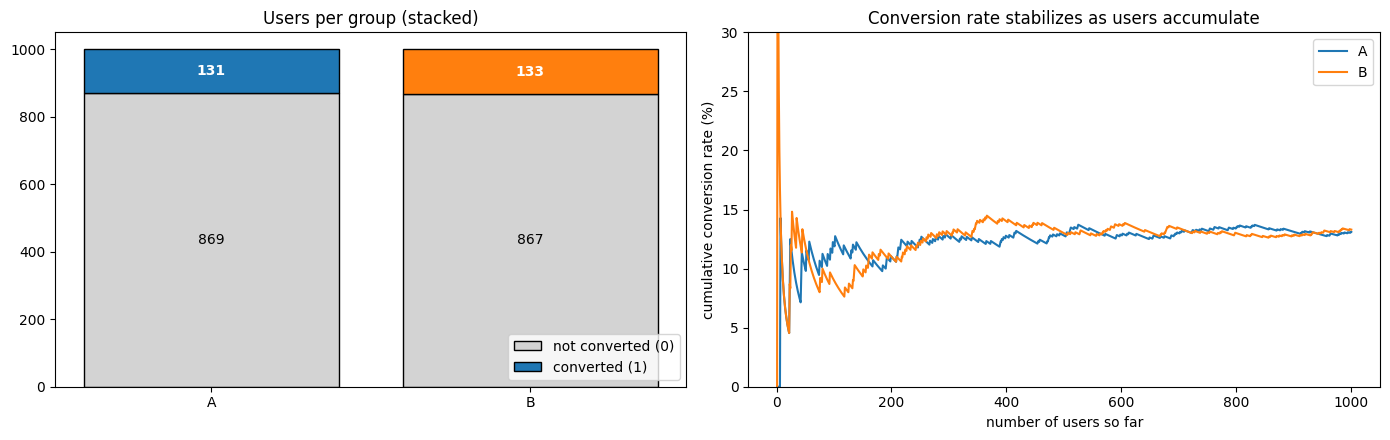

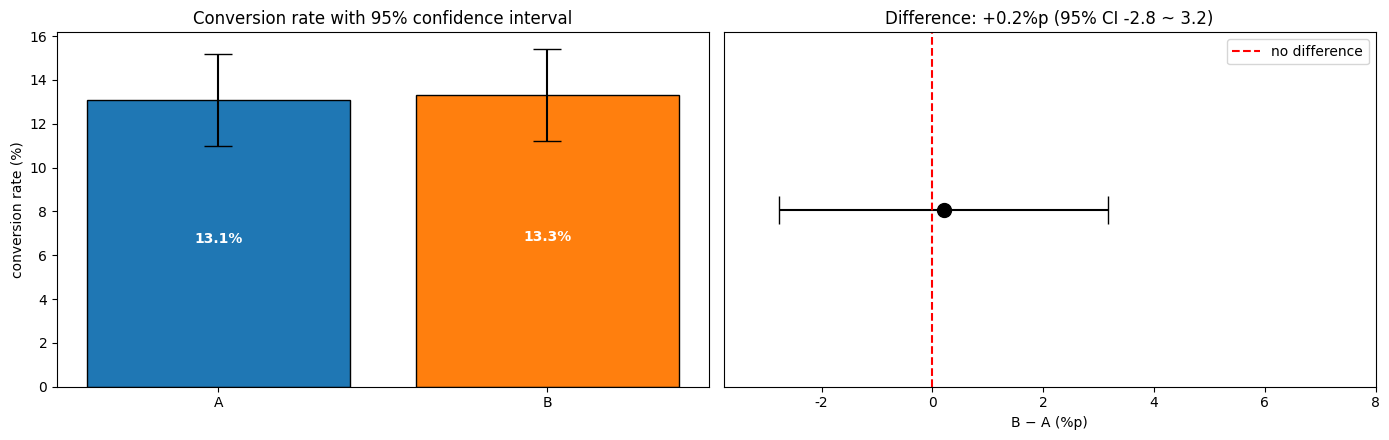

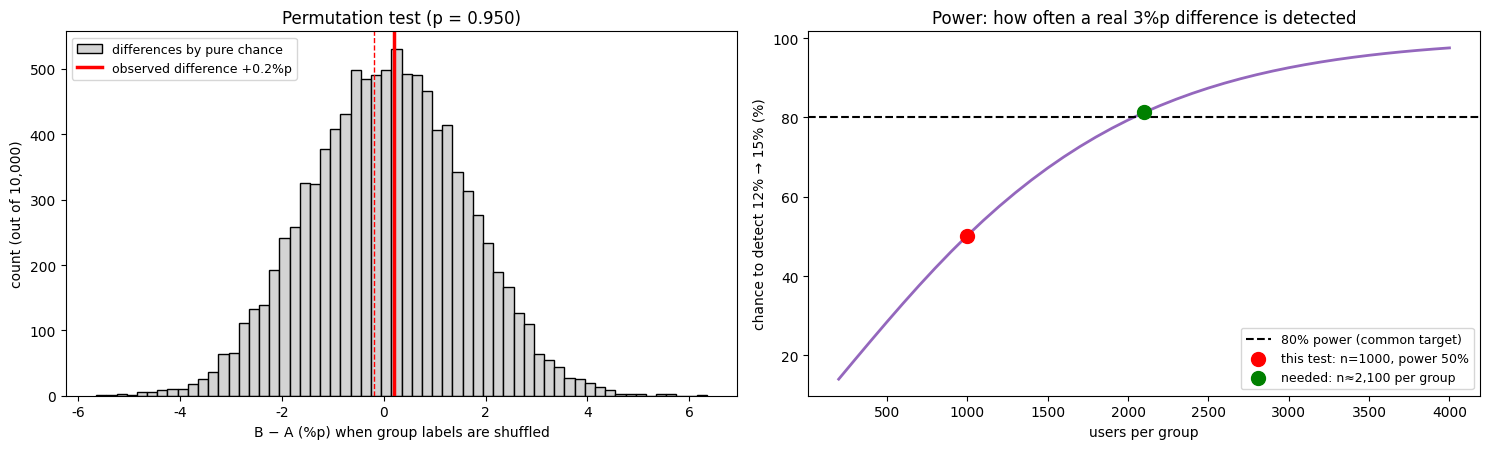

In [29]:
# ═══════════════ [셀 1] 준비 + 데이터 생성 ═══════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 200)

np.random.seed(606)
group_a = np.random.binomial(1, 0.12, 1000)   # 1 = 전환(구매 등), 0 = 미전환
group_b = np.random.binomial(1, 0.15, 1000)

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

n_a, n_b = len(group_a), len(group_b)
c_a, c_b = group_a.sum(), group_b.sum()
p_a, p_b = c_a / n_a, c_b / n_b

# ═══════════════ [셀 2] 1. 전환 데이터 살펴보기 ═══════════════
header("1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.")

table = pd.DataFrame({'전환(1)': [c_a, c_b], '미전환(0)': [n_a - c_a, n_b - c_b], '합계': [n_a, n_b]},
                     index=['A 그룹', 'B 그룹'])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(['A', 'B'], [n_a - c_a, n_b - c_b], color='lightgray', edgecolor='black', label='not converted (0)')
ax[0].bar(['A', 'B'], [c_a, c_b], bottom=[n_a - c_a, n_b - c_b], color=['tab:blue', 'tab:orange'],
          edgecolor='black', label='converted (1)')
for i, (c, n) in enumerate([(c_a, n_a), (c_b, n_b)]):
    ax[0].text(i, n - c / 2, f'{c}', ha='center', va='center', color='white', fontweight='bold')
    ax[0].text(i, (n - c) / 2, f'{n - c}', ha='center', va='center')
ax[0].set_title('Users per group (stacked)')
ax[0].legend(loc='lower right')
# 사용자 순서대로 누적 전환율이 어떻게 안정되는지
ax[1].plot(np.arange(1, n_a + 1), np.cumsum(group_a) / np.arange(1, n_a + 1) * 100, label='A', color='tab:blue')
ax[1].plot(np.arange(1, n_b + 1), np.cumsum(group_b) / np.arange(1, n_b + 1) * 100, label='B', color='tab:orange')
ax[1].set_ylim(0, 30)
ax[1].set_xlabel('number of users so far')
ax[1].set_ylabel('cumulative conversion rate (%)')
ax[1].set_title('Conversion rate stabilizes as users accumulate')
ax[1].legend()
plt.tight_layout()
plt.show()

print(table)
print(f"""
[답] 각 그룹에 1,000명씩 있고, 값은 1(전환) 또는 0(미전환)인 이진 데이터입니다.
     · A 그룹: 1,000명 중 {c_a}명 전환
     · B 그룹: 1,000명 중 {c_b}명 전환
     오른쪽 그래프는 사용자가 쌓일수록 누적 전환율이 어떻게 변하는지 보여 줍니다.
     처음 몇십 명일 때는 크게 출렁이다가 사용자가 많아질수록 일정한 값으로 안정됩니다.
     그래서 A/B 테스트는 충분한 인원이 모일 때까지 기다린 뒤 판단해야 합니다.""")

# ═══════════════ [셀 3] 2. 전환율과 차이 ═══════════════
header("2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.")

se_a, se_b = np.sqrt(p_a * (1 - p_a) / n_a), np.sqrt(p_b * (1 - p_b) / n_b)
diff = p_b - p_a
se_diff = np.sqrt(se_a ** 2 + se_b ** 2)
ci_diff = (diff - 1.96 * se_diff, diff + 1.96 * se_diff)
lift = diff / p_a * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
bars = ax[0].bar(['A', 'B'], [p_a * 100, p_b * 100], color=['tab:blue', 'tab:orange'], edgecolor='black',
                 yerr=[1.96 * se_a * 100, 1.96 * se_b * 100], capsize=10)
for b, p in zip(bars, [p_a, p_b]):
    ax[0].text(b.get_x() + b.get_width() / 2, p * 100 / 2, f'{p * 100:.1f}%', ha='center', color='white', fontweight='bold')
ax[0].set_ylabel('conversion rate (%)')
ax[0].set_title('Conversion rate with 95% confidence interval')
ax[1].errorbar([diff * 100], [0], xerr=[[diff * 100 - ci_diff[0] * 100], [ci_diff[1] * 100 - diff * 100]],
               fmt='o', color='black', capsize=10, markersize=10)
ax[1].axvline(0, color='red', linestyle='--', label='no difference')
ax[1].set_yticks([])
ax[1].set_xlim(min(-2, ci_diff[0] * 100 - 1), max(8, ci_diff[1] * 100 + 1))
ax[1].set_xlabel('B − A (%p)')
ax[1].set_title(f'Difference: {diff * 100:+.1f}%p (95% CI {ci_diff[0] * 100:.1f} ~ {ci_diff[1] * 100:.1f})')
ax[1].legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({'전환율(%)': [round(p_a * 100, 1), round(p_b * 100, 1)],
                        '95% 신뢰구간(%)': [f'{(p_a - 1.96 * se_a) * 100:.1f} ~ {(p_a + 1.96 * se_a) * 100:.1f}',
                                        f'{(p_b - 1.96 * se_b) * 100:.1f} ~ {(p_b + 1.96 * se_b) * 100:.1f}']},
                       index=['A 그룹', 'B 그룹'])
print(summary)
print(f"""
[답] · A 그룹 전환율: {c_a} ÷ {n_a} = {p_a * 100:.1f}%
     · B 그룹 전환율: {c_b} ÷ {n_b} = {p_b * 100:.1f}%
     · 차이(B − A): {diff * 100:+.1f}%p, A 대비 상대적으로 {lift:+.1f}% {'높습니다' if diff > 0 else '낮습니다'}.
     · 차이의 95% 신뢰구간은 {ci_diff[0] * 100:.1f} ~ {ci_diff[1] * 100:.1f}%p입니다.
       '%p(퍼센트포인트)'는 두 비율을 뺀 값이고, '%'는 A를 기준으로 몇 % 늘었는지를 뜻하니 구분해서 써야 합니다.""")

# ═══════════════ [셀 4] 3. 우연인가, 의미 있는 차이인가 ═══════════════
header("3. 이 차이가 우연인지, 의미 있는 차이인지 생각해 봅시다.")

# (1) 두 비율 z검정
p_pool = (c_a + c_b) / (n_a + n_b)
z = diff / np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
p_z = 2 * (1 - stats.norm.cdf(abs(z)))
# (2) 카이제곱 검정 (교차표)
chi2, p_chi, _, _ = stats.chi2_contingency([[c_a, n_a - c_a], [c_b, n_b - c_b]], correction=False)
# (3) 순열 검정: 그룹 이름을 무작위로 섞어도 이만한 차이가 자주 나오는지
rng = np.random.default_rng(0)
pooled = np.r_[group_a, group_b]
perm = np.empty(10000)
for i in range(10000):
    rng.shuffle(pooled)
    perm[i] = pooled[n_a:].mean() - pooled[:n_a].mean()
p_perm = np.mean(np.abs(perm) >= abs(diff))

# (4) 검정력: 실제 차이(12% vs 15%)가 있을 때, 그룹당 인원에 따라 차이를 잡아낼 확률
def power(n, p1=0.12, p2=0.15):
    se_ = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    return 1 - stats.norm.cdf(1.96 - (p2 - p1) / se_)
ns = np.arange(200, 4001, 100)
pw = power(ns) * 100
n80 = int(ns[np.argmax(pw >= 80)])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].hist(perm * 100, bins=np.arange(perm.min() * 100 - 0.05, perm.max() * 100 + 0.25, 0.2), color='lightgray', edgecolor='black', label='differences by pure chance')
ax[0].axvline(diff * 100, color='red', lw=2.5, label=f'observed difference {diff * 100:+.1f}%p')
ax[0].axvline(-diff * 100, color='red', lw=1, linestyle='--')
ax[0].set_xlabel('B − A (%p) when group labels are shuffled')
ax[0].set_ylabel('count (out of 10,000)')
ax[0].set_title(f'Permutation test (p = {p_perm:.3f})')
ax[0].legend(loc='upper left', fontsize=9)
ax[1].plot(ns, pw, color='tab:purple', lw=2)
ax[1].axhline(80, color='black', linestyle='--', label='80% power (common target)')
ax[1].scatter([n_a], [power(n_a) * 100], color='red', s=100, zorder=3, label=f'this test: n={n_a}, power {power(n_a) * 100:.0f}%')
ax[1].scatter([n80], [power(n80) * 100], color='green', s=100, zorder=3, label=f'needed: n≈{n80:,} per group')
ax[1].set_xlabel('users per group')
ax[1].set_ylabel('chance to detect 12% → 15% (%)')
ax[1].set_title('Power: how often a real 3%p difference is detected')
ax[1].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

result = pd.DataFrame({'검정 방법': ['두 비율 z검정', '카이제곱 검정', '순열 검정 (10,000번)'],
                       '통계량': [f'z = {z:.2f}', f'χ² = {chi2:.2f}', '-'],
                       'p값': [round(p_z, 4), round(p_chi, 4), round(p_perm, 4)]})
print(result.to_string(index=False))
sig = p_z < 0.05
pmin, pmax = min(p_z, p_perm), max(p_z, p_perm)
print(f"""
[답] {'우연으로 보기 어려운, 통계적으로 의미 있는 차이입니다.' if sig else '이 데이터만으로는 우연과 구별할 수 없는 차이입니다.'}
  · 생각하는 방법: 'A와 B의 실제 전환율이 같다'고 가정했을 때(귀무가설), 지금만큼의 차이가 우연히 나올 확률(p값)을 계산합니다.
  · 왼쪽 그래프는 A와 B의 이름표를 무작위로 섞어 10,000번 다시 나눴을 때 생기는 차이의 분포입니다.
    회색은 '아무 효과가 없어도 우연히 생기는 차이'이고, 빨간 선이 실제로 관찰된 차이({diff * 100:+.1f}%p)입니다.
    섞었을 때도 이만큼 이상 차이가 나는 경우가 {p_perm * 100:.1f}%나 됩니다.
  · 세 가지 검정의 p값이 {pmin:.3f} ~ {pmax:.3f}로 {'0.05보다 작아서, B의 전환율이 A보다 높다고 판단할 수 있습니다.' if sig else '0.05보다 훨씬 커서, 차이가 우연히 생겼다고 봐도 이상하지 않습니다.'}
  · 차이의 95% 신뢰구간({ci_diff[0] * 100:.1f} ~ {ci_diff[1] * 100:.1f}%p){'이 0을 포함하지 않는 것도' if ci_diff[0] > 0 else '이 0을 포함하는 것도'} 같은 결론을 보여 줍니다.""")

if sig:
    print(f"""
  다만 함께 생각할 점
  · p값이 작다는 것은 '차이가 있다'는 뜻이지 '차이가 크다'는 뜻이 아닙니다. {diff * 100:+.1f}%p가 비용 대비 의미 있는지는 사업적으로 판단해야 합니다.
  · 미리 정한 인원이 모이기 전에 결과를 보고 멈추거나, 여러 지표를 동시에 검정하면 우연한 '유의미'가 늘어나므로 주의해야 합니다.""")
else:
    print(f"""
  그런데 흥미로운 점이 있습니다
  · 이 데이터는 실제 전환율을 A 12%, B 15%로 설정해서 만든 것이라, 진짜로 3%p 차이가 있습니다.
    그런데 이번 표본에서는 A가 우연히 높게({p_a * 100:.1f}%), B가 우연히 낮게({p_b * 100:.1f}%) 나와서 차이가 거의 사라졌습니다.
  · 즉 '차이가 없다'가 아니라 '이 인원으로는 차이를 확인하지 못했다'가 정확한 결론입니다 (2종 오류, 놓침).
  · 오른쪽 그래프처럼, 실제 차이가 12% → 15%일 때 그룹당 1,000명으로는 이를 잡아낼 확률(검정력)이 약 {power(n_a) * 100:.0f}%뿐입니다.
    동전 던지기와 비슷한 확률이라 이번처럼 놓치는 일이 흔합니다.
  · 80% 확률로 차이를 잡아내려면 그룹당 약 {n80:,}명이 필요합니다. 테스트 전에 필요한 인원을 먼저 계산하고 시작해야 하는 이유입니다.
  · 따라서 결론은 'B가 효과 없음'이 아니라 '판단 보류, 더 많은 사용자로 테스트를 이어가야 함'입니다.""")

**🧠 데이터를 어떻게 읽을까요?**

1. 두 그룹의 전환율 차이는 얼마나 되나요?
2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?
4. A/B 테스트는 현실에서 어떻게 쓰일까요?


══════════════════════════════════════════════════════════════════════
1. 두 그룹의 전환율 차이는 얼마나 되나요?
══════════════════════════════════════════════════════════════════════
        전환 수  전체  전환율(%)
A 그룹      131  1000       13.1
B 그룹      133  1000       13.3

[답] A 그룹 13.1%, B 그룹 13.3%로, B가 +0.2%p (A 대비 +1.5%) 높습니다.
     · 1,000명 기준으로 환산하면 B에서 2명 더 전환한 정도로, 아주 작은 차이입니다.
     · 하지만 표본에서 얻은 값이라 오차가 있습니다. 차이의 95% 신뢰구간은 -2.8 ~ 3.2%p로,
       실제 차이는 'B가 약 3%p 낮을 수도, 약 3%p 높을 수도 있는' 넓은 범위 안에 있습니다.
     · 참고로 데이터를 만들 때 쓴 실제 차이는 +3%p(12% → 15%)였는데, 이번 표본에서는 우연히 +0.2%p로 작게 관측되었습니다.

══════════════════════════════════════════════════════════════════════
2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
══════════════════════════════════════════════════════════════════════
[답] '의미 있다'에는 두 가지 뜻이 있고, 둘을 구분해야 합니다.

  ① 통계적으로 의미 있다 (statistically significant)
  · 'A와 B가 사실 같다'고 가정했을 때, 지금만큼 큰 차이가 우연히 나올 확률(p값)이 아주 작다는 뜻입니다.
    보통 p값이 0.05(5%)보다 작으면 '우연으로 보기 어렵다 = 통계적으로 의미 있다'고 판단합니다.
  · 왼쪽 그래프에서 A와 B가 같아도 우연히 ±3.0%p 정도의 차이

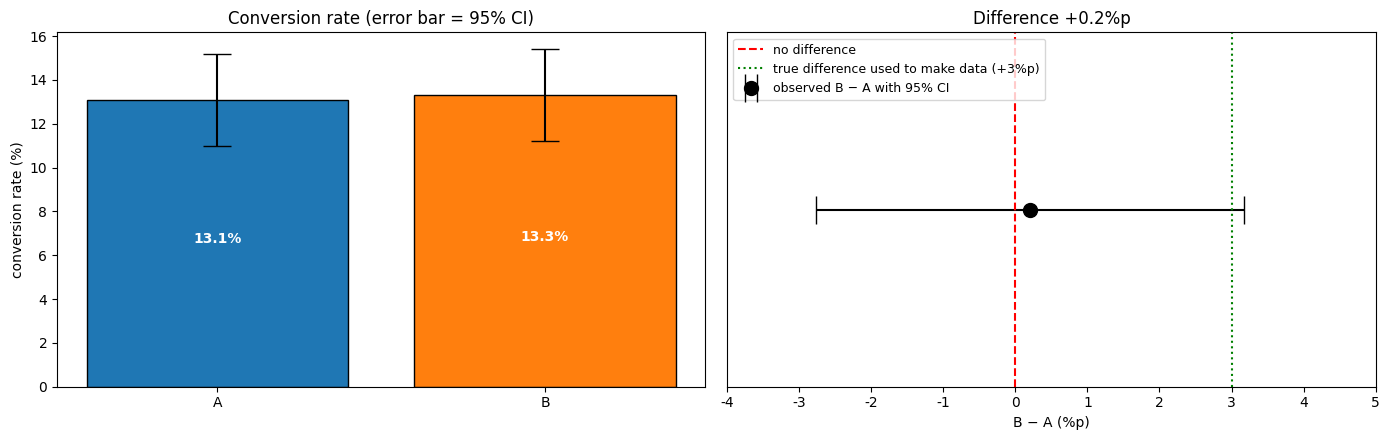

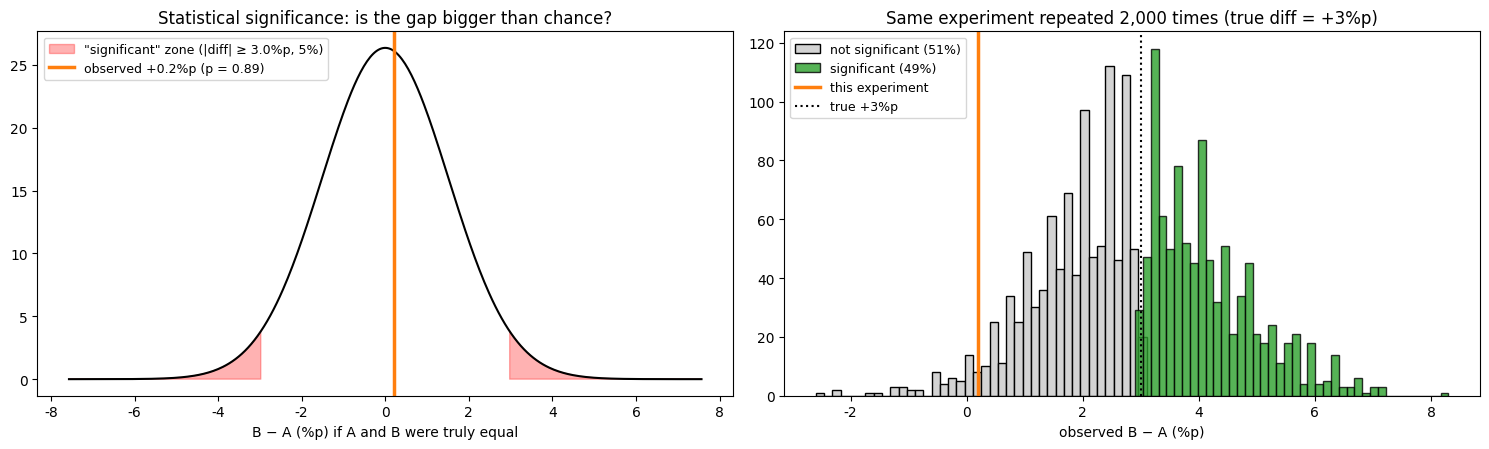

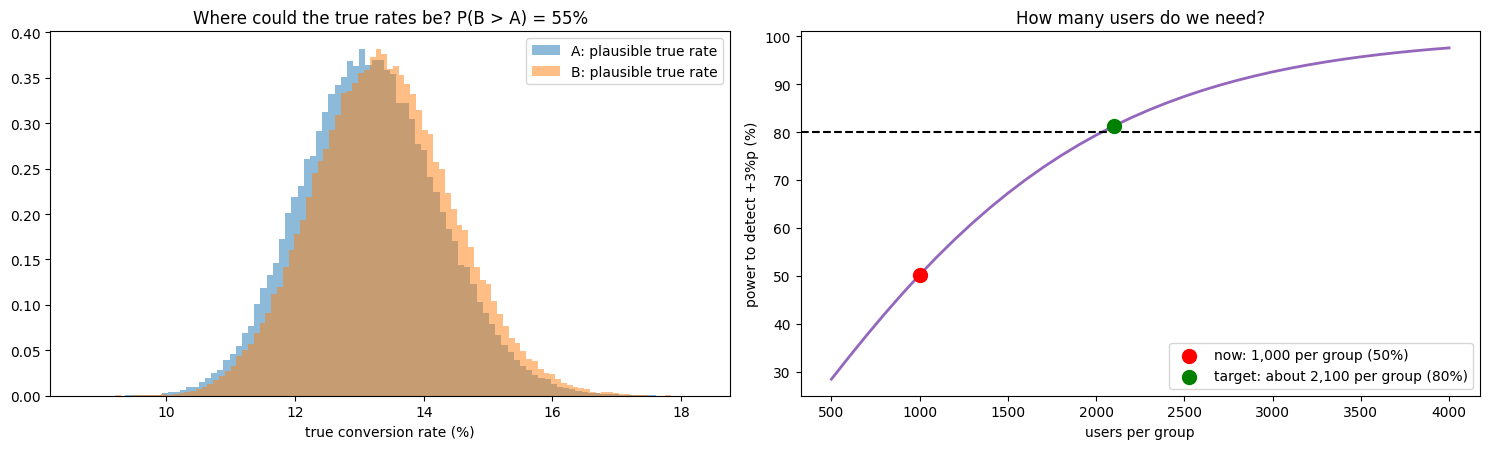

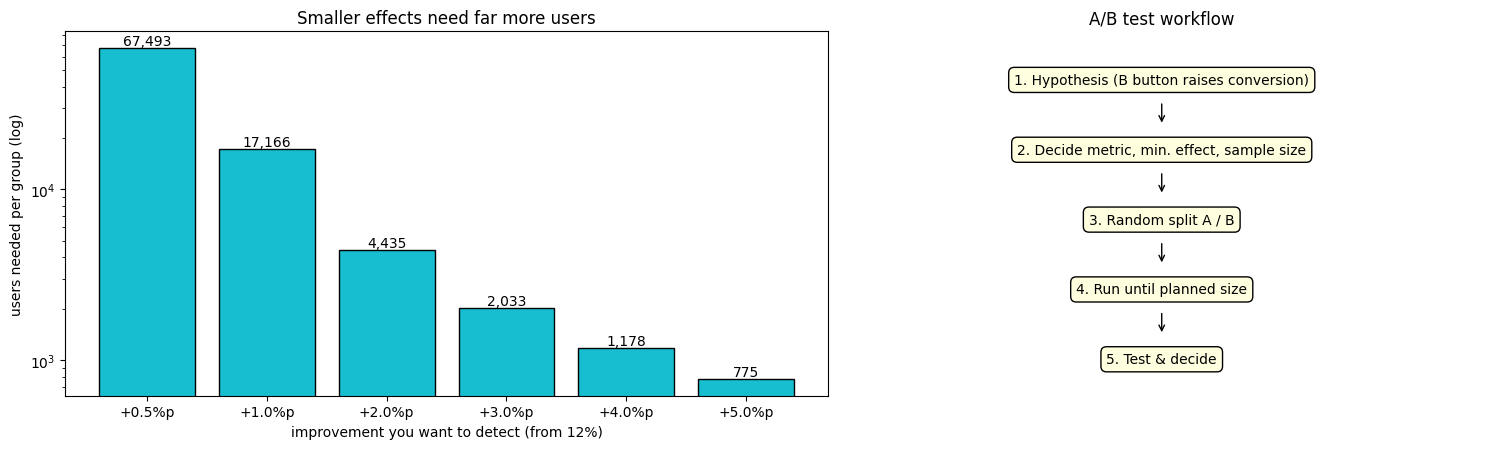

In [30]:
# ═══════════════ [셀 1] 준비 + 데이터 생성 (앞 문제와 같은 데이터) ═══════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 200)

np.random.seed(606)
group_a = np.random.binomial(1, 0.12, 1000)   # 1 = 전환, 0 = 미전환
group_b = np.random.binomial(1, 0.15, 1000)

n_a, n_b = len(group_a), len(group_b)
c_a, c_b = group_a.sum(), group_b.sum()
p_a, p_b = c_a / n_a, c_b / n_b
diff = p_b - p_a
se_a, se_b = np.sqrt(p_a * (1 - p_a) / n_a), np.sqrt(p_b * (1 - p_b) / n_b)
se_diff = np.sqrt(se_a ** 2 + se_b ** 2)
ci = (diff - 1.96 * se_diff, diff + 1.96 * se_diff)
p_pool = (c_a + c_b) / (n_a + n_b)
se_null = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
z = diff / se_null
p_value = 2 * (1 - stats.norm.cdf(abs(z)))
sig = p_value < 0.05

def header(title):
    print("\n" + "═" * 70)
    print(title)
    print("═" * 70)

def power(n, p1=0.12, p2=0.15):
    s = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    return 1 - stats.norm.cdf(1.96 - (p2 - p1) / s)

# ═══════════════ [셀 2] 1. 전환율 차이 ═══════════════
header("1. 두 그룹의 전환율 차이는 얼마나 되나요?")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
bars = ax[0].bar(['A', 'B'], [p_a * 100, p_b * 100], color=['tab:blue', 'tab:orange'], edgecolor='black',
                 yerr=[1.96 * se_a * 100, 1.96 * se_b * 100], capsize=10)
for b, p in zip(bars, [p_a, p_b]):
    ax[0].text(b.get_x() + b.get_width() / 2, p * 50, f'{p * 100:.1f}%', ha='center', color='white', fontweight='bold')
ax[0].set_ylabel('conversion rate (%)')
ax[0].set_title('Conversion rate (error bar = 95% CI)')
ax[1].errorbar([diff * 100], [0], xerr=[[(diff - ci[0]) * 100], [(ci[1] - diff) * 100]],
               fmt='o', color='black', capsize=10, markersize=10, label='observed B − A with 95% CI')
ax[1].axvline(0, color='red', linestyle='--', label='no difference')
ax[1].axvline(3, color='green', linestyle=':', label='true difference used to make data (+3%p)')
ax[1].set_yticks([])
ax[1].set_xlim(min(-4, ci[0] * 100 - 1), max(5, ci[1] * 100 + 1))
ax[1].set_xlabel('B − A (%p)')
ax[1].set_title(f'Difference {diff * 100:+.1f}%p')
ax[1].legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print(pd.DataFrame({'전환 수': [c_a, c_b], '전체': [n_a, n_b], '전환율(%)': [round(p_a * 100, 1), round(p_b * 100, 1)]},
                   index=['A 그룹', 'B 그룹']))
print(f"""
[답] A 그룹 {p_a * 100:.1f}%, B 그룹 {p_b * 100:.1f}%로, B가 {diff * 100:+.1f}%p (A 대비 {diff / p_a * 100:+.1f}%) {'높습니다' if diff > 0 else '낮습니다'}.
     · 1,000명 기준으로 환산하면 B에서 {abs(c_b - c_a)}명 {'더' if diff > 0 else '덜'} 전환한 정도로, 아주 작은 차이입니다.
     · 하지만 표본에서 얻은 값이라 오차가 있습니다. 차이의 95% 신뢰구간은 {ci[0] * 100:.1f} ~ {ci[1] * 100:.1f}%p로,
       실제 차이는 'B가 약 {abs(ci[0]) * 100:.0f}%p 낮을 수도, 약 {ci[1] * 100:.0f}%p 높을 수도 있는' 넓은 범위 안에 있습니다.
     · 참고로 데이터를 만들 때 쓴 실제 차이는 +3%p(12% → 15%)였는데, 이번 표본에서는 우연히 {diff * 100:+.1f}%p로 작게 관측되었습니다.""")

# ═══════════════ [셀 3] 2. '의미 있다'의 뜻 ═══════════════
header("2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?")

# (1) A와 B가 같다고 가정했을 때(귀무가설) 차이의 분포
xs = np.linspace(-5 * se_null, 5 * se_null, 400)
# (2) 실제 차이가 3%p일 때 같은 실험을 2,000번 반복하면?
rng = np.random.default_rng(1)
sim_a = rng.binomial(n_a, 0.12, 2000) / n_a
sim_b = rng.binomial(n_b, 0.15, 2000) / n_b
sim_diff = sim_b - sim_a
pp = (sim_a + sim_b) / 2
sim_sig = np.abs(sim_diff / np.sqrt(pp * (1 - pp) * 2 / n_a)) > 1.96

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(xs * 100, stats.norm.pdf(xs, 0, se_null), color='black')
crit = 1.96 * se_null
ax[0].fill_between(xs * 100, stats.norm.pdf(xs, 0, se_null), where=np.abs(xs) >= crit, color='red', alpha=0.3,
                   label=f'"significant" zone (|diff| ≥ {crit * 100:.1f}%p, 5%)')
ax[0].axvline(diff * 100, color='tab:orange', lw=2.5, label=f'observed {diff * 100:+.1f}%p (p = {p_value:.2f})')
ax[0].set_xlabel('B − A (%p) if A and B were truly equal')
ax[0].set_title('Statistical significance: is the gap bigger than chance?')
ax[0].legend(loc='upper left', fontsize=9)
ax[1].hist(sim_diff[~sim_sig] * 100, bins=40, color='lightgray', edgecolor='black', label=f'not significant ({(~sim_sig).mean() * 100:.0f}%)')
ax[1].hist(sim_diff[sim_sig] * 100, bins=40, color='tab:green', edgecolor='black', alpha=0.8, label=f'significant ({sim_sig.mean() * 100:.0f}%)')
ax[1].axvline(diff * 100, color='tab:orange', lw=2.5, label='this experiment')
ax[1].axvline(3, color='black', linestyle=':', label='true +3%p')
ax[1].set_xlabel('observed B − A (%p)')
ax[1].set_title('Same experiment repeated 2,000 times (true diff = +3%p)')
ax[1].legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print(f"""[답] '의미 있다'에는 두 가지 뜻이 있고, 둘을 구분해야 합니다.

  ① 통계적으로 의미 있다 (statistically significant)
  · 'A와 B가 사실 같다'고 가정했을 때, 지금만큼 큰 차이가 우연히 나올 확률(p값)이 아주 작다는 뜻입니다.
    보통 p값이 0.05(5%)보다 작으면 '우연으로 보기 어렵다 = 통계적으로 의미 있다'고 판단합니다.
  · 왼쪽 그래프에서 A와 B가 같아도 우연히 ±{crit * 100:.1f}%p 정도의 차이는 흔히 생깁니다.
    빨간 영역(5%) 밖으로 나가야 의미 있다고 보는데, 이번 차이({diff * 100:+.1f}%p, p = {p_value:.2f})는 한가운데 있어 {'의미 있는 차이입니다.' if sig else '의미 있다고 할 수 없습니다.'}
  · 주의: '의미 없음'이 '차이가 없음'을 증명하는 것은 아닙니다. 오른쪽 그래프처럼 실제로 3%p 차이가 있어도,
    1,000명씩 실험하면 약 {sim_sig.mean() * 100:.0f}%만 의미 있게 나오고 나머지는 이번처럼 놓칩니다 (검정력 약 {power(n_a) * 100:.0f}%).

  ② 실질적으로 의미 있다 (practically significant)
  · 차이가 사업적으로 가치가 있을 만큼 큰가의 문제입니다.
    예를 들어 사용자가 100만 명이면 0.2%p 차이도 통계적으로 의미 있게 나올 수 있지만, 그 차이가 변경 비용보다 작다면 실익이 없습니다.
  · 그래서 실험 전에 '최소 몇 %p 이상 올라야 바꿀 가치가 있다'(최소 효과 크기)를 먼저 정해 두는 것이 좋습니다.""")

# ═══════════════ [셀 4] 3. 어떤 결정을 내릴 수 있나 ═══════════════
header("3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?")

# 베이지안 관점: 지금까지 데이터로 볼 때 B가 A보다 좋을 확률
rng = np.random.default_rng(2)
post_a = rng.beta(1 + c_a, 1 + n_a - c_a, 100000)
post_b = rng.beta(1 + c_b, 1 + n_b - c_b, 100000)
prob_b_better = (post_b > post_a).mean()
ns = np.arange(500, 4001, 100)
n80 = int(ns[np.argmax(power(ns) >= 0.8)])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].hist(post_a * 100, bins=100, density=True, alpha=0.5, color='tab:blue', label='A: plausible true rate')
ax[0].hist(post_b * 100, bins=100, density=True, alpha=0.5, color='tab:orange', label='B: plausible true rate')
ax[0].set_xlabel('true conversion rate (%)')
ax[0].set_title(f'Where could the true rates be? P(B > A) = {prob_b_better * 100:.0f}%')
ax[0].legend()
ax[1].plot(ns, power(ns) * 100, color='tab:purple', lw=2)
ax[1].axhline(80, color='black', linestyle='--')
ax[1].scatter([n_a], [power(n_a) * 100], color='red', s=100, zorder=3, label=f'now: {n_a:,} per group ({power(n_a) * 100:.0f}%)')
ax[1].scatter([n80], [power(n80) * 100], color='green', s=100, zorder=3, label=f'target: about {n80:,} per group (80%)')
ax[1].set_xlabel('users per group')
ax[1].set_ylabel('power to detect +3%p (%)')
ax[1].set_title('How many users do we need?')
ax[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

decision = pd.DataFrame({
    '선택지': ['B로 전면 교체', 'A 유지, 실험 종료', '실험 연장 (권장)'],
    '근거': [f'B가 더 좋을 확률 {prob_b_better * 100:.0f}%', '통계적으로 차이 없음',
             f'검정력 {power(n_a) * 100:.0f}%로 판단하기에 데이터 부족'],
    '위험': ['효과 없는 변경에 비용 낭비', '실제로 좋은 B를 버릴 수 있음', '시간이 더 걸림'],
})
print(decision.to_string(index=False))
print(f"""
[답] {'B가 더 좋다고 결론 내리고 적용을 검토할 수 있습니다.' if sig else '지금은 결론을 내리기 이르며, 실험을 연장하는 것이 가장 합리적인 결정입니다.'}
  · 왼쪽 그래프는 지금까지의 데이터로 볼 때 A와 B의 실제 전환율이 있을 법한 범위입니다.
    두 분포가 거의 겹쳐 있어, B가 A보다 좋을 확률은 약 {prob_b_better * 100:.0f}%로 동전 던지기 수준입니다.
  · 'B가 효과 없다'고 결론 내리는 것도 위험합니다. 현재 인원으로는 실제 3%p 개선이 있어도 절반 정도는 놓치기 때문입니다.
  · 따라서 권장 결정은
    1) 그룹당 약 {n80:,}명이 될 때까지 실험을 이어가고 (오른쪽 그래프, 검정력 80% 기준)
    2) 미리 정한 인원이 모인 뒤 한 번에 판단하며 (중간에 결과를 자주 보고 멈추면 오판이 늘어남)
    3) 그래도 차이가 없다면, B가 비용이 적게 드는 변경일 때만 선택하고, 아니면 A를 유지합니다.
  · 만약 B 적용 비용이 거의 없고 위험도 낮다면, '손해 볼 가능성이 낮으니 B로 간다'는 사업적 판단도 가능하지만,
    이때도 효과가 검증된 것은 아니라는 점을 기록해 두어야 합니다.""")

# ═══════════════ [셀 5] 4. 현실에서의 A/B 테스트 ═══════════════
header("4. A/B 테스트는 현실에서 어떻게 쓰일까요?")

# 기준 전환율 12%에서, 찾고 싶은 개선 폭(최소 효과)에 따라 필요한 그룹당 인원
def need_n(p1, lift_pp, power_=0.8, alpha=0.05):
    p2 = p1 + lift_pp
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power_)
    return int(np.ceil((za + zb) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / lift_pp ** 2))
lifts = np.array([0.5, 1, 2, 3, 4, 5]) / 100
needs = [need_n(0.12, l) for l in lifts]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.2, 1]})
bars = ax[0].bar([f'+{l * 100:.1f}%p' for l in lifts], needs, color='tab:cyan', edgecolor='black')
for b, v in zip(bars, needs):
    ax[0].text(b.get_x() + b.get_width() / 2, v, f'{v:,}', ha='center', va='bottom')
ax[0].set_yscale('log')
ax[0].set_xlabel('improvement you want to detect (from 12%)')
ax[0].set_ylabel('users needed per group (log)')
ax[0].set_title('Smaller effects need far more users')
# A/B 테스트 진행 순서
steps = ['1. Hypothesis\n(B button raises\nconversion)', '2. Decide metric,\nmin. effect,\nsample size', '3. Random split\nA / B', '4. Run until\nplanned size', '5. Test &\ndecide']
ax[1].axis('off')
ax[1].set_xlim(0, 10)
ax[1].set_ylim(0, 6)
for i, s in enumerate(steps):
    y = 5.2 - i * 1.15
    ax[1].text(5, y, s.replace('\n', ' '), ha='center', va='center', fontsize=10,
               bbox=dict(boxstyle='round,pad=0.4', fc='lightyellow', ec='black'))
    if i < len(steps) - 1:
        ax[1].annotate('', xy=(5, y - 0.75), xytext=(5, y - 0.35), arrowprops=dict(arrowstyle='->'))
ax[1].set_title('A/B test workflow')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'찾고 싶은 개선 폭': [f'12% → {12 + l * 100:.1f}%' for l in lifts], '그룹당 필요 인원': [f'{v:,}명' for v in needs]}).to_string(index=False))
print("""
[답] A/B 테스트는 '바꿔 보면 더 좋아질까?'를 감이 아니라 데이터로 확인하는 방법으로, 여러 분야에서 쓰입니다.
  · 웹·앱 화면: 구매 버튼 색과 문구, 상품 상세 페이지 구성, 회원가입 단계 수
  · 마케팅: 이메일 제목(열람률), 광고 이미지·문구(클릭률), 할인 쿠폰 금액(구매 전환율)
  · 가격·상품: 가격대별 구매율, 무료 체험 기간 7일 vs 14일, 구독 요금제 구성
  · 추천·검색: 넷플릭스·유튜브·쇼핑몰의 추천 알고리즘 변경 효과 측정
  · 오프라인: 매장 진열 방식, 메뉴판 구성, 콜센터 응대 스크립트

  현실에서 지켜야 할 점
  · 실험 전에 설계: 가설, 핵심 지표(전환율 등), 최소 효과 크기, 필요한 인원을 먼저 정합니다.
    왼쪽 그래프처럼 작은 개선(+0.5%p)을 찾으려면 그룹당 수만 명이 필요해, 트래픽이 적은 서비스는 큰 변화만 검증할 수 있습니다.
  · 무작위 배정: 사용자를 무작위로 A/B에 나눠야 두 그룹이 비슷해지고, 차이를 변경 효과로 볼 수 있습니다.
  · 중간에 자주 보고 멈추지 않기: 유의미하게 나오는 순간 멈추면 우연한 차이를 효과로 착각하기 쉽습니다.
  · 여러 지표 동시 검정 주의: 지표를 20개 보면 그중 하나는 우연히 '유의미'하게 나올 수 있습니다.
  · 충분한 기간: 요일·주말 차이와 '새것이라 눌러 보는' 신기 효과가 사라질 만큼 최소 1~2주 이상 진행합니다.
  · 통계적 + 실질적 판단: p값과 함께 개선 폭이 비용 대비 가치 있는지 함께 봅니다.""")